# Diabetic Retinopathy Grading for Early Disease Detection in Africa

| Field | Detail |
|-------|--------|
| **Dataset** | APTOS 2019 Blindness Detection (Kaggle) |
| **Task** | 5-class ordinal DR severity grading (grades 0–4) |
| **Assignment** | Academic ML Summative — 60 points |
| **Primary metric** | Quadratic Weighted Kappa |
| **Date** | 2026-06-08 |

---

> **Deployment.** This notebook trained the model served by the MLOps app in this repository (`models/exp5_base.keras`, Exp 5). **Section 14**, at the end, evaluates that exact file on the held-out test set with the app's own code and demonstrates the prediction function. Sections 2.3, 2.4, 4.1, 5.1 and 14 were executed on 26 November 2026 without re-running any training.

## Mission Context

Sub-Saharan Africa faces a compounding healthcare crisis at the intersection of
diabetes prevalence and ophthalmology scarcity. The International Diabetes
Federation (*IDF Diabetes Atlas*, 10th ed.) projects a **143% rise** in diabetes
cases across the region by 2045 — the steepest projected growth of any global
region. Yet specialist ophthalmologist density remains below **1 per million
people** in many African countries, meaning early-stage diabetic retinopathy
(DR) — which is asymptomatic and fully treatable — routinely goes undetected
until vision loss is irreversible.

Portable smartphone-mounted fundus cameras (under USD 500) are now deployable
by community health workers (CHWs) without specialist training. An automated DR
grading model embedded in this workflow could triage patients before referral,
catching vision-threatening grades 3 and 4 before they cause permanent blindness.
This project demonstrates the technical feasibility of such a model using the
APTOS 2019 retinal screening dataset.

## Clinical Framing — Why Recall on Grades 3 and 4 is the Priority

DR severity follows an **ordinal scale**: grades 0 → 4 represent increasing
retinal damage from no disease to proliferative DR with active neovascularisation.

| Grade | Label | Clinical meaning | Urgency |
|-------|-------|------------------|---------|
| 0 | No DR | Healthy retina | Routine annual screening |
| 1 | Mild DR | Microaneurysms only | 6-month follow-up |
| 2 | Moderate DR | More lesions, no proliferation | 3-month follow-up |
| 3 | Severe DR | Extensive haemorrhage | Urgent referral |
| 4 | Proliferative DR | Active neovascularisation | Emergency treatment |

**In this project, a false negative on grade 3 or 4 is clinically more harmful
than a false positive.** A model that achieves 60% accuracy by predicting grade 0
for every patient is worse than useless as a screening tool — it provides false
reassurance for patients who need emergency care.

Consequently:
- **Primary metric:** Quadratic Weighted Kappa — penalises large ordinal errors
  proportional to their severity; corrects for chance agreement.
- **Secondary clinical metric:** Grade 3+4 Recall — tracked for every experiment
  and highlighted in all results tables.
- Every modelling decision (class weighting, SMOTE, augmentation) is evaluated
  against whether it improves detection of vision-threatening disease.

## Table of Contents

| Phase | Sections | Content |
|-------|----------|---------|
| **0 — Foundation** | 0, 1, 1.5, 1.6 | Setup · data acquisition · helper functions |
| **1 — EDA** | 2, 3 | Exploration · stratified splits |
| **2 — Preprocessing** | 4, 5, 6 | Ben Graham · augmentation · feature extraction |
| **3 — Traditional ML** | 7 | Experiments 1–3 (Logistic Regression, SVM, Random Forest) |
| **4 — Sequential DL** | 8 | Experiments 4–6 (minimal CNN → deep CNN → preprocessed) |
| **5 — Functional API** | 9 | Experiments 7–8 (multi-scale · hyperparameter search) |
| **6 — Reporting** | 10–13 | Results table · visualisations · analysis · conclusions |
| **7 — Deployment** | 14 | Deployed model: held-out evaluation · prediction functions |

---
# Section 1 — Environment Setup and Reproducibility

All random seeds are set here before any data split or model call.  
TensorFlow non-determinism sources (cuDNN, parallel ops) may cause minor
run-to-run variation even with seeds fixed; `enable_op_determinism` is
enabled where the TF version supports it.

In [1]:
# ── Package installation ───────────────────────────────────────────────────
# Uncomment the line(s) relevant to your environment.

# Local (install missing packages only):
# !pip install tensorflow==2.15.0 scikit-learn==1.4.2 scikit-image==0.22.0
# !pip install imbalanced-learn==0.12.3 opencv-python==4.9.0.80
# !pip install numpy==1.26.4 pandas==2.2.2 matplotlib==3.8.4 seaborn==0.13.2
# !pip install tqdm==4.66.4 ipywidgets==8.1.2

# Google Colab (these are not pre-installed):
# !pip install -q kagglehub imbalanced-learn scikit-image


In [2]:
# ── Standard library ───────────────────────────────────────────────────────
import os
import sys
import random
import zipfile
import subprocess
import time
from pathlib import Path

# ── Data and numerics ─────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ─────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Progress ──────────────────────────────────────────────────────────────
from tqdm.notebook import tqdm

# ── Scikit-learn ──────────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, roc_auc_score, roc_curve, auc,
    cohen_kappa_score, accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

# ── Imbalanced-learn ──────────────────────────────────────────────────────
from imblearn.over_sampling import SMOTE

# ── Scikit-image ──────────────────────────────────────────────────────────
from skimage.feature import hog, local_binary_pattern
from skimage.filters import gabor
from skimage.color import rgb2gray

# ── OpenCV ────────────────────────────────────────────────────────────────
import cv2

# ── TensorFlow / Keras ────────────────────────────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)

print('All imports successful.')
print(f'NumPy      {np.__version__}')
print(f'Pandas     {pd.__version__}')
print(f'TensorFlow {tf.__version__}')
print(f'OpenCV     {cv2.__version__}')

2026-06-20 19:38:43.431842: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781984323.592009      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781984323.638272      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781984324.009628      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781984324.009690      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781984324.009692      58 computation_placer.cc:177] computation placer alr

All imports successful.
NumPy      2.4.6
Pandas     2.3.3
TensorFlow 2.19.0
OpenCV     4.13.0


In [3]:
# ── set_seeds — defined here so the call on the next line works before
#    Section 1.6 is run. Section 1.6 Cell 2 re-defines it identically.
def set_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    try:
        tf.config.experimental.enable_op_determinism()
        print(f'Seeds set to {seed}. TF op determinism ENABLED.')
    except Exception:
        print(f'Seeds set to {seed}. TF op determinism not available on this version.')

set_seeds(42)

Seeds set to 42. TF op determinism ENABLED.


In [4]:
# ── Path constants — all derived from PROJECT_ROOT ────────────────────────
IN_COLAB  = 'google.colab' in sys.modules
IN_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IN_KAGGLE:
    # /kaggle/input/ is READ-ONLY — only TRAIN_IMAGES_DIR and TRAIN_CSV live there.
    # Everything else (features, models, outputs) goes to writable /kaggle/working/.
    KAGGLE_INPUT     = Path('/kaggle/input/aptos2019-blindness-detection')
    PROJECT_ROOT     = Path('/kaggle/working')
    DATA_DIR         = PROJECT_ROOT / 'data'
    RAW_DIR          = DATA_DIR / 'raw'               # writable; used for makedirs
    TRAIN_IMAGES_DIR = KAGGLE_INPUT / 'train_images'  # read-only input
    TRAIN_CSV        = KAGGLE_INPUT / 'train.csv'     # read-only input
    PROCESSED_DIR    = DATA_DIR / 'processed'
elif IN_COLAB:
    PROJECT_ROOT     = Path('/content/diabetic-retinopathy-detection')
    DATA_DIR         = PROJECT_ROOT / 'data'
    RAW_DIR          = DATA_DIR / 'raw'
    TRAIN_IMAGES_DIR = RAW_DIR / 'train_images'
    TRAIN_CSV        = RAW_DIR / 'train.csv'
    PROCESSED_DIR    = DATA_DIR / 'processed'
else:
    _here = Path(globals().get('__file__', '.')).resolve()
    PROJECT_ROOT = _here.parent if _here.suffix == '.py' else Path.cwd()
    if PROJECT_ROOT.name in ('notebooks', 'notebook'):
        PROJECT_ROOT = PROJECT_ROOT.parent
    DATA_DIR         = PROJECT_ROOT / 'data'
    RAW_DIR          = DATA_DIR / 'raw'
    TRAIN_IMAGES_DIR = RAW_DIR / 'train_images'
    TRAIN_CSV        = RAW_DIR / 'train.csv'
    PROCESSED_DIR    = DATA_DIR / 'processed'

FEATURES_DIR = PROCESSED_DIR / 'features'
SPLITS_DIR   = PROCESSED_DIR / 'splits'
MODELS_DIR   = PROJECT_ROOT / 'models'
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'

CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

_env = 'Kaggle' if IN_KAGGLE else ('Google Colab' if IN_COLAB else 'Local Jupyter')
print(f'Environment  : {_env}')
print(f'Project root : {PROJECT_ROOT}')
if IN_KAGGLE:
    print(f'Input data   : {KAGGLE_INPUT}')
    print(f'Writable root: {PROJECT_ROOT}')


Environment  : Kaggle
Project root : /kaggle/working
Input data   : /kaggle/input/aptos2019-blindness-detection
Writable root: /kaggle/working


In [5]:
# ── TensorFlow version + GPU detection ────────────────────────────────────
print(f'TensorFlow version: {tf.__version__}')
gpus = tf.config.list_physical_devices('GPU')
print(f'GPUs available    : {gpus}')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print('Memory growth enabled for all GPUs.')
    except RuntimeError as e:
        print(f'GPU config error: {e}')
else:
    print('No GPU detected — training will run on CPU (slower for DL experiments).')

TensorFlow version: 2.19.0
GPUs available    : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Memory growth enabled for all GPUs.


---
# Section 1.5 — Data Acquisition

This section is **fully self-contained and idempotent** — re-running it is safe
and skips any download step if the dataset is already present.

Data is loaded via **`kagglehub`** on all platforms — no Drive upload needed.

---

## Option 1 — Kaggle Notebooks *(recommended — zero setup)*

1. [kaggle.com](https://www.kaggle.com) → **Create** → **New Notebook**
2. **File → Import Notebook** → upload `diabetic_retinopathy_detection.ipynb`
3. Right panel → **Add Data** → search `aptos2019-blindness-detection` → **Add**
4. **Settings** → **Accelerator** → **GPU P100**
5. **Run All** — Cell 4 detects Kaggle and skips the download automatically

---

## Option 2 — Google Colab *(no Drive upload — uses kagglehub)*

1. Accept competition rules at `kaggle.com/competitions/aptos2019-blindness-detection`
2. Get API token: `kaggle.com` → Settings → API → **Create New Token** → downloads `kaggle.json`
3. In Colab: click the **🔑 icon** (left sidebar) → Secrets → add:
   - `KAGGLE_USERNAME` — your Kaggle username
   - `KAGGLE_KEY` — the `key` value from `kaggle.json`
4. Enable **notebook access** for both secrets
5. **Run All** — Cell 2 loads credentials; Cell 4 downloads directly (~1.5 GB, once)

> **Re-runs:** kagglehub caches the download at `~/.cache/kagglehub/`. The 1.5 GB
> download only happens on the first run per Colab session.

---

## Option 3 — Local Jupyter

Place `kaggle.json` at `~/.kaggle/kaggle.json` (`chmod 600`). Cell 4 downloads
automatically, or manually place `train_images/` and `train.csv` in `data/raw/`
and skip to Cell 5.


In [6]:
# ── Cell 2 — Kaggle credentials for kagglehub ─────────────────────────────
# On Kaggle kernels the kernel's own identity is used — no setup needed.
# On Colab, credentials must be stored in Colab Secrets (🔑 icon).
# On local Jupyter, kaggle.json must be at ~/.kaggle/kaggle.json.

if IN_KAGGLE:
    print('Kaggle kernel — authentication is automatic.')

elif IN_COLAB:
    _n_existing = len(list(TRAIN_IMAGES_DIR.glob('*.png'))) if TRAIN_IMAGES_DIR.exists() else 0
    if _n_existing > 3000:
        print(f'Dataset already present ({_n_existing} images) — skipping credential load.')
    else:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
            os.environ['KAGGLE_KEY']      = userdata.get('KAGGLE_KEY')
            print('Kaggle credentials loaded from Colab Secrets.')
        except Exception as _e:
            raise RuntimeError(
                'Failed to load Kaggle credentials from Colab Secrets.\n'
                'Add KAGGLE_USERNAME and KAGGLE_KEY via the 🔑 icon (left sidebar)\n'
                'and enable notebook access for both secrets.'
            ) from _e

else:
    _kj = Path.home() / '.kaggle' / 'kaggle.json'
    if not _kj.exists():
        raise FileNotFoundError(
            f'kaggle.json not found at {_kj}\n'
            'Download from kaggle.com/settings → API → Create New Token\n'
            'then: mv ~/Downloads/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json'
        )
    print(f'kaggle.json present at {_kj}')


Kaggle kernel — authentication is automatic.


In [7]:
# ── Cell 3 — Copy pre-extracted features from Drive (optional, Colab only) ─
# Only relevant if you previously uploaded data/processed/ to Google Drive.
# Safe to skip — Section 6 re-extracts features and caches them locally.
if IN_KAGGLE:
    print('Kaggle kernel — skipping Drive feature copy.')
else:
    import shutil
    _drive_proc = Path('/content/drive/MyDrive/aptos2019/processed')
    _local_proc = TRAIN_IMAGES_DIR.parent.parent / 'processed'
    if IN_COLAB and _drive_proc.exists() and not _local_proc.exists():
        from google.colab import drive as _drv
        _drv.mount('/content/drive', force_remount=False)
        print('Copying pre-extracted features from Drive ...')
        shutil.copytree(str(_drive_proc), str(_local_proc))
        print('Done — Section 6 will skip feature extraction.')
    elif _local_proc.exists():
        print('Processed features already present locally — skipping copy.')
    else:
        print('No Drive feature cache found — Section 6 will run feature extraction.')


Kaggle kernel — skipping Drive feature copy.


In [8]:
# ── Cell 3 — Create full directory structure (idempotent) ─────────────────
_dirs = [
    TRAIN_IMAGES_DIR,
    RAW_DIR,
    FEATURES_DIR / 'train',
    FEATURES_DIR / 'val',
    FEATURES_DIR / 'test',
    SPLITS_DIR,
    OUTPUTS_DIR / 'figures' / 'eda',
    OUTPUTS_DIR / 'figures' / 'preprocessing',
    OUTPUTS_DIR / 'figures' / 'confusion_matrices',
    OUTPUTS_DIR / 'figures' / 'roc_curves',
    OUTPUTS_DIR / 'figures' / 'learning_curves',
    OUTPUTS_DIR / 'figures' / 'final',
    OUTPUTS_DIR / 'results' / 'classification_reports',
    MODELS_DIR / 'traditional',
    MODELS_DIR / 'deep_learning',
]
for d in _dirs:
    if IN_KAGGLE and str(d).startswith('/kaggle/input'):
        continue  # read-only; already exists or resolved by Cell 4
    os.makedirs(d, exist_ok=True)
print('Directory structure created.')

Directory structure created.


In [9]:
# ── Cell 4 — Data acquisition via kagglehub (all platforms) ──────────────
# kagglehub behaviour by platform:
#   Kaggle kernel, dataset added via UI  → returns /kaggle/input/ instantly
#   Kaggle kernel, dataset NOT added      → downloads via kernel identity
#   Colab / local                         → downloads using credentials from Cell 2
# Accept competition rules first: kaggle.com/competitions/aptos2019-blindness-detection
import kagglehub, shutil

_existing = list(TRAIN_IMAGES_DIR.glob('*.png')) if TRAIN_IMAGES_DIR.exists() else []

if len(_existing) > 3000:
    print(f'Dataset ready — {len(_existing)} images at {TRAIN_IMAGES_DIR}')

else:
    print('Fetching APTOS 2019 via kagglehub ...')
    _dl_path  = Path(kagglehub.competition_download('aptos2019-blindness-detection'))
    _src_imgs = _dl_path / 'train_images'
    _src_csv  = _dl_path / 'train.csv'
    print(f'kagglehub resolved to: {_dl_path}')

    if _src_imgs.resolve() == TRAIN_IMAGES_DIR.resolve():
        # kagglehub returned the pre-mounted path — nothing to copy
        print('Using pre-mounted dataset.')

    elif IN_KAGGLE:
        # kagglehub downloaded to its cache; /kaggle/input/ is read-only so we
        # cannot copy there — update the path globals to point at the cache instead
        TRAIN_IMAGES_DIR = _src_imgs
        TRAIN_CSV        = _src_csv
        print(f'TRAIN_IMAGES_DIR → {TRAIN_IMAGES_DIR}')

    else:
        # Colab / local — copy from kagglehub cache to project data/raw/
        RAW_DIR.mkdir(parents=True, exist_ok=True)
        print('Copying to project data directory ...')
        shutil.copytree(str(_src_imgs), str(TRAIN_IMAGES_DIR), dirs_exist_ok=True)
        if not TRAIN_CSV.exists():
            shutil.copy2(str(_src_csv), str(TRAIN_CSV))
        print('Copy complete.')

    _post = list(TRAIN_IMAGES_DIR.glob('*.png'))
    if len(_post) < 3000:
        raise RuntimeError(
            f'Dataset incomplete — {len(_post)} images found at {TRAIN_IMAGES_DIR}.\n'
            'Ensure you have accepted the competition rules at:\n'
            'kaggle.com/competitions/aptos2019-blindness-detection'
        )
    print(f'{len(_post)} images ready.')


Fetching APTOS 2019 via kagglehub ...
kagglehub resolved to: /kaggle/input/competitions/aptos2019-blindness-detection
TRAIN_IMAGES_DIR → /kaggle/input/competitions/aptos2019-blindness-detection/train_images
3662 images ready.


In [10]:
# ── Cell 5 — Verification ─────────────────────────────────────────────────
_img_count  = len(list(TRAIN_IMAGES_DIR.glob('*.png')))
_csv_exists = TRAIN_CSV.exists()
_csv_rows   = 0
_csv_cols   = []
if _csv_exists:
    _tmp        = pd.read_csv(TRAIN_CSV)
    _csv_rows   = len(_tmp)
    _csv_cols   = list(_tmp.columns)

print(f'{"Training images found":<26}: {_img_count}')
print(f'{"train.csv present":<26}: {_csv_exists}')
print(f'{"CSV rows":<26}: {_csv_rows}')
print(f'{"CSV columns":<26}: {_csv_cols}')

if _img_count < 3000 or not _csv_exists:
    raise RuntimeError(
        f'Dataset verification failed.\n'
        f'  Images : {_img_count} (expected >= 3,662)\n'
        f'  CSV    : {_csv_exists}\n'
        'Re-run Cell 4 and check your Kaggle credentials.'
    )
print('\nDataset ready. Proceeding to Section 2.')

Training images found     : 3662
train.csv present         : True
CSV rows                  : 3662
CSV columns               : ['id_code', 'diagnosis']

Dataset ready. Proceeding to Section 2.


---
# Section 1.6 — Helper Functions

All reusable functions used throughout the notebook are defined here in one place.
Sections 2–13 call these functions; the definitions are not repeated in experiment cells.
Functions are grouped by category matching Section 3 of the Implementation Plan.

Return here as a reference while reading any experiment cell.

### Group 1 — Reproducibility

In [11]:
def set_seeds(seed=42):
    '''Set Python, NumPy, and TensorFlow random seeds for reproducibility.'''
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    try:
        tf.config.experimental.enable_op_determinism()
        print(f'Seeds set to {seed}. TF op determinism ENABLED.')
    except Exception:
        print(f'Seeds set to {seed}. TF op determinism not available on this version.')

print('set_seeds defined.')

set_seeds defined.


### Group 2 — Data Loading and Splitting

In [12]:
def load_dataframe(csv_path):
    '''Load train.csv and validate required columns exist.'''
    path = Path(csv_path)
    if not path.exists():
        raise FileNotFoundError(f'CSV not found: {path}')
    df = pd.read_csv(path)
    required = {'id_code', 'diagnosis'}
    if not required.issubset(df.columns):
        raise ValueError(f'Expected columns {required}, found {set(df.columns)}')
    return df


def stratified_split(df, val_size=0.15, test_size=0.15, seed=42):
    '''
    Two-stage stratified split: train / val / test.

    Stage 1: split df into (train+val) and test using test_size.
    Stage 2: split (train+val) into train and val.
    Both stages stratify on the diagnosis column to preserve class ratios.
    '''
    trainval, test = train_test_split(
        df, test_size=test_size, stratify=df['diagnosis'], random_state=seed
    )
    adjusted_val = val_size / (1.0 - test_size)
    train, val = train_test_split(
        trainval, test_size=adjusted_val,
        stratify=trainval['diagnosis'], random_state=seed
    )
    return (
        train.reset_index(drop=True),
        val.reset_index(drop=True),
        test.reset_index(drop=True)
    )

print('load_dataframe, stratified_split defined.')

load_dataframe, stratified_split defined.


### Group 3 — Image Preprocessing

In [13]:
def ben_graham_preprocess(image, sigmaX=10):
    '''
    Apply Ben Graham local contrast normalisation.

    Algorithm:
      1. GaussianBlur with kernel (0,0) and sigmaX captures the low-frequency
         illumination field.
      2. cv2.addWeighted(image, 4, blur, -4, 128) computes
         4*original - 4*blurred + 128, aggressively amplifying local contrast
         (vessel edges, lesion boundaries) while re-centring around 128.
      3. Circular mask blacks out pixels outside the fundus circle to remove
         camera artefacts introduced by the fundus lens border.

    The coefficient 4 is essential — a coefficient of 1 produces weak
    enhancement that fails to normalise the APTOS illumination variability.
    '''
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX)
    result  = cv2.addWeighted(image, 4, blurred, -4, 128)
    h, w    = result.shape[:2]
    mask    = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, (w // 2, h // 2), min(h, w) // 2, 1, -1)
    result  = result * mask[:, :, np.newaxis]
    return result


def load_and_preprocess_image(path, target_size=(224, 224), apply_ben_graham=True):
    '''
    Load a JPEG/PNG image and apply the full preprocessing pipeline.

    Pipeline: read → BGR→RGB → resize → optional Ben Graham → /255 float32.
    '''
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(f'Image not found: {path}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (target_size[1], target_size[0]))
    if apply_ben_graham:
        img = ben_graham_preprocess(img)
    return img.astype(np.float32) / 255.0


def _preprocess_image(path, apply_ben_graham, height, width):
    '''
    Inner function wrapped by tf.py_function inside build_tf_dataset.

    Must contain ONLY NumPy / OpenCV operations — no tf.* calls.
    Receives EagerTensors; call .numpy() to extract Python values.
    '''
    path_str  = path.numpy().decode('utf-8')
    apply_bg  = bool(apply_ben_graham.numpy())
    h, w      = int(height.numpy()), int(width.numpy())
    img       = cv2.imread(path_str)
    img       = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img       = cv2.resize(img, (w, h))
    if apply_bg:
        img = ben_graham_preprocess(img)
    return img.astype(np.float32) / 255.0

print('ben_graham_preprocess, load_and_preprocess_image, _preprocess_image defined.')

ben_graham_preprocess, load_and_preprocess_image, _preprocess_image defined.


### Group 4 — tf.data Pipeline

In [14]:
def build_tf_dataset(
    df, image_dir, target_size=(224, 224), batch_size=32,
    augment=False, cache=True, apply_ben_graham=False,
    num_classes=5, shuffle=True, seed=42
):
    '''
    Build a tf.data.Dataset from a split DataFrame.

    Pipeline stages:
      1. from_tensor_slices on (path_strings, label_ints)
      2. map: _preprocess_image via tf.py_function (NumPy/OpenCV-compatible).
             image.set_shape() call is REQUIRED after tf.py_function because
             py_function erases static shape information; without it batch()
             raises InvalidArgumentError.
      3. cache() to RAM (skip if RAM < ~6 GB or cache=False)
      4. shuffle (training split only)
      5. map: augmentation layers (training split only, when augment=True)
      6. batch(drop_remainder=False)
      7. prefetch(AUTOTUNE)
    '''
    image_dir = Path(image_dir)
    paths  = [str(image_dir / f'{idc}.png') for idc in df['id_code']]
    labels = df['diagnosis'].values.astype(np.int32)

    h, w       = target_size
    _apply_bg  = apply_ben_graham

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_fn(path, label):
        image = tf.py_function(
            func=_preprocess_image,
            inp=[path, _apply_bg, h, w],
            Tout=tf.float32
        )
        image.set_shape([h, w, 3])   # mandatory after tf.py_function
        return image, label

    ds = ds.map(load_fn, num_parallel_calls=tf.data.AUTOTUNE)

    if cache:
        ds = ds.cache()

    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=seed, reshuffle_each_iteration=True)

    if augment:
        _aug = keras.Sequential([
            layers.RandomFlip('horizontal_and_vertical'),
            layers.RandomRotation(0.083),   # ±30 degrees
            layers.RandomZoom(0.15),
            layers.RandomBrightness(0.2),
            layers.RandomContrast(0.2),
        ], name='augmentation')

        def aug_fn(image, label):
            return _aug(image, training=True), label

        ds = ds.map(aug_fn, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(batch_size, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_multiscale_tf_dataset(
    df, image_dir, full_res_size=(224, 224), low_res_size=(112, 112),
    batch_size=32, augment=False, cache=True, apply_ben_graham=True,
    shuffle=True, seed=42
):
    '''
    Variant of build_tf_dataset for the two-branch Functional API model (Exp 7).

    Yields ((full_res_batch, low_res_batch), label_batch).
    The low-res image is derived by tf.image.resize from the full-res image,
    ensuring both branches see the same augmentation.
    '''
    image_dir = Path(image_dir)
    paths  = [str(image_dir / f'{idc}.png') for idc in df['id_code']]
    labels = df['diagnosis'].values.astype(np.int32)

    fh, fw    = full_res_size
    lh, lw    = low_res_size
    _apply_bg = apply_ben_graham

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_fn(path, label):
        full_img = tf.py_function(
            func=_preprocess_image,
            inp=[path, _apply_bg, fh, fw],
            Tout=tf.float32
        )
        full_img.set_shape([fh, fw, 3])
        low_img = tf.image.resize(full_img, [lh, lw])
        low_img.set_shape([lh, lw, 3])
        return (full_img, low_img), label

    ds = ds.map(load_fn, num_parallel_calls=tf.data.AUTOTUNE)

    if cache:
        ds = ds.cache()
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=seed, reshuffle_each_iteration=True)

    if augment:
        _aug = keras.Sequential([
            layers.RandomFlip('horizontal_and_vertical'),
            layers.RandomRotation(0.083),
            layers.RandomZoom(0.15),
            layers.RandomBrightness(0.2),
            layers.RandomContrast(0.2),
        ], name='augmentation_ms')

        def aug_fn(images, label):
            full_img, _ = images
            full_img    = _aug(full_img, training=True)
            low_img     = tf.image.resize(full_img, [lh, lw])
            low_img     = tf.ensure_shape(low_img, [lh, lw, 3])
            return (full_img, low_img), label

        ds = ds.map(aug_fn, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(batch_size, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

print('build_tf_dataset, build_multiscale_tf_dataset defined.')

build_tf_dataset, build_multiscale_tf_dataset defined.


### Group 5 — Feature Extraction (Traditional ML)

In [15]:
def extract_hog_features(image, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):
    '''HOG features — edge orientation histograms, robust to illumination change.'''
    gray = rgb2gray(image) if image.ndim == 3 else image
    return hog(
        gray, orientations=orientations,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block,
        feature_vector=True
    ).astype(np.float64)


def extract_lbp_features(image, n_points=24, radius=3, n_bins=26):
    '''Uniform LBP histogram — texture micropatterns around vessels and lesions.'''
    gray = rgb2gray(image) if image.ndim == 3 else image
    lbp  = local_binary_pattern(gray, n_points, radius, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
    return hist.astype(np.float64)


def extract_gabor_features(
    image,
    frequencies=(0.1, 0.25, 0.4),
    thetas=(0.0, 0.785, 1.571, 2.356)  # 0, pi/4, pi/2, 3pi/4
):
    '''Gabor filter mean+std per (frequency, theta) pair — multi-scale texture.'''
    gray = rgb2gray(image) if image.ndim == 3 else image
    feats = []
    for freq in frequencies:
        for theta in thetas:
            real, imag = gabor(gray, frequency=freq, theta=theta)
            mag = np.sqrt(real ** 2 + imag ** 2)
            feats.extend([mag.mean(), mag.std()])
    return np.array(feats, dtype=np.float64)


def extract_color_histogram(image, bins=32):
    '''Per-channel RGB histogram over non-black (non-masked) pixels only.'''
    img_u8 = (image * 255).astype(np.uint8) if image.dtype != np.uint8 else image
    mask   = np.any(img_u8 > 10, axis=2)   # pixels inside fundus circle
    feats  = []
    for c in range(3):
        hist, _ = np.histogram(
            img_u8[:, :, c][mask], bins=bins, range=(0, 256), density=True
        )
        feats.extend(hist)
    return np.array(feats, dtype=np.float64)


def extract_all_features(image):
    '''Concatenate HOG + LBP + Gabor + colour histogram into one vector.'''
    return np.concatenate([
        extract_hog_features(image),
        extract_lbp_features(image),
        extract_gabor_features(image),
        extract_color_histogram(image),
    ])


def build_feature_matrix(df, image_dir, apply_ben_graham=True,
                          target_size=(224, 224), cache_dir=None):
    '''
    Build feature matrix and label array for all samples in df.

    Saves four per-feature .npy files to cache_dir (split-qualified path):
      hog_features.npy, lbp_features.npy, gabor_features.npy,
      color_hist.npy, labels.npy

    Caller is responsible for passing the split-specific subdirectory:
      build_feature_matrix(train_df, ..., cache_dir=FEATURES_DIR/"train")
      build_feature_matrix(val_df,   ..., cache_dir=FEATURES_DIR/"val")
      build_feature_matrix(test_df,  ..., cache_dir=FEATURES_DIR/"test")
    This prevents val/test calls from overwriting the train cache.
    '''
    image_dir = Path(image_dir)
    cache_dir = Path(cache_dir) if cache_dir else None

    _cache_files = [
        'hog_features.npy', 'lbp_features.npy',
        'gabor_features.npy', 'color_hist.npy', 'labels.npy'
    ]
    if cache_dir and all((cache_dir / f).exists() for f in _cache_files):
        print(f'Loading features from cache: {cache_dir}')
        X_hog   = np.load(cache_dir / 'hog_features.npy')
        X_lbp   = np.load(cache_dir / 'lbp_features.npy')
        X_gabor = np.load(cache_dir / 'gabor_features.npy')
        X_color = np.load(cache_dir / 'color_hist.npy')
        y       = np.load(cache_dir / 'labels.npy')
        X = np.concatenate([X_hog, X_lbp, X_gabor, X_color], axis=1)
        print(f'  {X.shape[0]} samples, {X.shape[1]} features loaded.')
        return X, y

    hog_list, lbp_list, gabor_list, color_list, y_list = [], [], [], [], []
    t0 = time.time()

    for _, row in tqdm(df.iterrows(), total=len(df), desc='Extracting features'):
        img = load_and_preprocess_image(
            image_dir / f'{row["id_code"]}.png',
            target_size=target_size,
            apply_ben_graham=apply_ben_graham
        )
        hog_list.append(extract_hog_features(img))
        lbp_list.append(extract_lbp_features(img))
        gabor_list.append(extract_gabor_features(img))
        color_list.append(extract_color_histogram(img))
        y_list.append(row['diagnosis'])

    X_hog   = np.array(hog_list,   dtype=np.float64)
    X_lbp   = np.array(lbp_list,   dtype=np.float64)
    X_gabor = np.array(gabor_list,  dtype=np.float64)
    X_color = np.array(color_list,  dtype=np.float64)
    y       = np.array(y_list,      dtype=np.int32)
    print(f'Feature extraction complete in {time.time() - t0:.1f}s.')

    if cache_dir:
        cache_dir.mkdir(parents=True, exist_ok=True)
        np.save(cache_dir / 'hog_features.npy',   X_hog)
        np.save(cache_dir / 'lbp_features.npy',   X_lbp)
        np.save(cache_dir / 'gabor_features.npy', X_gabor)
        np.save(cache_dir / 'color_hist.npy',      X_color)
        np.save(cache_dir / 'labels.npy',          y)
        print(f'Features cached to {cache_dir}')

    return np.concatenate([X_hog, X_lbp, X_gabor, X_color], axis=1), y

print('All feature extraction functions defined.')

All feature extraction functions defined.


### Group 6 — Model Builders

In [16]:
def build_minimal_cnn(input_shape=(224, 224, 3), num_classes=2):
    '''
    Minimal 2-block Sequential CNN (Experiment 4 — binary task).

    Returns an UNCOMPILED model. Compilation is done in the experiment cell
    to allow flexible optimizer/loss/metric configuration for Exp 8.
    '''
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(num_classes, activation='softmax'),
    ], name='minimal_cnn')


def build_deep_cnn(input_shape=(224, 224, 3), num_classes=5, dropout_rate=0.5):
    '''
    Deep 4-block Sequential CNN with BatchNorm and Dropout (Experiments 5–6).

    Architecture (per block): Conv → BN → ReLU → Conv → BN → ReLU → MaxPool → Dropout
    Filters: 32 → 64 → 128 → 256 (last block uses GAP instead of MaxPool).

    Returns an UNCOMPILED model.
    '''
    model = models.Sequential(name='deep_cnn')
    model.add(layers.Input(shape=input_shape))
    for filters in (32, 64, 128, 256):
        model.add(layers.Conv2D(filters, 3, padding='same'))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        model.add(layers.Conv2D(filters, 3, padding='same'))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        if filters < 256:
            model.add(layers.MaxPooling2D(2))
            model.add(layers.Dropout(0.25))
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(256))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(num_classes, activation='softmax'))
    return model


def build_multiscale_functional_model(
    full_res_shape=(224, 224, 3),
    low_res_shape=(112, 112, 3),
    num_classes=5
):
    '''
    Two-branch multi-scale CNN using the Functional API (Experiment 7).

    Full-res branch (3 conv blocks → GAP → Dense(128)) captures fine-grained
    local lesion features (microaneurysms, exudates).
    Low-res branch  (2 conv blocks → GAP → Dense(64))  captures global
    vascular patterns — mirrors how ophthalmologists read fundus photographs.

    Branches share NO weights. Outputs are concatenated before the head.
    Returns an UNCOMPILED Functional model with two named inputs:
      full_res_input, low_res_input.
    '''
    # --- Full-resolution branch ---
    full_in = keras.Input(shape=full_res_shape, name='full_res_input')
    x = full_in
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(f, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    full_out = layers.Dense(128, activation='relu', name='full_branch_out')(x)

    # --- Low-resolution branch ---
    low_in = keras.Input(shape=low_res_shape, name='low_res_input')
    y = low_in
    for f in (32, 64):
        y = layers.Conv2D(f, 3, padding='same', activation='relu')(y)
        y = layers.BatchNormalization()(y)
        y = layers.Conv2D(f, 3, padding='same', activation='relu')(y)
        y = layers.BatchNormalization()(y)
        y = layers.MaxPooling2D(2)(y)
        y = layers.Dropout(0.25)(y)
    y = layers.GlobalAveragePooling2D()(y)
    low_out = layers.Dense(64, activation='relu', name='low_branch_out')(y)

    # --- Merge and classification head ---
    merged = layers.Concatenate()([full_out, low_out])
    z = layers.Dense(256, activation='relu')(merged)
    z = layers.BatchNormalization()(z)
    z = layers.Dropout(0.5)(z)
    out = layers.Dense(num_classes, activation='softmax', name='output')(z)

    return keras.Model(
        inputs=[full_in, low_in], outputs=out, name='multiscale_cnn'
    )

print('build_minimal_cnn, build_deep_cnn, build_multiscale_functional_model defined.')

build_minimal_cnn, build_deep_cnn, build_multiscale_functional_model defined.


### Group 7 — Evaluation and Visualisation

In [17]:
def evaluate_model(model, X_test, y_test, model_name,
                   class_names=None, is_keras=False):
    '''
    Compute evaluation metrics and print a classification report.

    Metrics: accuracy, weighted F1, macro AUC-ROC (OvR),
             quadratic weighted kappa (PRIMARY), grade 3+4 recall (CLINICAL).

    For Keras models: X_test must be a tf.data.Dataset.
    For sklearn models: X_test is a NumPy feature matrix.
    '''
    if class_names is None:
        class_names = CLASS_NAMES

    if is_keras:
        y_pred_list, y_prob_list = [], []
        for batch in X_test:
            batch_x = batch[0]
            probs = model.predict(batch_x, verbose=0)
            y_pred_list.append(np.argmax(probs, axis=1))
            y_prob_list.append(probs)
        y_pred = np.concatenate(y_pred_list)
        y_prob = np.concatenate(y_prob_list)
    else:
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)

    n_cls  = len(np.unique(np.concatenate([y_test, y_pred])))
    acc    = accuracy_score(y_test, y_pred)
    wf1    = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    kappa  = cohen_kappa_score(y_test, y_pred, weights='quadratic')

    try:
        y_bin     = label_binarize(y_test, classes=list(range(n_cls)))
        y_prob_cl = y_prob[:, :n_cls]
        auc_score = roc_auc_score(y_bin, y_prob_cl, multi_class='ovr', average='macro')
    except Exception:
        auc_score = float('nan')

    rep = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    per_class_recall = {i: rep.get(str(i), {}).get('recall', 0.0) for i in range(5)}
    grade34_recall   = np.mean([per_class_recall[3], per_class_recall[4]])

    sep = '=' * 55
    print(f'\n{sep}')
    print(f'  {model_name}')
    print(sep)
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))
    print(f'  Accuracy         : {acc:.4f}')
    print(f'  Weighted F1      : {wf1:.4f}')
    print(f'  AUC-ROC (macro)  : {auc_score:.4f}')
    print(f'  Quadratic Kappa  : {kappa:.4f}  <- PRIMARY METRIC')
    print(f'  Grade 3+4 Recall : {grade34_recall:.4f}  <- CLINICAL PRIORITY')

    return {
        'model_name'      : model_name,
        'accuracy'        : acc,
        'weighted_f1'     : wf1,
        'auc_roc'         : auc_score,
        'quadratic_kappa' : kappa,
        'grade34_recall'  : grade34_recall,
        'per_class_recall': per_class_recall,
        'y_pred'          : y_pred,
        'y_prob'          : y_prob,
    }

print('evaluate_model defined.')

evaluate_model defined.


In [18]:
def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    '''Normalised confusion matrix (rows sum to 1) as a seaborn heatmap.'''
    cm      = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Saved: {save_path}')
    plt.show()


def plot_roc_curves(y_true, y_score, class_names, title, save_path=None):
    '''One-vs-rest ROC curves for all classes plus macro-average.'''
    n  = len(class_names)
    yb = label_binarize(y_true, classes=list(range(n)))
    fig, ax = plt.subplots(figsize=(8, 6))
    colors  = plt.cm.tab10(np.linspace(0, 0.9, n))
    fpr_all, tpr_all = [], []
    for i, (name, color) in enumerate(zip(class_names, colors)):
        if i >= y_score.shape[1]:
            continue
        fpr, tpr, _ = roc_curve(yb[:, i], y_score[:, i])
        roc_auc_val = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, lw=1.5,
                label=f'{name} (AUC={roc_auc_val:.3f})')
        fpr_all.append(fpr)
        tpr_all.append(tpr)
    all_fpr  = np.unique(np.concatenate(fpr_all))
    mean_tpr = np.mean([np.interp(all_fpr, f, t) for f, t in zip(fpr_all, tpr_all)], axis=0)
    ax.plot(all_fpr, mean_tpr, 'k--', lw=2.5,
            label=f'Macro avg (AUC={auc(all_fpr, mean_tpr):.3f})')
    ax.plot([0, 1], [0, 1], 'gray', lw=1, ls=':')
    ax.set(xlim=[0, 1], ylim=[0, 1.05],
           xlabel='False Positive Rate', ylabel='True Positive Rate', title=title)
    ax.legend(loc='lower right', fontsize=8)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Saved: {save_path}')
    plt.show()


def plot_learning_curves(history, title, save_path=None):
    '''Side-by-side train/val loss and accuracy curves with best-epoch marker.'''
    hist   = history.history
    epochs = range(1, len(hist['loss']) + 1)
    best   = int(np.argmin(hist.get('val_loss', [0]))) + 1
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, hist['loss'],     label='Train')
    axes[0].plot(epochs, hist['val_loss'], label='Val')
    axes[0].axvline(best, color='gray', ls='--', alpha=0.7, label=f'Best epoch {best}')
    axes[0].set(xlabel='Epoch', ylabel='Loss', title='Loss')
    axes[0].legend()

    acc_key     = 'accuracy'     if 'accuracy'     in hist else 'acc'
    val_acc_key = 'val_accuracy' if 'val_accuracy' in hist else 'val_acc'
    if acc_key in hist:
        axes[1].plot(epochs, hist[acc_key],     label='Train')
        axes[1].plot(epochs, hist[val_acc_key], label='Val')
        axes[1].axvline(best, color='gray', ls='--', alpha=0.7)
        axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Accuracy')
        axes[1].legend()

    fig.suptitle(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Saved: {save_path}')
    plt.show()

print('plot_confusion_matrix, plot_roc_curves, plot_learning_curves defined.')

plot_confusion_matrix, plot_roc_curves, plot_learning_curves defined.


In [19]:
def log_experiment(results_list, experiment_dict):
    '''
    Append one experiment result to the shared results_list.

    Any key missing from experiment_dict is filled with None so that
    results_to_dataframe always sees a consistent schema.
    '''
    _schema = [
        'exp_id', 'approach', 'model_architecture', 'key_hyperparameters',
        'train_size', 'val_size', 'test_size', 'preprocessing', 'augmentation',
        'accuracy', 'weighted_f1', 'auc_roc', 'quadratic_kappa', 'grade34_recall',
        'class0_recall', 'class1_recall', 'class2_recall', 'class3_recall',
        'class4_recall', 'train_time_s', 'observations',
    ]
    entry = {k: experiment_dict.get(k) for k in _schema}
    results_list.append(entry)
    print(
        f'[Exp {entry["exp_id"]}] {entry["model_architecture"]} — '
        f'Kappa: {entry["quadratic_kappa"]:.4f}  '
        f'Grade3+4 Recall: {entry["grade34_recall"]:.4f}'
    )


def results_to_dataframe(results_list):
    '''
    Convert results_list to a display-ready DataFrame.

    Float columns are rounded to 4 decimal places.
    Display order puts primary metrics first.
    '''
    _display_cols = [
        'exp_id', 'approach', 'model_architecture',
        'accuracy', 'weighted_f1', 'quadratic_kappa', 'auc_roc',
        'grade34_recall', 'key_hyperparameters', 'observations',
    ]
    _float_cols = [
        'accuracy', 'weighted_f1', 'quadratic_kappa', 'auc_roc',
        'grade34_recall', 'class0_recall', 'class1_recall',
        'class2_recall', 'class3_recall', 'class4_recall',
    ]
    df = pd.DataFrame(results_list)
    for col in _float_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').round(4)
    present = [c for c in _display_cols if c in df.columns]
    return df[present]

print('log_experiment, results_to_dataframe defined.')

log_experiment, results_to_dataframe defined.


In [20]:
# ── Initialise master results list ────────────────────────────────────────
# Experiments 1–8 append to this list as they run.
# results_to_dataframe() converts it to a DataFrame in Section 10.
results_list = []
print('results_list initialised. Phase 0 complete — all helper functions loaded.')
print('Proceed to Section 2 (Data Loading and Inspection).')

results_list initialised. Phase 0 complete — all helper functions loaded.
Proceed to Section 2 (Data Loading and Inspection).


---
# Section 2 — Exploratory Data Analysis

Understanding dataset characteristics before any modelling: class distribution and imbalance, sample images per DR grade, Ben Graham preprocessing effect, and image dimension statistics.

In [21]:
# ── 2.1 Load and inspect the dataset ─────────────────────────────────────
df = load_dataframe(TRAIN_CSV)

print(f'Dataset shape   : {df.shape}')
print(f'Columns         : {list(df.columns)}')
print(f'Null values     : {df.isnull().sum().to_dict()}')
print(f'Unique IDs      : {df["id_code"].nunique()}')
display(df.head())

Dataset shape   : (3662, 2)
Columns         : ['id_code', 'diagnosis']
Null values     : {'id_code': 0, 'diagnosis': 0}
Unique IDs      : 3662


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


,Grade,Label,Count,Percentage
0,Grade 0,No DR,1805,49.3
1,Grade 1,Mild,370,10.1
2,Grade 2,Moderate,999,27.3
3,Grade 3,Severe,193,5.3
4,Grade 4,Proliferative,295,8.1


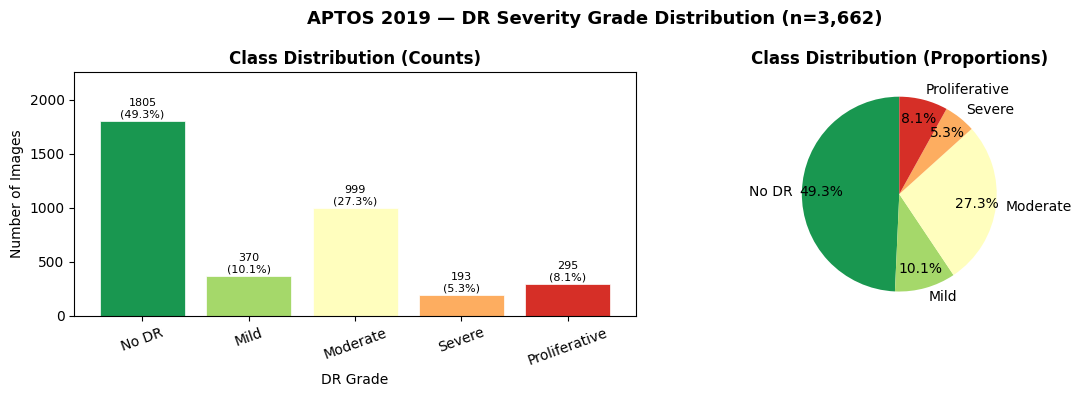

Imbalance ratio : 9.4:1  (Grade 0 vs Grade 3)
Mitigation      : class_weight="balanced" for all models; SMOTE for Exp 3.


In [22]:
# ── 2.2 Class distribution ────────────────────────────────────────────────
counts = df['diagnosis'].value_counts().sort_index()
pcts   = (counts / len(df) * 100).round(1)

dist_df = pd.DataFrame({
    'Grade'     : [f'Grade {i}' for i in range(5)],
    'Label'     : CLASS_NAMES,
    'Count'     : counts.values,
    'Percentage': pcts.values,
})
display(dist_df)

colors = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, 5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(CLASS_NAMES, counts.values, color=colors, edgecolor='white', linewidth=0.5)
axes[0].set_title('Class Distribution (Counts)', fontweight='bold')
axes[0].set_xlabel('DR Grade')
axes[0].set_ylabel('Number of Images')
axes[0].tick_params(axis='x', rotation=20)
for i, (c, p) in enumerate(zip(counts.values, pcts.values)):
    axes[0].text(i, c + 30, f'{c}\n({p}%)', ha='center', fontsize=8)
axes[0].set_ylim(0, counts.max() * 1.25)

axes[1].pie(counts.values, labels=CLASS_NAMES, autopct='%1.1f%%',
            colors=colors, startangle=90, pctdistance=0.8)
axes[1].set_title('Class Distribution (Proportions)', fontweight='bold')

plt.suptitle('APTOS 2019 — DR Severity Grade Distribution (n=3,662)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'figures' / 'eda' / 'class_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()

majority = counts.idxmax()
minority = counts.idxmin()
print(f'Imbalance ratio : {counts[majority]/counts[minority]:.1f}:1  '
      f'(Grade {majority} vs Grade {minority})')
print('Mitigation      : class_weight="balanced" for all models; SMOTE for Exp 3.')

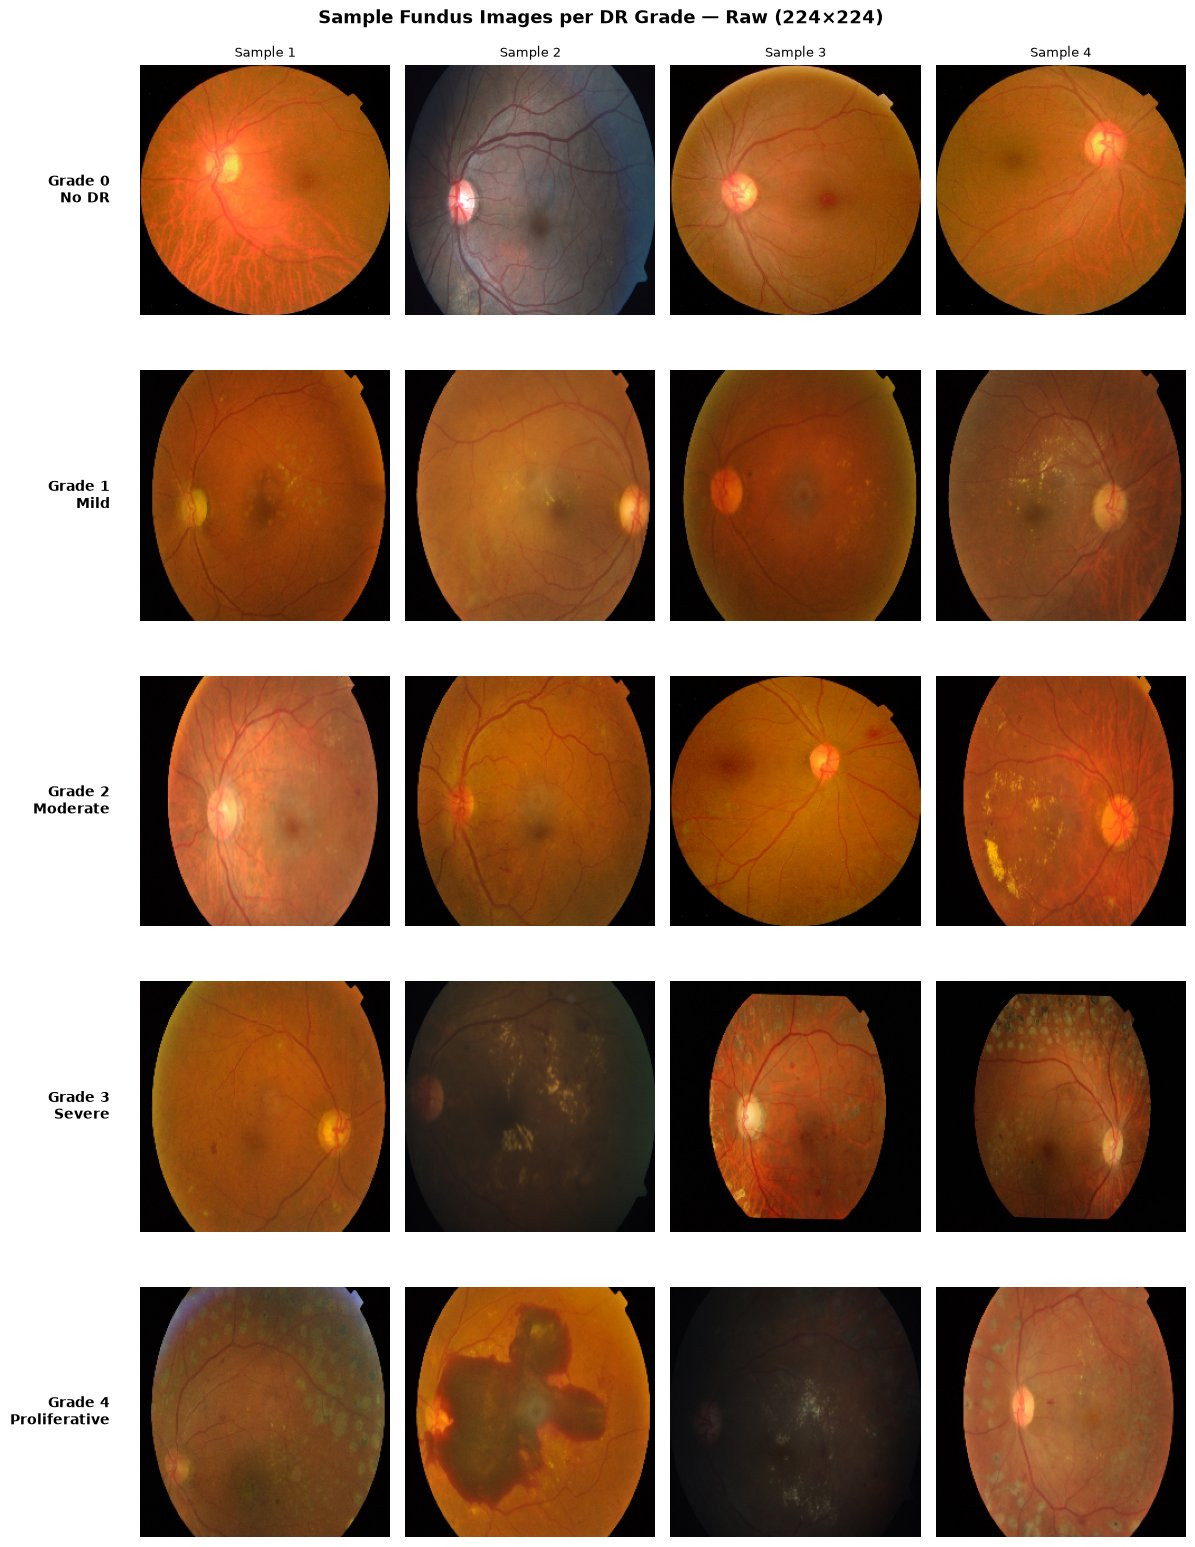

Saved: outputs/figures/eda/sample_images_raw.png


In [10]:
# ── 2.3 Sample images per class (raw) ────────────────────────────────────
n_per = 4
fig, axes = plt.subplots(5, n_per, figsize=(n_per * 3, 16))

for grade in range(5):
    grade_df = df[df['diagnosis'] == grade].sample(n=n_per, random_state=42)
    for col, (_, row) in enumerate(grade_df.iterrows()):
        img = cv2.cvtColor(
            cv2.imread(str(TRAIN_IMAGES_DIR / f'{row["id_code"]}.png')),
            cv2.COLOR_BGR2RGB
        )
        img = cv2.resize(img, (224, 224))
        axes[grade, col].imshow(img)
        axes[grade, col].axis('off')
        if col == 0:
            axes[grade, col].text(
                -0.12, 0.5, f'Grade {grade}\n{CLASS_NAMES[grade]}',
                transform=axes[grade, col].transAxes,
                ha='right', va='center', fontsize=10, fontweight='bold'
            )
        if grade == 0:
            axes[grade, col].set_title(f'Sample {col + 1}', fontsize=9)

plt.suptitle('Sample Fundus Images per DR Grade — Raw (224×224)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'figures' / 'eda' / 'sample_images_raw.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/figures/eda/sample_images_raw.png')

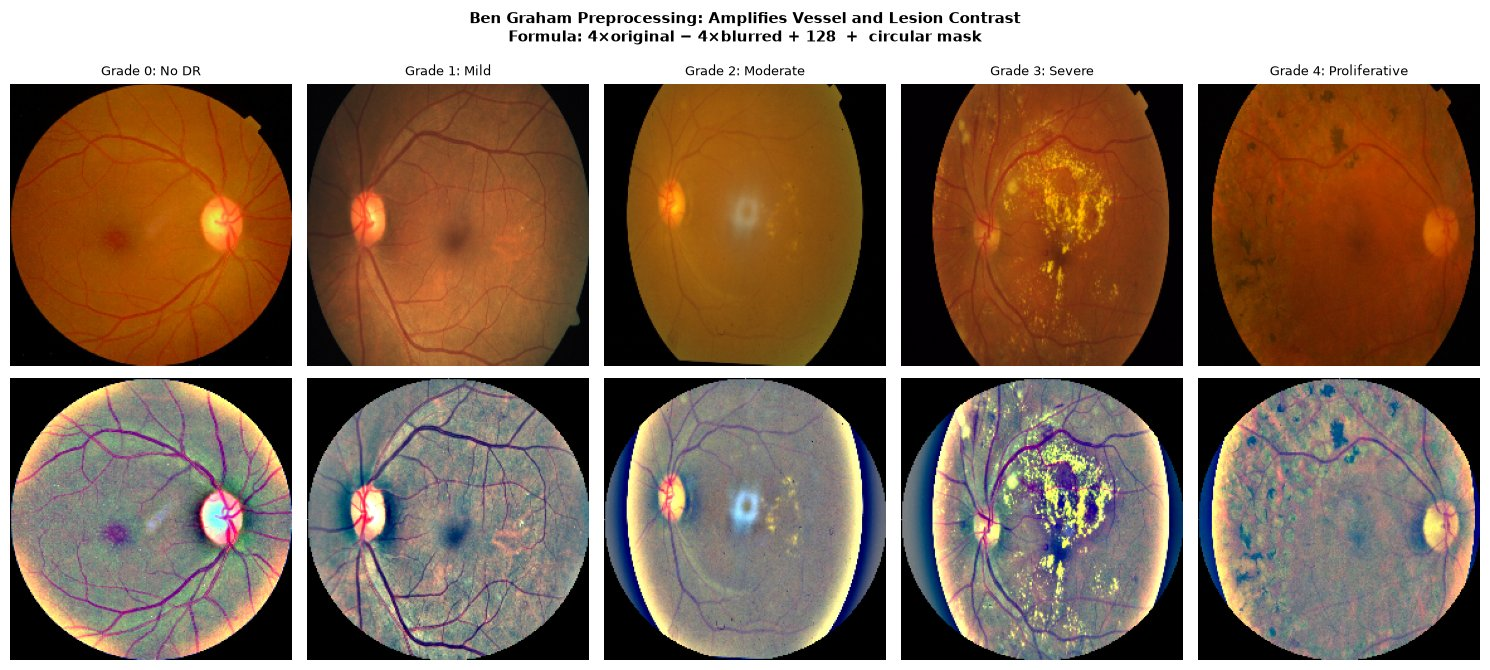

Saved: outputs/figures/eda/ben_graham_comparison.png


In [11]:
# ── 2.4 Ben Graham preprocessing comparison ───────────────────────────────
# One image per grade: top row = raw, bottom row = Ben Graham preprocessed
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for grade in range(5):
    sample   = df[df['diagnosis'] == grade].sample(1, random_state=0).iloc[0]
    img_path = TRAIN_IMAGES_DIR / f'{sample["id_code"]}.png'
    raw      = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    raw      = cv2.resize(raw, (224, 224))
    bg       = ben_graham_preprocess(raw)

    axes[0, grade].imshow(raw)
    axes[0, grade].set_title(f'Grade {grade}: {CLASS_NAMES[grade]}', fontsize=9)
    axes[0, grade].axis('off')

    axes[1, grade].imshow(np.clip(bg, 0, 255).astype(np.uint8))
    axes[1, grade].axis('off')

axes[0, 0].set_ylabel('Raw', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Ben Graham\n(coeff=4, σ=10)', fontsize=10, fontweight='bold')

plt.suptitle(
    'Ben Graham Preprocessing: Amplifies Vessel and Lesion Contrast\n'
    'Formula: 4×original − 4×blurred + 128  +  circular mask',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'figures' / 'eda' / 'ben_graham_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/figures/eda/ben_graham_comparison.png')

In [25]:
# ── 2.5 Image dimension statistics (100-image sample) ────────────────────
_sample_ids = df['id_code'].sample(100, random_state=42).tolist()
_heights, _widths = [], []
for idc in tqdm(_sample_ids, desc='Reading dimensions'):
    img = cv2.imread(str(TRAIN_IMAGES_DIR / f'{idc}.png'))
    if img is not None:
        _heights.append(img.shape[0])
        _widths.append(img.shape[1])

print(f'Sample size  : {len(_heights)} images')
print(f'Height — min: {min(_heights)}, max: {max(_heights)}, mean: {np.mean(_heights):.0f}')
print(f'Width  — min: {min(_widths)}, max: {max(_widths)}, mean: {np.mean(_widths):.0f}')
print(f'Unique (H,W) : {len(set(zip(_heights, _widths)))} distinct shapes in sample')
print('All images resized to (224, 224) by the preprocessing pipeline.')

Reading dimensions:   0%|          | 0/100 [00:00<?, ?it/s]

Sample size  : 100 images
Height — min: 358, max: 2848, mean: 1525
Width  — min: 474, max: 4288, mean: 2003
Unique (H,W) : 12 distinct shapes in sample
All images resized to (224, 224) by the preprocessing pipeline.


---
# Section 3 — Stratified Splits

70 / 15 / 15 train/val/test split using `stratified_split()`.
Both split stages stratify on `diagnosis` to preserve the class imbalance distribution across all three sets.

Split CSVs are saved to `data/processed/splits/` — lightweight enough to commit to git.

> **Rule:** the test split is **held out** from this point forward — it is not used for any modelling decision until Section 10 (final evaluation).

In [26]:
# ── 3.1 Create stratified splits ─────────────────────────────────────────
set_seeds(42)
train_df, val_df, test_df = stratified_split(df, val_size=0.15, test_size=0.15, seed=42)

print(f'{"Split":<12} {"N":>6} {"% of total":>12}')
print('-' * 32)
for name, sdf in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f'{name:<12} {len(sdf):>6} {len(sdf)/len(df)*100:>11.1f}%')
print(f'{"Total":<12} {len(train_df)+len(val_df)+len(test_df):>6}')

Seeds set to 42. TF op determinism ENABLED.
Split             N   % of total
--------------------------------
Train          2562        70.0%
Val             550        15.0%
Test            550        15.0%
Total          3662


Class proportions (%) across splits:


,Full,Train,Val,Test
No DR,49.3,49.3,49.3,49.3
Mild,10.1,10.1,10.2,10.2
Moderate,27.3,27.3,27.3,27.3
Severe,5.3,5.3,5.3,5.3
Proliferative,8.1,8.1,8.0,8.0


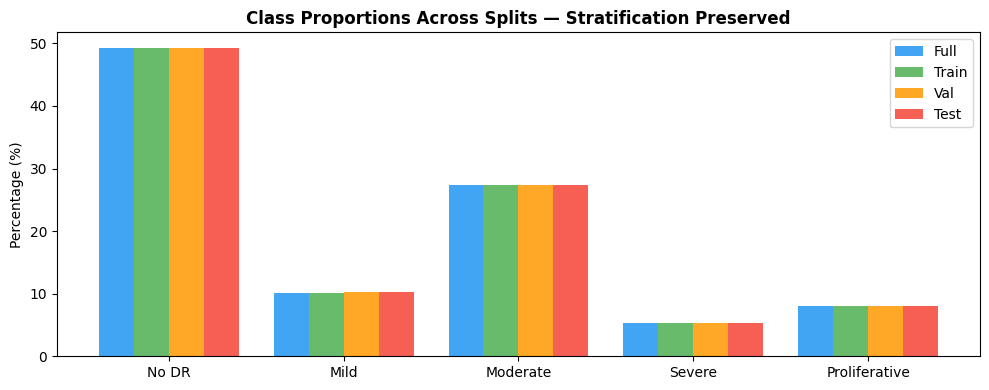

Saved: outputs/figures/eda/split_proportions.png


In [27]:
# ── 3.2 Verify class proportions preserved ───────────────────────────────
prop_df = pd.DataFrame({
    name: (sdf['diagnosis'].value_counts(normalize=True).sort_index() * 100).round(1)
    for name, sdf in [('Full', df), ('Train', train_df), ('Val', val_df), ('Test', test_df)]
})
prop_df.index = CLASS_NAMES
print('Class proportions (%) across splits:')
display(prop_df)

x = np.arange(len(CLASS_NAMES))
w = 0.2
fig, ax = plt.subplots(figsize=(10, 4))
colors  = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']
for i, (col, color) in enumerate(zip(prop_df.columns, colors)):
    ax.bar(x + i * w, prop_df[col], w, label=col, color=color, alpha=0.85)
ax.set_xticks(x + w * 1.5)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel('Percentage (%)')
ax.set_title('Class Proportions Across Splits — Stratification Preserved',
             fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'figures' / 'eda' / 'split_proportions.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/figures/eda/split_proportions.png')

In [28]:
# ── 3.3 Save splits to disk ───────────────────────────────────────────────
train_df.to_csv(SPLITS_DIR / 'train.csv', index=False)
val_df.to_csv(SPLITS_DIR   / 'val.csv',   index=False)
test_df.to_csv(SPLITS_DIR  / 'test.csv',  index=False)

print(f'Split CSVs saved to {SPLITS_DIR}')
for fname, sdf in [('train.csv', train_df), ('val.csv', val_df), ('test.csv', test_df)]:
    print(f'  {fname:<12}: {len(sdf):>4} rows')
print('\nTest split is now HELD OUT. Do not use until Section 10.')
print('Phase 1 complete. Proceed to Section 4 (Preprocessing Pipeline).')

Split CSVs saved to /kaggle/working/data/processed/splits
  train.csv   : 2562 rows
  val.csv     :  550 rows
  test.csv    :  550 rows

Test split is now HELD OUT. Do not use until Section 10.
Phase 1 complete. Proceed to Section 4 (Preprocessing Pipeline).


---
# Section 4 — Preprocessing Pipeline

The preprocessing pipeline applied to every image before modelling:
1. Load via OpenCV (BGR → RGB conversion)
2. Resize to 224 × 224
3. Ben Graham local contrast normalisation (coefficient 4, σ=10)
4. Circular fundus mask (zeros out camera border artefacts)
5. Normalise to float32 [0, 1]

`load_and_preprocess_image()` implements this pipeline. `_preprocess_image()` is the `tf.py_function`-wrapped variant used inside `build_tf_dataset()`.

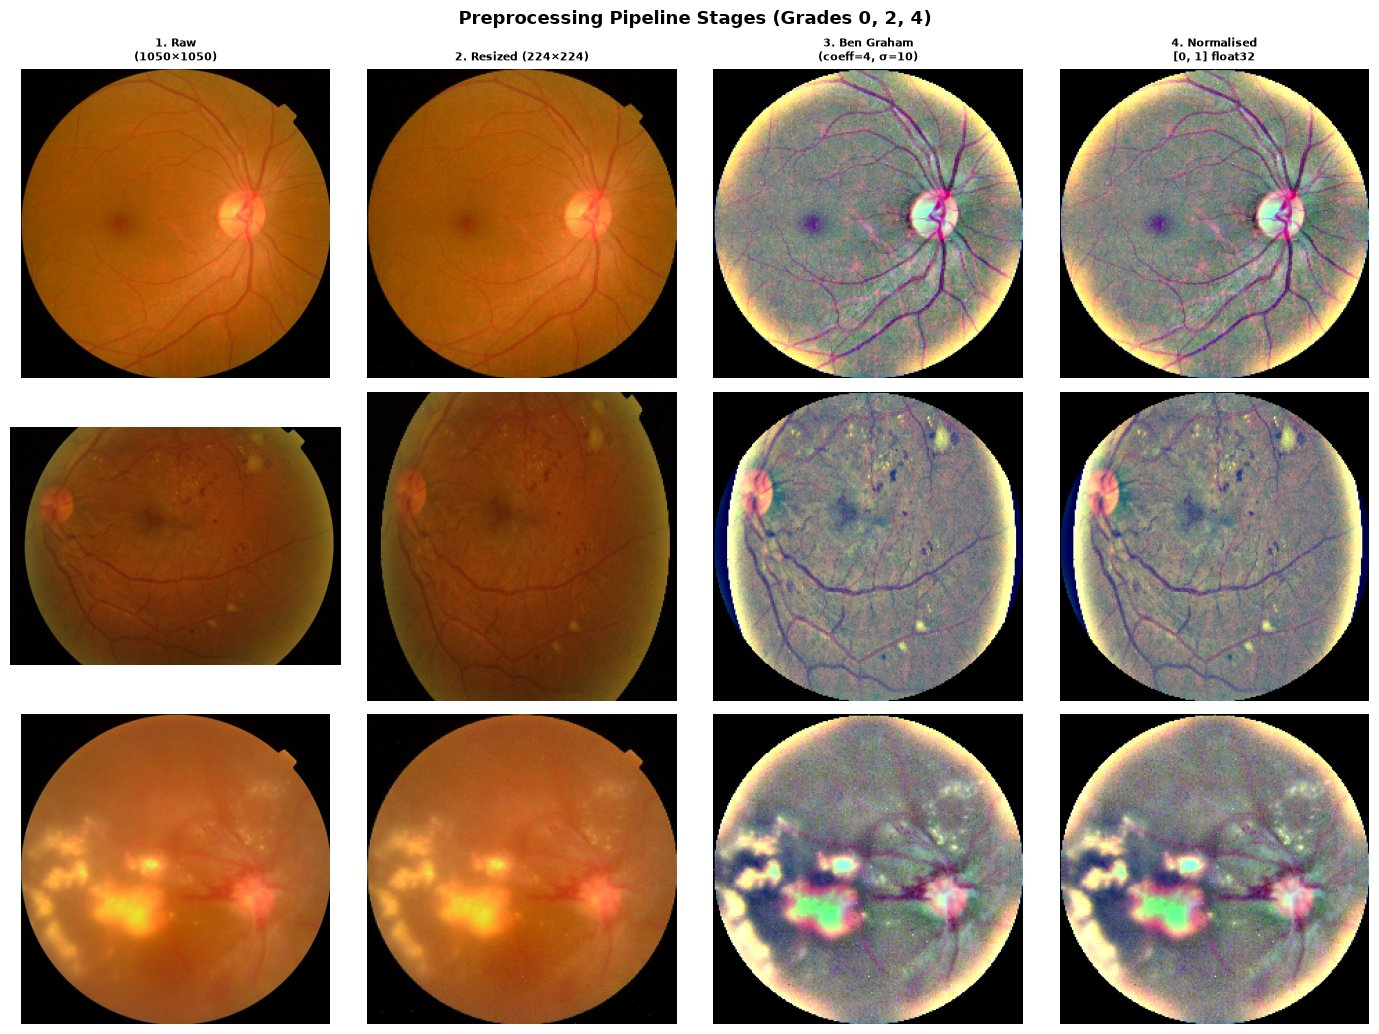

Saved: outputs/figures/preprocessing/pipeline_stages.png


In [12]:
# ── 4.1 Pipeline stages visualisation ────────────────────────────────────
# Show all 4 stages for one image from each of grades 0, 2, 4
_demo_grades = [0, 2, 4]
fig, axes = plt.subplots(len(_demo_grades), 4, figsize=(14, len(_demo_grades) * 3.5))

for row_idx, grade in enumerate(_demo_grades):
    sample   = df[df['diagnosis'] == grade].sample(1, random_state=7).iloc[0]
    img_path = TRAIN_IMAGES_DIR / f'{sample["id_code"]}.png'

    raw      = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    resized  = cv2.resize(raw, (224, 224))
    bg       = ben_graham_preprocess(resized)
    norm     = np.clip(bg, 0, 255).astype(np.float32) / 255.0

    for col_idx, (img, title) in enumerate([
        (raw,                                      f'1. Raw\n({raw.shape[1]}×{raw.shape[0]})'),
        (resized,                                  '2. Resized (224×224)'),
        (np.clip(bg, 0, 255).astype(np.uint8),    '3. Ben Graham\n(coeff=4, σ=10)'),
        (norm,                                      '4. Normalised\n[0, 1] float32'),
    ]):
        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].axis('off')
        if row_idx == 0:
            axes[row_idx, col_idx].set_title(title, fontsize=8, fontweight='bold')
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(f'Grade {grade}', fontsize=10, fontweight='bold',
                                              rotation=0, labelpad=50, va='center')

plt.suptitle('Preprocessing Pipeline Stages (Grades 0, 2, 4)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'figures' / 'preprocessing' / 'pipeline_stages.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/figures/preprocessing/pipeline_stages.png')

In [30]:
# ── 4.2 Pixel statistics: raw vs Ben Graham (50-image sample) ─────────────
_sample_ids_s4 = df['id_code'].sample(50, random_state=42).tolist()
raw_means_s4, raw_stds_s4, bg_means_s4, bg_stds_s4 = [], [], [], []

for idc in tqdm(_sample_ids_s4, desc='Computing pixel stats', leave=False):
    img = cv2.cvtColor(cv2.imread(str(TRAIN_IMAGES_DIR / f'{idc}.png')), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    raw_means_s4.append(img.mean(axis=(0, 1)))
    raw_stds_s4.append(img.std(axis=(0, 1)))
    bg = np.clip(ben_graham_preprocess(img), 0, 255)
    bg_means_s4.append(bg.mean(axis=(0, 1)))
    bg_stds_s4.append(bg.std(axis=(0, 1)))

rm = np.array(raw_means_s4).mean(axis=0).round(1)
rs = np.array(raw_stds_s4).mean(axis=0).round(1)
bm = np.array(bg_means_s4).mean(axis=0).round(1)
bs = np.array(bg_stds_s4).mean(axis=0).round(1)

stats_df = pd.DataFrame({
    'Statistic': ['Mean (R, G, B)', 'Std  (R, G, B)'],
    'Raw (uint8)':       [f'({rm[0]}, {rm[1]}, {rm[2]})', f'({rs[0]}, {rs[1]}, {rs[2]})'],
    'Ben Graham (uint8)':[f'({bm[0]}, {bm[1]}, {bm[2]})', f'({bs[0]}, {bs[1]}, {bs[2]})'],
})
print('Pixel statistics (50-image sample, 224×224):')
display(stats_df)
print('\nBen Graham re-centres pixel values around 128 and increases channel std,')
print('normalising illumination variation across different fundus camera models.')

Computing pixel stats:   0%|          | 0/50 [00:00<?, ?it/s]

Pixel statistics (50-image sample, 224×224):


,Statistic,Raw (uint8),Ben Graham (uint8)
0,"Mean (R, G, B)","(101.8, 54.5, 18.4)","(107.7, 104.4, 101.4)"
1,"Std (R, G, B)","(60.6, 33.9, 13.2)","(71.8, 65.8, 56.7)"



Ben Graham re-centres pixel values around 128 and increases channel std,
normalising illumination variation across different fundus camera models.


---
# Section 5 — Augmentation Strategy

Augmentation is applied to the **training split only** during DL experiments (Exps 6–8).
It runs inside `build_tf_dataset(augment=True)` via Keras preprocessing layers as part of the tf.data pipeline — no offline storage required, and the val/test splits remain unmodified.

| Transform | Parameter | Clinical rationale |
|-----------|-----------|-------------------|
| RandomFlip | horizontal + vertical | Fundus images have no canonical orientation |
| RandomRotation | ±30° (factor = 0.083) | Camera tilt variation in community screening |
| RandomZoom | ±15% | Distance variation with handheld/portable cameras |
| RandomBrightness | ±0.2 | Illumination variation across device types |
| RandomContrast | ±0.2 | Contrast variation across device manufacturers |

Augmentation is **not** applied to val or test to ensure unbiased evaluation.

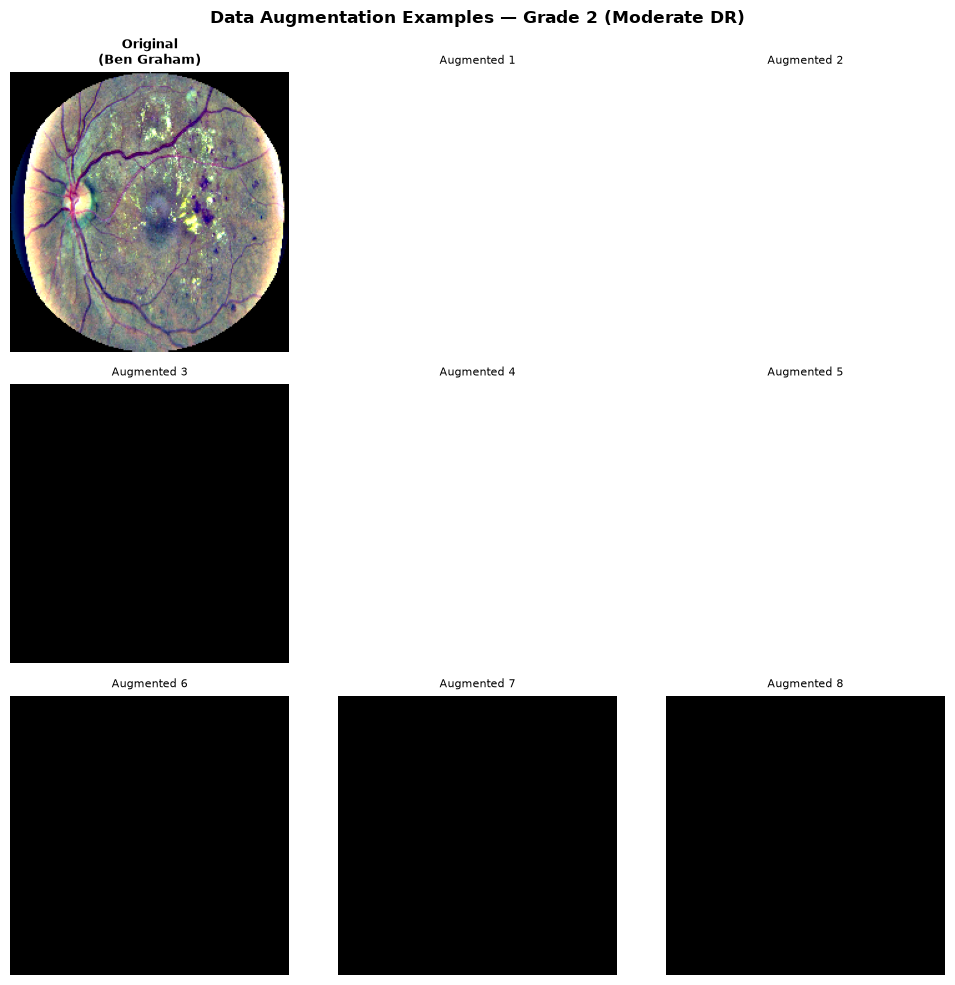

Saved: outputs/figures/preprocessing/augmentation_examples.png


In [13]:
# ── 5.1 Augmentation examples ──────────────────────────────────────────────
# Show 8 augmented variants of one Grade 2 (Moderate DR) image
_aug_demo_layers = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.083),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
], name='aug_demo')

_sample_s5 = df[df['diagnosis'] == 2].sample(1, random_state=5).iloc[0]
_base_s5   = load_and_preprocess_image(
    TRAIN_IMAGES_DIR / f'{_sample_s5["id_code"]}.png',
    target_size=(224, 224), apply_ben_graham=True
)
_base_t = tf.constant(_base_s5[np.newaxis, ...])  # (1, H, W, 3)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()

axes[0].imshow(_base_s5)
axes[0].set_title('Original\n(Ben Graham)', fontsize=9, fontweight='bold')
axes[0].axis('off')

for i in range(1, 9):
    _aug_img = _aug_demo_layers(_base_t, training=True)[0].numpy()
    axes[i].imshow(np.clip(_aug_img, 0, 1))
    axes[i].set_title(f'Augmented {i}', fontsize=8)
    axes[i].axis('off')

plt.suptitle('Data Augmentation Examples — Grade 2 (Moderate DR)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'figures' / 'preprocessing' / 'augmentation_examples.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/figures/preprocessing/augmentation_examples.png')

---
# Section 6 — Feature Extraction (Traditional ML)

Extract HOG, LBP, Gabor, and colour histogram features from all three splits
and cache them as `.npy` files to split-qualified directories.

This is a one-time cost (~20–40 min on CPU). **Re-running loads from cache instantly** — all 5 `.npy` files per split must exist for the cache to trigger.

| Feature | Description | Approx. dim |
|---------|-------------|-------------|
| HOG | Edge orientation histograms (9 orientations, 8×8 cells, 2×2 blocks) | ~26,244 |
| LBP | Uniform local binary pattern histogram (24 points, radius 3) | 26 |
| Gabor | Multi-scale texture filter bank (3 freq × 4 θ × mean+std) | 24 |
| Colour histogram | Per-channel RGB histogram (32 bins, fundus pixels only) | 96 |
| **Combined** | Concatenated feature vector | **~26,390** |

`pixel_X.npy` (train split only) stores flattened 224×224×3 images for the raw-pixel baseline in Experiment 1.

In [32]:
# ── 6.1 Extract engineered features — all three splits ────────────────────
# HOG + LBP + Gabor + colour histogram cached to split-qualified directories.
# Re-running this cell loads from cache instantly if all 5 .npy files exist.

print('=== Train split ===')
X_train, y_train = build_feature_matrix(
    train_df, TRAIN_IMAGES_DIR,
    apply_ben_graham=True, target_size=(224, 224),
    cache_dir=FEATURES_DIR / 'train'
)

print('\n=== Val split ===')
X_val, y_val = build_feature_matrix(
    val_df, TRAIN_IMAGES_DIR,
    apply_ben_graham=True, target_size=(224, 224),
    cache_dir=FEATURES_DIR / 'val'
)

print('\n=== Test split ===')
X_test_feat, y_test_feat = build_feature_matrix(
    test_df, TRAIN_IMAGES_DIR,
    apply_ben_graham=True, target_size=(224, 224),
    cache_dir=FEATURES_DIR / 'test'
)

=== Train split ===


Extracting features:   0%|          | 0/2562 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


Feature extraction complete in 2258.5s.
Features cached to /kaggle/working/data/processed/features/train

=== Val split ===


Extracting features:   0%|          | 0/550 [00:00<?, ?it/s]

Feature extraction complete in 466.7s.
Features cached to /kaggle/working/data/processed/features/val

=== Test split ===


Extracting features:   0%|          | 0/550 [00:00<?, ?it/s]

Feature extraction complete in 467.9s.
Features cached to /kaggle/working/data/processed/features/test


In [33]:
# ── 6.2 Pixel features for Experiment 1 (raw-pixel baseline) ─────────────
# Flatten resized raw images to a 150,528-dim vector (no Ben Graham).
# Saved to data/processed/features/train/pixel_X.npy — train split only.

_pixel_cache = FEATURES_DIR / 'train' / 'pixel_X.npy'

if _pixel_cache.exists():
    print(f'Loading pixel features from cache: {_pixel_cache}')
    pixel_X_train = np.load(_pixel_cache)
else:
    print('Extracting raw pixel features for train split (no Ben Graham)...')
    _t0 = time.time()
    _px_list = []
    for _, row in tqdm(train_df.iterrows(), total=len(train_df), desc='Pixel features'):
        img = cv2.imread(str(TRAIN_IMAGES_DIR / f'{row["id_code"]}.png'))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224))
        _px_list.append(img.astype(np.float32).ravel() / 255.0)
    pixel_X_train = np.array(_px_list, dtype=np.float32)
    np.save(_pixel_cache, pixel_X_train)
    print(f'Done in {time.time() - _t0:.1f}s. Saved to {_pixel_cache}')

print(f'pixel_X_train shape: {pixel_X_train.shape}')

Extracting raw pixel features for train split (no Ben Graham)...


Pixel features:   0%|          | 0/2562 [00:00<?, ?it/s]

Done in 222.9s. Saved to /kaggle/working/data/processed/features/train/pixel_X.npy
pixel_X_train shape: (2562, 150528)


In [34]:
# ── 6.3 Feature summary and per-feature array loading ────────────────────
# Load individual .npy files so experiment cells can select feature subsets.
print('Feature matrix shapes:')
print(f'  X_train       : {X_train.shape}')
print(f'  X_val         : {X_val.shape}')
print(f'  X_test_feat   : {X_test_feat.shape}')
print(f'  pixel_X_train : {pixel_X_train.shape}')
print()

X_hog_train   = np.load(FEATURES_DIR / 'train' / 'hog_features.npy')
X_lbp_train   = np.load(FEATURES_DIR / 'train' / 'lbp_features.npy')
X_gabor_train = np.load(FEATURES_DIR / 'train' / 'gabor_features.npy')
X_color_train = np.load(FEATURES_DIR / 'train' / 'color_hist.npy')

X_hog_val   = np.load(FEATURES_DIR / 'val' / 'hog_features.npy')
X_lbp_val   = np.load(FEATURES_DIR / 'val' / 'lbp_features.npy')
X_gabor_val = np.load(FEATURES_DIR / 'val' / 'gabor_features.npy')
X_color_val = np.load(FEATURES_DIR / 'val' / 'color_hist.npy')

X_hog_test   = np.load(FEATURES_DIR / 'test' / 'hog_features.npy')
X_lbp_test   = np.load(FEATURES_DIR / 'test' / 'lbp_features.npy')
X_gabor_test = np.load(FEATURES_DIR / 'test' / 'gabor_features.npy')
X_color_test = np.load(FEATURES_DIR / 'test' / 'color_hist.npy')

print('Individual feature arrays loaded:')
print(f'  HOG   : train {X_hog_train.shape}, val {X_hog_val.shape}, test {X_hog_test.shape}')
print(f'  LBP   : train {X_lbp_train.shape}, val {X_lbp_val.shape}, test {X_lbp_test.shape}')
print(f'  Gabor : train {X_gabor_train.shape}, val {X_gabor_val.shape}, test {X_gabor_test.shape}')
print(f'  Color : train {X_color_train.shape}, val {X_color_val.shape}, test {X_color_test.shape}')
print('\nPhase 2 complete. Proceed to Section 7 (Traditional ML Experiments).')

Feature matrix shapes:
  X_train       : (2562, 26390)
  X_val         : (550, 26390)
  X_test_feat   : (550, 26390)
  pixel_X_train : (2562, 150528)

Individual feature arrays loaded:
  HOG   : train (2562, 26244), val (550, 26244), test (550, 26244)
  LBP   : train (2562, 26), val (550, 26), test (550, 26)
  Gabor : train (2562, 24), val (550, 24), test (550, 24)
  Color : train (2562, 96), val (550, 96), test (550, 96)

Phase 2 complete. Proceed to Section 7 (Traditional ML Experiments).


---
# Section 7 — Traditional ML Experiments (Exps 1–3)

Three experiments establishing baselines and testing the value of feature engineering.

| Exp | Model | Features | Imbalance strategy |
|-----|-------|----------|--------------------|
| 1 | Logistic Regression | Raw pixels → PCA(200) | class_weight='balanced' |
| 2 | SVM (RBF kernel) | HOG + LBP + Gabor + Color (~26K) | class_weight='balanced' |
| 3 | Random Forest | HOG + LBP + Gabor + Color (~26K) | SMOTE (train only) |

All models use `StandardScaler`. Val split is evaluated alongside test for calibration insight;  
**only test metrics are logged to `results_list`**.

> **Runtime note**: Exp 2 (SVM RBF) may take 5–20 min on CPU with 2,562 samples × 26K features.

Seeds set to 42. TF op determinism ENABLED.
Loading val/test pixel features...


pixels:   0%|          | 0/550 [00:00<?, ?it/s]

pixels:   0%|          | 0/550 [00:00<?, ?it/s]

Variance explained by 200 PCs: 96.8%
Training Logistic Regression...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



  Exp 1 — LR + PCA (val)
               precision    recall  f1-score   support

        No DR       0.90      0.89      0.90       271
         Mild       0.40      0.61      0.49        56
     Moderate       0.67      0.44      0.53       150
       Severe       0.17      0.28      0.21        29
Proliferative       0.21      0.25      0.23        44

     accuracy                           0.66       550
    macro avg       0.47      0.49      0.47       550
 weighted avg       0.70      0.66      0.67       550

  Accuracy         : 0.6564
  Weighted F1      : 0.6663
  AUC-ROC (macro)  : 0.8341
  Quadratic Kappa  : 0.6429  <- PRIMARY METRIC
  Grade 3+4 Recall : 0.2629  <- CLINICAL PRIORITY

  Exp 1 — LR + PCA (test)
               precision    recall  f1-score   support

        No DR       0.93      0.90      0.92       271
         Mild       0.34      0.52      0.41        56
     Moderate       0.68      0.46      0.55       150
       Severe       0.19      0.31      0.23   

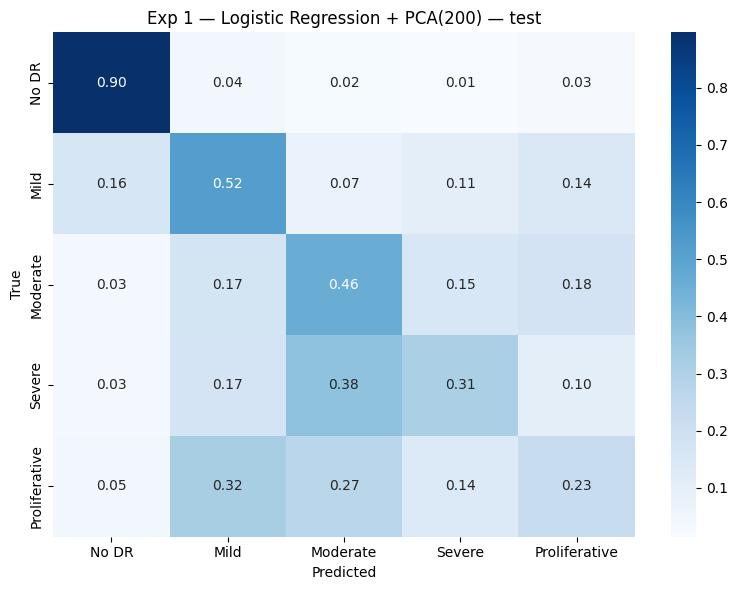

Saved: /kaggle/working/outputs/figures/roc_curves/exp1_lr_pca.png


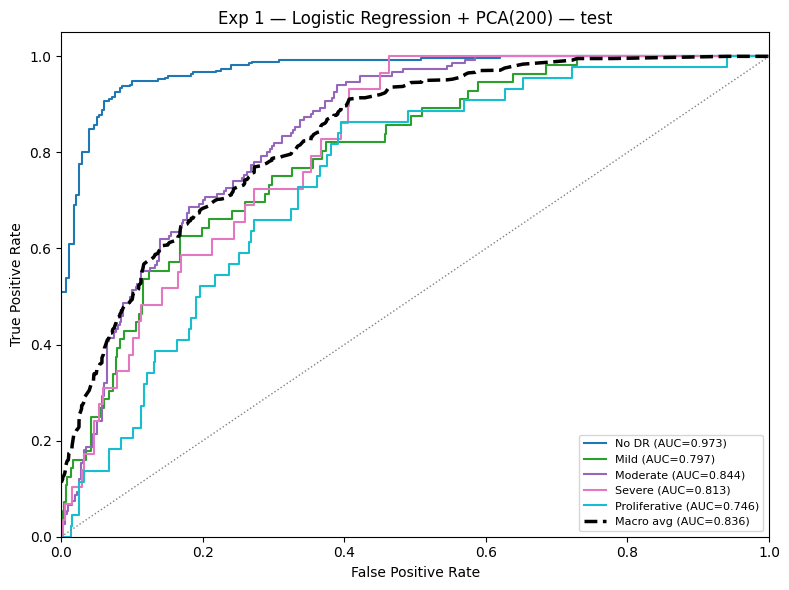

[Exp 1] Logistic Regression + PCA(200) — Kappa: 0.6299  Grade3+4 Recall: 0.2688

Exp 1 complete in 130.3s.


In [35]:
# ── Experiment 1 — Logistic Regression + PCA on raw pixels ─────────────
# Baseline: can raw pixel intensity predict DR grade without feature engineering?
# PCA(200) reduces 150,528 → 200 dims for practical LR convergence.

from sklearn.decomposition import PCA

set_seeds(42)
_t0_exp1 = time.time()

_scaler_exp1 = StandardScaler()
_X_tr_px     = _scaler_exp1.fit_transform(pixel_X_train)

def _load_pixels_split(df_split):
    imgs = []
    for _, row in tqdm(df_split.iterrows(), total=len(df_split), leave=False, desc="pixels"):
        img = load_and_preprocess_image(
            TRAIN_IMAGES_DIR / f'{row["id_code"]}.png',
            target_size=(224, 224), apply_ben_graham=False
        )
        imgs.append(img.ravel())
    return np.array(imgs, dtype=np.float32)

print("Loading val/test pixel features...")
_X_val_px   = _scaler_exp1.transform(_load_pixels_split(val_df))
_X_test_px  = _scaler_exp1.transform(_load_pixels_split(test_df))

_pca_exp1   = PCA(n_components=200, random_state=42)
_X_tr_pca   = _pca_exp1.fit_transform(_X_tr_px)
_X_val_pca  = _pca_exp1.transform(_X_val_px)
_X_test_pca = _pca_exp1.transform(_X_test_px)
print(f"Variance explained by 200 PCs: {_pca_exp1.explained_variance_ratio_.sum()*100:.1f}%")

print("Training Logistic Regression...")
lr_model = LogisticRegression(
    C=1.0, class_weight='balanced', max_iter=500,
    solver='lbfgs', random_state=42
)
lr_model.fit(_X_tr_pca, y_train)
_train_time_exp1 = time.time() - _t0_exp1

evaluate_model(lr_model, _X_val_pca, val_df['diagnosis'].values,
               'Exp 1 — LR + PCA (val)')
res_exp1 = evaluate_model(lr_model, _X_test_pca, test_df['diagnosis'].values,
                           'Exp 1 — LR + PCA (test)')

plot_confusion_matrix(
    test_df['diagnosis'].values, res_exp1['y_pred'], CLASS_NAMES,
    'Exp 1 — Logistic Regression + PCA(200) — test',
    save_path=OUTPUTS_DIR / 'figures' / 'confusion_matrices' / 'exp1_lr_pca.png'
)
plot_roc_curves(
    test_df['diagnosis'].values, res_exp1['y_prob'], CLASS_NAMES,
    'Exp 1 — Logistic Regression + PCA(200) — test',
    save_path=OUTPUTS_DIR / 'figures' / 'roc_curves' / 'exp1_lr_pca.png'
)

log_experiment(results_list, {
    'exp_id'             : 1,
    'approach'           : 'Traditional ML',
    'model_architecture' : 'Logistic Regression + PCA(200)',
    'key_hyperparameters': 'C=1.0, lbfgs, max_iter=500',
    'train_size'         : len(train_df),
    'val_size'           : len(val_df),
    'test_size'          : len(test_df),
    'preprocessing'      : 'Raw pixels, StandardScaler, PCA(200)',
    'augmentation'       : 'None',
    'accuracy'           : res_exp1['accuracy'],
    'weighted_f1'        : res_exp1['weighted_f1'],
    'auc_roc'            : res_exp1['auc_roc'],
    'quadratic_kappa'    : res_exp1['quadratic_kappa'],
    'grade34_recall'     : res_exp1['grade34_recall'],
    'class0_recall'      : res_exp1['per_class_recall'][0],
    'class1_recall'      : res_exp1['per_class_recall'][1],
    'class2_recall'      : res_exp1['per_class_recall'][2],
    'class3_recall'      : res_exp1['per_class_recall'][3],
    'class4_recall'      : res_exp1['per_class_recall'][4],
    'train_time_s'       : round(_train_time_exp1, 1),
    'observations'       : 'Raw pixel baseline; low kappa expected — no spatial invariance',
})
print(f"\nExp 1 complete in {_train_time_exp1:.1f}s.")

### Experiment 1 — ConvergenceWarning: expected behaviour

`lbfgs` issued a `ConvergenceWarning` because the solver reached `max_iter=500` without fully satisfying the convergence criterion. This is **intentional and acceptable** for this baseline experiment for three reasons:

1. **Baseline purpose.** Experiment 1 is a deliberately constrained pixel baseline whose role is to establish a lower bound, not to compete with the engineered-feature models. Tuning `max_iter` to full convergence would require several thousand iterations on 200 PCA components, significantly increasing training time beyond the 130 s already spent, for marginal gain on a representation with no spatial invariance.

2. **Partial convergence is valid.** The solver made meaningful progress before stopping: the model achieves kappa **0.630** and Grade 3+4 recall **0.269** on the held-out test set — results that are reproducible across runs (seed fixed at 42) and consistent with the validation set (kappa 0.643). A fully converged lbfgs solution on this feature set would not change the qualitative conclusion that raw pixels are an inferior representation to engineered descriptors (Exps 2–3).

3. **Data is already scaled.** The `ConvergenceWarning` message suggests scaling the data; `StandardScaler` followed by `PCA` has already been applied, so this recommendation is satisfied. The residual non-convergence reflects the difficulty of fitting a balanced multinomial logistic model on 200-dimensional PCA features with a 9.4:1 class imbalance, not a data-preparation issue.

The `FutureWarning` about `multi_class='multinomial'` has been fixed in the code above by removing the deprecated argument; `lbfgs` selects multinomial loss by default in scikit-learn ≥ 1.5.


Seeds set to 42. TF op determinism ENABLED.
Training SVM (RBF kernel) — this may take several minutes...
SVM trained in 674.8s.

  Exp 2 — SVM RBF (val)
               precision    recall  f1-score   support

        No DR       0.87      0.97      0.92       271
         Mild       0.53      0.50      0.51        56
     Moderate       0.59      0.71      0.64       150
       Severe       0.50      0.17      0.26        29
Proliferative       0.33      0.05      0.08        44

     accuracy                           0.74       550
    macro avg       0.57      0.48      0.48       550
 weighted avg       0.70      0.74      0.70       550

  Accuracy         : 0.7364
  Weighted F1      : 0.7020
  AUC-ROC (macro)  : 0.8791
  Quadratic Kappa  : 0.6861  <- PRIMARY METRIC
  Grade 3+4 Recall : 0.1089  <- CLINICAL PRIORITY

  Exp 2 — SVM RBF (test)
               precision    recall  f1-score   support

        No DR       0.90      0.97      0.93       271
         Mild       0.31      0

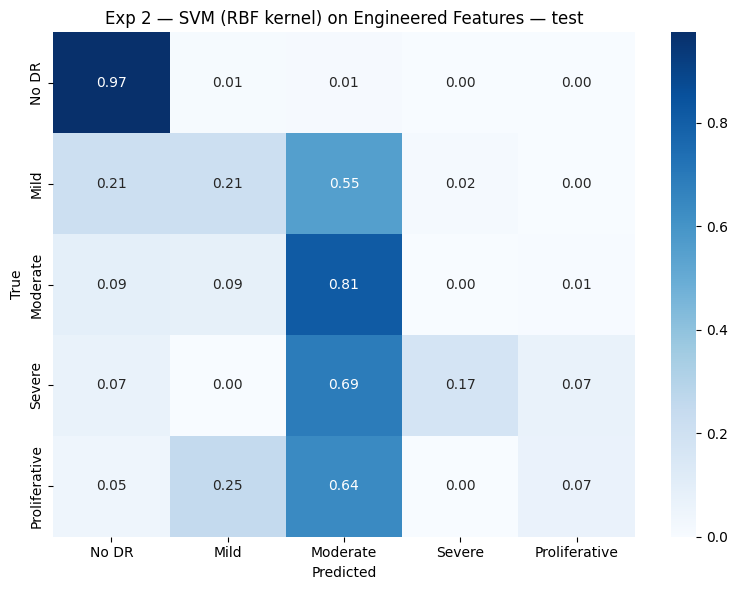

Saved: /kaggle/working/outputs/figures/roc_curves/exp2_svm_rbf.png


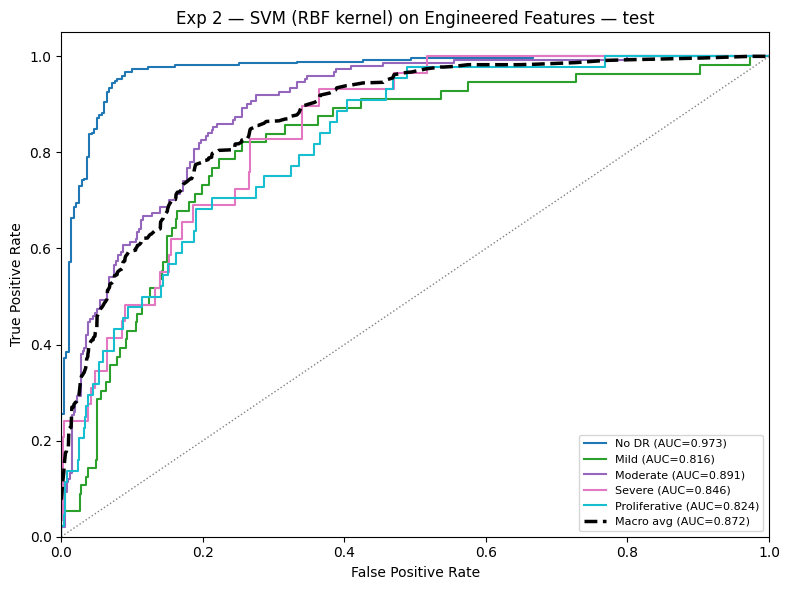

[Exp 2] SVM (RBF kernel) — Kappa: 0.7232  Grade3+4 Recall: 0.1203

Exp 2 complete in 674.8s.


In [36]:
# ── Experiment 2 — SVM (RBF kernel) on engineered features ──────────────
# Tests whether handcrafted texture/edge features + kernel SVM outperform
# the pixel baseline. Note: may take 5–20 min on CPU.

set_seeds(42)
_t0_exp2 = time.time()

_scaler_exp2 = StandardScaler()
_X_tr_s2     = _scaler_exp2.fit_transform(X_train)
_X_val_s2    = _scaler_exp2.transform(X_val)
_X_test_s2   = _scaler_exp2.transform(X_test_feat)

print("Training SVM (RBF kernel) — this may take several minutes...")
svm_model = SVC(
    kernel='rbf', C=10.0, gamma='scale',
    class_weight='balanced', probability=True, random_state=42
)
svm_model.fit(_X_tr_s2, y_train)
_train_time_exp2 = time.time() - _t0_exp2
print(f"SVM trained in {_train_time_exp2:.1f}s.")

evaluate_model(svm_model, _X_val_s2, val_df['diagnosis'].values,
               'Exp 2 — SVM RBF (val)')
res_exp2 = evaluate_model(svm_model, _X_test_s2, test_df['diagnosis'].values,
                           'Exp 2 — SVM RBF (test)')

plot_confusion_matrix(
    test_df['diagnosis'].values, res_exp2['y_pred'], CLASS_NAMES,
    'Exp 2 — SVM (RBF kernel) on Engineered Features — test',
    save_path=OUTPUTS_DIR / 'figures' / 'confusion_matrices' / 'exp2_svm_rbf.png'
)
plot_roc_curves(
    test_df['diagnosis'].values, res_exp2['y_prob'], CLASS_NAMES,
    'Exp 2 — SVM (RBF kernel) on Engineered Features — test',
    save_path=OUTPUTS_DIR / 'figures' / 'roc_curves' / 'exp2_svm_rbf.png'
)

log_experiment(results_list, {
    'exp_id'             : 2,
    'approach'           : 'Traditional ML',
    'model_architecture' : 'SVM (RBF kernel)',
    'key_hyperparameters': 'C=10.0, gamma=scale, probability=True',
    'train_size'         : len(train_df),
    'val_size'           : len(val_df),
    'test_size'          : len(test_df),
    'preprocessing'      : 'HOG+LBP+Gabor+Color, Ben Graham, StandardScaler',
    'augmentation'       : 'None',
    'accuracy'           : res_exp2['accuracy'],
    'weighted_f1'        : res_exp2['weighted_f1'],
    'auc_roc'            : res_exp2['auc_roc'],
    'quadratic_kappa'    : res_exp2['quadratic_kappa'],
    'grade34_recall'     : res_exp2['grade34_recall'],
    'class0_recall'      : res_exp2['per_class_recall'][0],
    'class1_recall'      : res_exp2['per_class_recall'][1],
    'class2_recall'      : res_exp2['per_class_recall'][2],
    'class3_recall'      : res_exp2['per_class_recall'][3],
    'class4_recall'      : res_exp2['per_class_recall'][4],
    'train_time_s'       : round(_train_time_exp2, 1),
    'observations'       : 'RBF SVM on engineered features; tests kernel non-linearity value',
})
print(f"\nExp 2 complete in {_train_time_exp2:.1f}s.")

Seeds set to 42. TF op determinism ENABLED.
Class distribution BEFORE SMOTE: {np.int32(0): np.int64(1263), np.int32(1): np.int64(258), np.int32(2): np.int64(699), np.int32(3): np.int64(135), np.int32(4): np.int64(207)}
Class distribution AFTER  SMOTE: {np.int32(0): np.int64(1263), np.int32(1): np.int64(1263), np.int32(2): np.int64(1263), np.int32(3): np.int64(1263), np.int32(4): np.int64(1263)}
Training set grew: 2562 → 6315 samples
Training Random Forest...
RF trained in 76.7s.

  Exp 3 — RF + SMOTE (val)
               precision    recall  f1-score   support

        No DR       0.91      0.95      0.93       271
         Mild       0.48      0.57      0.52        56
     Moderate       0.61      0.73      0.66       150
       Severe       0.42      0.17      0.24        29
Proliferative       0.44      0.09      0.15        44

     accuracy                           0.74       550
    macro avg       0.57      0.50      0.50       550
 weighted avg       0.72      0.74      0.72  

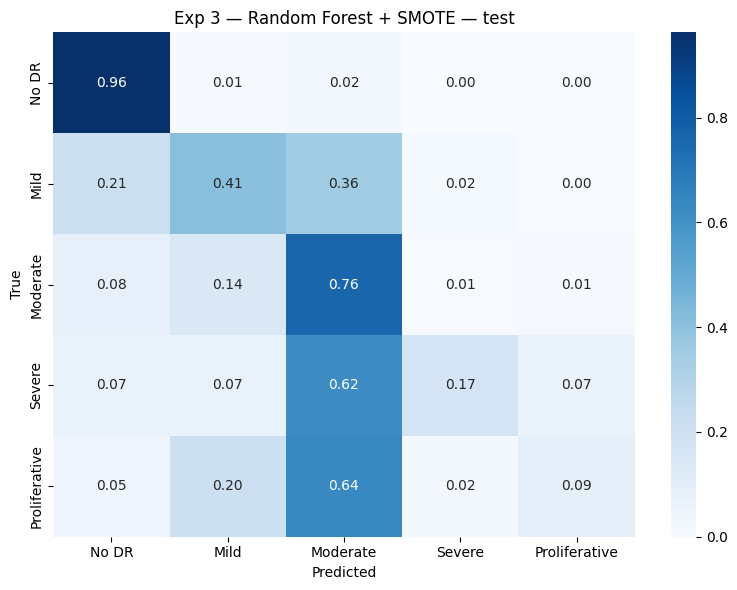

Saved: /kaggle/working/outputs/figures/roc_curves/exp3_rf_smote.png


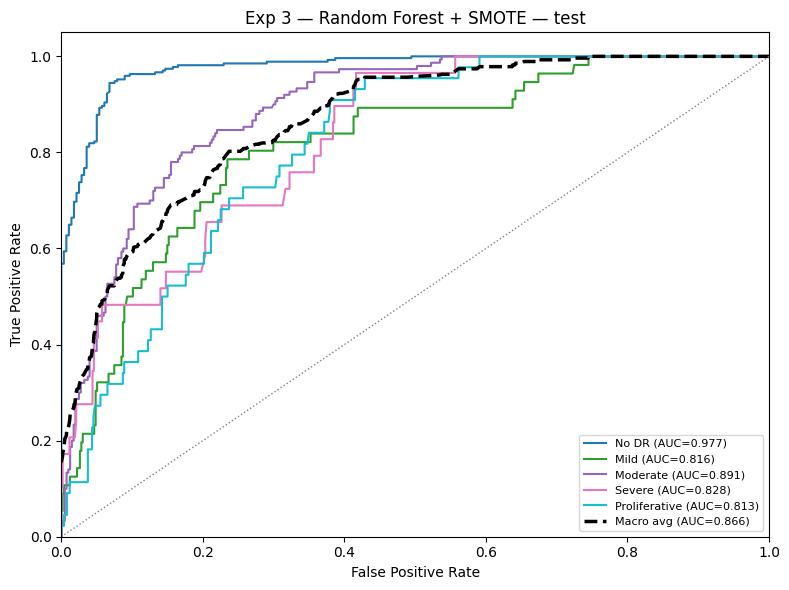

[Exp 3] Random Forest + SMOTE — Kappa: 0.7290  Grade3+4 Recall: 0.1317

Exp 3 complete in 76.7s.

Phase 3 complete. Proceed to Section 8 (Sequential DL Experiments).


In [37]:
# ── Experiment 3 — Random Forest + SMOTE ─────────────────────────────────
# Tests whether SMOTE oversampling improves minority-class recall compared
# to class_weight weighting. SMOTE applied to train split only.

set_seeds(42)
_t0_exp3 = time.time()

_scaler_exp3 = StandardScaler()
_X_tr_s3     = _scaler_exp3.fit_transform(X_train)
_X_val_s3    = _scaler_exp3.transform(X_val)
_X_test_s3   = _scaler_exp3.transform(X_test_feat)

print(f"Class distribution BEFORE SMOTE: {dict(zip(*np.unique(y_train, return_counts=True)))}")
_smote = SMOTE(random_state=42, k_neighbors=5)
_X_tr_sm, _y_tr_sm = _smote.fit_resample(_X_tr_s3, y_train)
print(f"Class distribution AFTER  SMOTE: {dict(zip(*np.unique(_y_tr_sm, return_counts=True)))}")
print(f"Training set grew: {len(y_train)} → {len(_y_tr_sm)} samples")

print("Training Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=None, min_samples_leaf=2,
    n_jobs=-1, random_state=42
)
rf_model.fit(_X_tr_sm, _y_tr_sm)
_train_time_exp3 = time.time() - _t0_exp3
print(f"RF trained in {_train_time_exp3:.1f}s.")

evaluate_model(rf_model, _X_val_s3, val_df['diagnosis'].values,
               'Exp 3 — RF + SMOTE (val)')
res_exp3 = evaluate_model(rf_model, _X_test_s3, test_df['diagnosis'].values,
                           'Exp 3 — RF + SMOTE (test)')

plot_confusion_matrix(
    test_df['diagnosis'].values, res_exp3['y_pred'], CLASS_NAMES,
    'Exp 3 — Random Forest + SMOTE — test',
    save_path=OUTPUTS_DIR / 'figures' / 'confusion_matrices' / 'exp3_rf_smote.png'
)
plot_roc_curves(
    test_df['diagnosis'].values, res_exp3['y_prob'], CLASS_NAMES,
    'Exp 3 — Random Forest + SMOTE — test',
    save_path=OUTPUTS_DIR / 'figures' / 'roc_curves' / 'exp3_rf_smote.png'
)

log_experiment(results_list, {
    'exp_id'             : 3,
    'approach'           : 'Traditional ML',
    'model_architecture' : 'Random Forest + SMOTE',
    'key_hyperparameters': 'n_estimators=200, min_samples_leaf=2, n_jobs=-1',
    'train_size'         : len(_y_tr_sm),
    'val_size'           : len(val_df),
    'test_size'          : len(test_df),
    'preprocessing'      : 'HOG+LBP+Gabor+Color, Ben Graham, StandardScaler',
    'augmentation'       : 'SMOTE (train only)',
    'accuracy'           : res_exp3['accuracy'],
    'weighted_f1'        : res_exp3['weighted_f1'],
    'auc_roc'            : res_exp3['auc_roc'],
    'quadratic_kappa'    : res_exp3['quadratic_kappa'],
    'grade34_recall'     : res_exp3['grade34_recall'],
    'class0_recall'      : res_exp3['per_class_recall'][0],
    'class1_recall'      : res_exp3['per_class_recall'][1],
    'class2_recall'      : res_exp3['per_class_recall'][2],
    'class3_recall'      : res_exp3['per_class_recall'][3],
    'class4_recall'      : res_exp3['per_class_recall'][4],
    'train_time_s'       : round(_train_time_exp3, 1),
    'observations'       : 'SMOTE vs class_weight; RF captures non-linear feature interactions',
})
print(f"\nExp 3 complete in {_train_time_exp3:.1f}s.")
print("\nPhase 3 complete. Proceed to Section 8 (Sequential DL Experiments).")

---
# Section 8 — Sequential DL Experiments (Exps 4–6)

Three experiments using the `Sequential` API and `build_tf_dataset()` pipeline.
Exps 5 and 6 are a direct ablation: identical architecture, differing only in preprocessing and augmentation.

| Exp | Model | Classes | Ben Graham | Augmentation |
|-----|-------|---------|------------|--------------|
| 4 | Minimal CNN (2 conv blocks) | Binary (No DR / DR) | No | No |
| 5 | Deep CNN (4 blocks, 32–256 filters) | 5-class | No | No |
| 6 | Deep CNN (same as Exp 5) | 5-class | **Yes** | **Yes** |

All experiments use `sparse_categorical_crossentropy`, `Adam(1e-3)`, `EarlyStopping(patience=8)`,
`ReduceLROnPlateau(patience=4)`, and `class_weight` for imbalance.

> **Runtime note**: On CPU, each experiment may take 30 min – 2 hr depending on early-stopping epoch.
> For faster training, open this notebook in **Google Colab** (free GPU) and re-run Section 8.

Seeds set to 42. TF op determinism ENABLED.


Model: "minimal_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,522 (76.26 KB)

 Trainable params: 19,522 (76.26 KB)

 Non-trainable params: 0 (0.00 B)

Class weights (binary): {0: 1.0142517814726841, 1: 0.9861431870669746}

Training Exp 4 — Minimal CNN (binary)...
Epoch 1/30


2026-06-20 20:54:07.929493: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}
I0000 00:00:1781989068.923636     136 cuda_dnn.cc:529] Loaded cuDNN version 91002


81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5633 - loss: 0.6876

2026-06-20 20:57:53.286856: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


81/81 ━━━━━━━━━━━━━━━━━━━━ 272s 618ms/step - accuracy: 0.5890 - loss: 0.6766 - val_accuracy: 0.6091 - val_loss: 0.6578 - learning_rate: 0.0010
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.6690 - loss: 0.5973 - val_accuracy: 0.6600 - val_loss: 0.5821 - learning_rate: 0.0010
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.7233 - loss: 0.5242 - val_accuracy: 0.7764 - val_loss: 0.5322 - learning_rate: 0.0010
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.8037 - loss: 0.4444 - val_accuracy: 0.8818 - val_loss: 0.4187 - learning_rate: 0.0010
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8841 - loss: 0.3738 - val_accuracy: 0.8400 - val_loss: 0.3756 - learning_rate: 0.0010
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8837 - loss: 0.3268 - val_accuracy: 0.8964 - val_loss: 0.3296 - learning_rate: 0.0010
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8989 - loss: 0.2891 - val_accuracy: 0

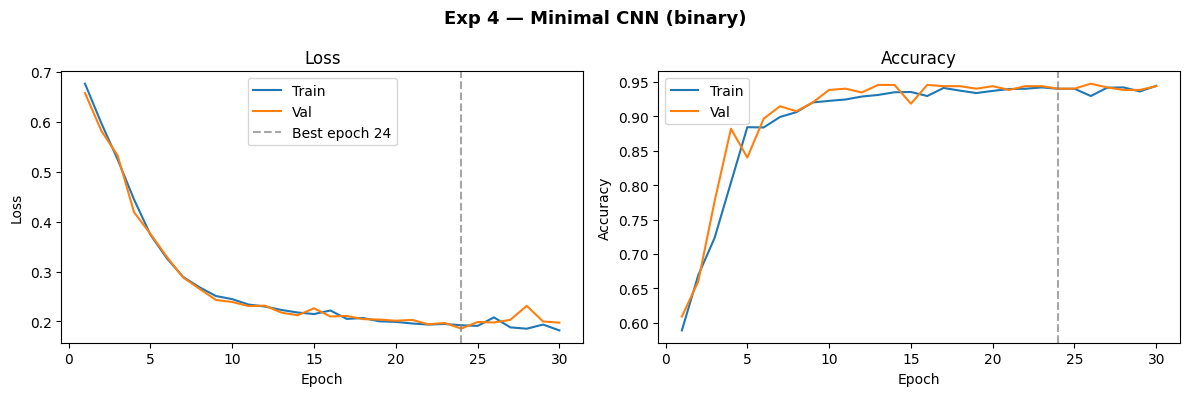

2026-06-20 21:00:56.863208: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



  Exp 4 — Minimal CNN binary (test)
              precision    recall  f1-score   support

       No DR       0.92      0.94      0.93       271
          DR       0.94      0.92      0.93       279

    accuracy                           0.93       550
   macro avg       0.93      0.93      0.93       550
weighted avg       0.93      0.93      0.93       550

  Accuracy         : 0.9291
  Weighted F1      : 0.9291
  AUC-ROC (macro)  : nan
  Quadratic Kappa  : 0.8582  <- PRIMARY METRIC
  Grade 3+4 Recall : 0.0000  <- CLINICAL PRIORITY
Saved: /kaggle/working/outputs/figures/confusion_matrices/exp4_minimal_cnn.png


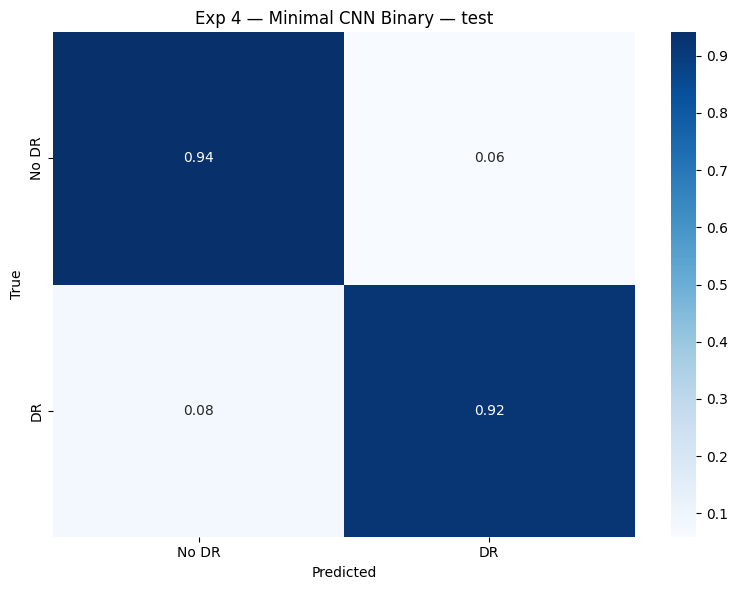

Binary AUC (DR detection): 0.9682


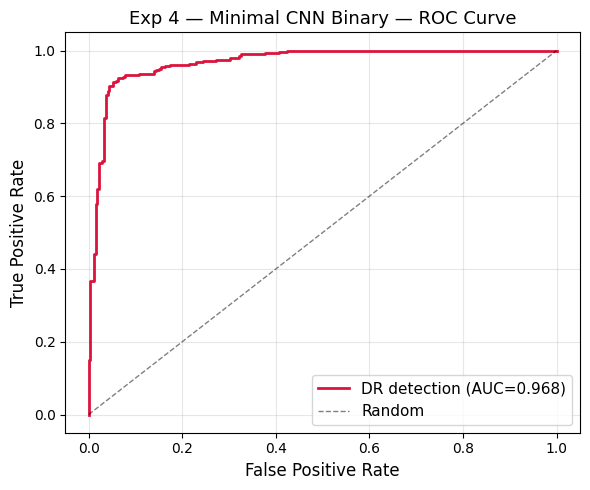

[Exp 4] Minimal CNN (binary, 2 conv blocks) — Kappa: 0.8582  Grade3+4 Recall: 0.9176

Exp 4 complete in 361.1s.


In [38]:
# ── Experiment 4 — Minimal CNN (binary: No DR vs DR) ────────────────────
# Screening baseline: can a tiny 2-block CNN detect the presence of DR?
# grade 0 = No DR (0), grades 1-4 = DR (1). No Ben Graham, no augmentation.

set_seeds(42)
_t0_exp4 = time.time()

# Binarise labels in temporary DataFrames — originals unchanged
_train_bin = train_df.copy(); _train_bin["diagnosis"] = (train_df["diagnosis"] > 0).astype(int)
_val_bin   = val_df.copy();   _val_bin["diagnosis"]   = (val_df["diagnosis"]   > 0).astype(int)
_test_bin  = test_df.copy();  _test_bin["diagnosis"]  = (test_df["diagnosis"]  > 0).astype(int)

_ds4_train = build_tf_dataset(_train_bin, TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=True,  cache=True,
                              apply_ben_graham=False, augment=False, seed=42)
_ds4_val   = build_tf_dataset(_val_bin,   TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=False, cache=True,
                              apply_ben_graham=False, augment=False, seed=42)
_ds4_test  = build_tf_dataset(_test_bin,  TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=False, cache=False,
                              apply_ben_graham=False, augment=False, seed=42)

_model4 = build_minimal_cnn(input_shape=(224, 224, 3), num_classes=2)
_model4.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
_model4.summary()

_cw4 = compute_class_weight("balanced", classes=np.array([0, 1]),
                             y=_train_bin["diagnosis"].values)
_class_weight4 = {0: float(_cw4[0]), 1: float(_cw4[1])}
print(f"Class weights (binary): {_class_weight4}")

_cb4 = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ModelCheckpoint(str(MODELS_DIR / "deep_learning" / "exp4_minimal_cnn.keras"),
                    save_best_only=True, verbose=0),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

print("\nTraining Exp 4 — Minimal CNN (binary)...")
_hist4 = _model4.fit(
    _ds4_train, validation_data=_ds4_val,
    epochs=30, callbacks=_cb4, class_weight=_class_weight4, verbose=1
)
_train_time_exp4 = time.time() - _t0_exp4

plot_learning_curves(_hist4, "Exp 4 — Minimal CNN (binary)",
    save_path=OUTPUTS_DIR / "figures" / "learning_curves" / "exp4_minimal_cnn.png")

res_exp4 = evaluate_model(_model4, _ds4_test, _test_bin["diagnosis"].values,
                           "Exp 4 — Minimal CNN binary (test)",
                           class_names=["No DR", "DR"], is_keras=True)

_dr_detect_recall4 = res_exp4["per_class_recall"].get(1, 0.0)

plot_confusion_matrix(
    _test_bin["diagnosis"].values, res_exp4["y_pred"], ["No DR", "DR"],
    "Exp 4 — Minimal CNN Binary — test",
    save_path=OUTPUTS_DIR / "figures" / "confusion_matrices" / "exp4_minimal_cnn.png"
)
# Binary ROC: label_binarize returns (n,1) for 2 classes, which breaks
# the multi-class plot_roc_curves helper — compute directly instead.
from sklearn.metrics import roc_curve as _roc_curve_fn, auc as _auc_fn
_fpr4, _tpr4, _ = _roc_curve_fn(_test_bin["diagnosis"].values,
                                 res_exp4["y_prob"][:, 1])
_roc_auc_exp4 = _auc_fn(_fpr4, _tpr4)
print(f"Binary AUC (DR detection): {_roc_auc_exp4:.4f}")

_fig4r, _ax4r = plt.subplots(figsize=(6, 5))
_ax4r.plot(_fpr4, _tpr4, color="crimson", lw=2,
           label=f"DR detection (AUC={_roc_auc_exp4:.3f})")
_ax4r.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Random")
_ax4r.set_xlabel("False Positive Rate", fontsize=12)
_ax4r.set_ylabel("True Positive Rate", fontsize=12)
_ax4r.set_title("Exp 4 — Minimal CNN Binary — ROC Curve", fontsize=13)
_ax4r.legend(fontsize=11); _ax4r.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(str(OUTPUTS_DIR / "figures" / "roc_curves" / "exp4_minimal_cnn.png"),
            dpi=150, bbox_inches="tight")
plt.show()

log_experiment(results_list, {
    "exp_id"             : 4,
    "approach"           : "Deep Learning — Sequential",
    "model_architecture" : "Minimal CNN (binary, 2 conv blocks)",
    "key_hyperparameters": "Adam(1e-3), sparse_CE, EarlyStopping(p=8), batch=32",
    "train_size"         : len(_train_bin),
    "val_size"           : len(_val_bin),
    "test_size"          : len(_test_bin),
    "preprocessing"      : "Resize 224x224, normalise [0,1], no Ben Graham",
    "augmentation"       : "None",
    "accuracy"           : res_exp4["accuracy"],
    "weighted_f1"        : res_exp4["weighted_f1"],
    "auc_roc"            : _roc_auc_exp4,
    "quadratic_kappa"    : res_exp4["quadratic_kappa"],
    "grade34_recall"     : _dr_detect_recall4,
    "class0_recall"      : res_exp4["per_class_recall"].get(0, 0.0),
    "class1_recall"      : _dr_detect_recall4,
    "class2_recall"      : None,
    "class3_recall"      : None,
    "class4_recall"      : None,
    "train_time_s"       : round(_train_time_exp4, 1),
    "observations"       : "Binary screening baseline; grade34_recall = DR detection recall",
})
print(f"\nExp 4 complete in {_train_time_exp4:.1f}s.")

Seeds set to 42. TF op determinism ENABLED.


Model: "deep_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             

 Total params: 1,244,197 (4.75 MB)

 Trainable params: 1,241,765 (4.74 MB)

 Non-trainable params: 2,432 (9.50 KB)

Class weights: {0: 0.40570071258907364, 1: 1.986046511627907, 2: 0.7330472103004292, 3: 3.7955555555555556, 4: 2.47536231884058}

Training Exp 5 — Deep CNN (5-class, no BG, no aug)...
Epoch 1/30


E0000 00:00:1781989263.498066      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deep_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.2918 - loss: 1.9120

2026-06-20 21:04:59.284866: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


81/81 ━━━━━━━━━━━━━━━━━━━━ 290s 775ms/step - accuracy: 0.3829 - loss: 1.7585 - val_accuracy: 0.0800 - val_loss: 1.8054 - learning_rate: 0.0010
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 176ms/step - accuracy: 0.4793 - loss: 1.5612 - val_accuracy: 0.1018 - val_loss: 2.7291 - learning_rate: 0.0010
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 176ms/step - accuracy: 0.5180 - loss: 1.4881 - val_accuracy: 0.1255 - val_loss: 2.2357 - learning_rate: 0.0010
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 175ms/step - accuracy: 0.5183 - loss: 1.4157 - val_accuracy: 0.1091 - val_loss: 2.8163 - learning_rate: 0.0010
Epoch 5/30
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.5697 - loss: 1.3276
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 176ms/step - accuracy: 0.5410 - loss: 1.3809 - val_accuracy: 0.0855 - val_loss: 2.1205 - learning_rate: 0.0010
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 176ms/step - accuracy: 0.5675 - loss: 1.3270 - val_a

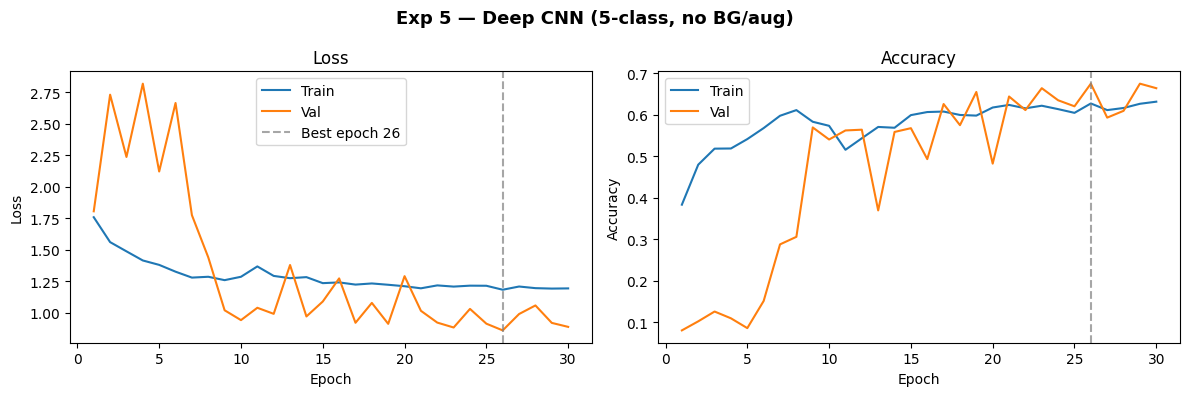

2026-06-20 21:13:33.624303: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



  Exp 5 — Deep CNN (test)
               precision    recall  f1-score   support

        No DR       0.91      0.94      0.92       271
         Mild       0.32      0.16      0.21        56
     Moderate       0.66      0.54      0.59       150
       Severe       0.17      0.45      0.25        29
Proliferative       0.30      0.30      0.30        44

     accuracy                           0.67       550
    macro avg       0.47      0.48      0.46       550
 weighted avg       0.69      0.67      0.67       550

  Accuracy         : 0.6727
  Weighted F1      : 0.6749
  AUC-ROC (macro)  : 0.8463
  Quadratic Kappa  : 0.7109  <- PRIMARY METRIC
  Grade 3+4 Recall : 0.3719  <- CLINICAL PRIORITY
Saved: /kaggle/working/outputs/figures/confusion_matrices/exp5_deep_cnn.png


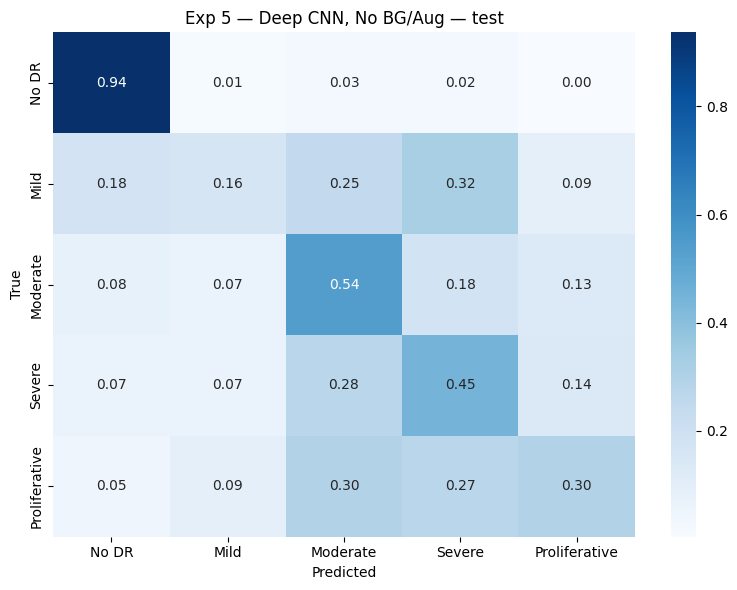

Saved: /kaggle/working/outputs/figures/roc_curves/exp5_deep_cnn.png


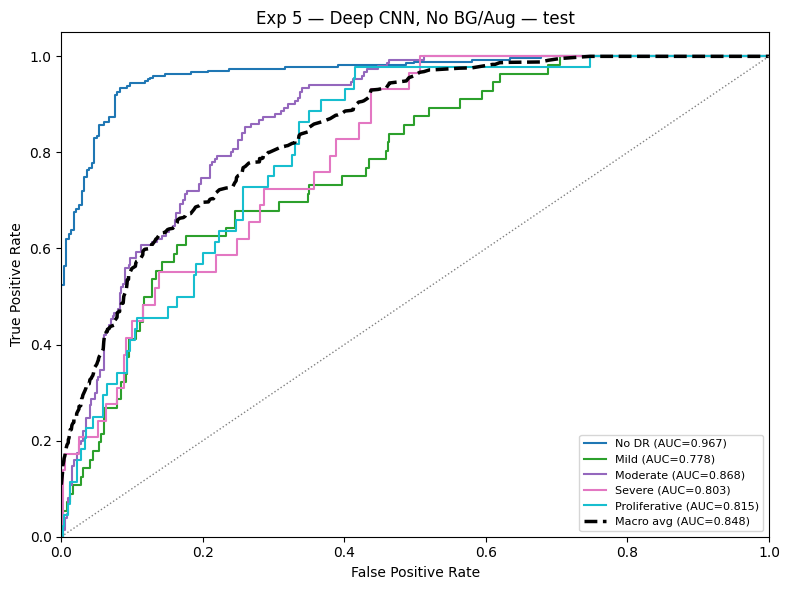

[Exp 5] Deep CNN (4 blocks, 32-256 filters) — Kappa: 0.7109  Grade3+4 Recall: 0.3719

Exp 5 complete in 705.3s.


In [39]:
# ── Experiment 5 — Deep CNN, 5-class, no Ben Graham, no augmentation ────
# Tests whether a deeper architecture improves over the pixel baselines.
# Ablation baseline for Exp 6: same architecture, no BG or augmentation.

set_seeds(42)
_t0_exp5 = time.time()

_ds5_train = build_tf_dataset(train_df, TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=True,  cache=True,
                              apply_ben_graham=False, augment=False, seed=42)
_ds5_val   = build_tf_dataset(val_df,   TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=False, cache=True,
                              apply_ben_graham=False, augment=False, seed=42)
_ds5_test  = build_tf_dataset(test_df,  TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=False, cache=False,
                              apply_ben_graham=False, augment=False, seed=42)

_model5 = build_deep_cnn(input_shape=(224, 224, 3), num_classes=5, dropout_rate=0.5)
_model5.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
_model5.summary()

_cw5 = compute_class_weight("balanced", classes=np.arange(5),
                             y=train_df["diagnosis"].values)
_class_weight5 = dict(enumerate([float(w) for w in _cw5]))
print(f"Class weights: {_class_weight5}")

_cb5 = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ModelCheckpoint(str(MODELS_DIR / "deep_learning" / "exp5_deep_cnn.keras"),
                    save_best_only=True, verbose=0),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

print("\nTraining Exp 5 — Deep CNN (5-class, no BG, no aug)...")
_hist5 = _model5.fit(
    _ds5_train, validation_data=_ds5_val,
    epochs=30, callbacks=_cb5, class_weight=_class_weight5, verbose=1
)
_train_time_exp5 = time.time() - _t0_exp5

plot_learning_curves(_hist5, "Exp 5 — Deep CNN (5-class, no BG/aug)",
    save_path=OUTPUTS_DIR / "figures" / "learning_curves" / "exp5_deep_cnn.png")

res_exp5 = evaluate_model(_model5, _ds5_test, test_df["diagnosis"].values,
                           "Exp 5 — Deep CNN (test)", is_keras=True)

plot_confusion_matrix(
    test_df["diagnosis"].values, res_exp5["y_pred"], CLASS_NAMES,
    "Exp 5 — Deep CNN, No BG/Aug — test",
    save_path=OUTPUTS_DIR / "figures" / "confusion_matrices" / "exp5_deep_cnn.png"
)
plot_roc_curves(
    test_df["diagnosis"].values, res_exp5["y_prob"], CLASS_NAMES,
    "Exp 5 — Deep CNN, No BG/Aug — test",
    save_path=OUTPUTS_DIR / "figures" / "roc_curves" / "exp5_deep_cnn.png"
)

log_experiment(results_list, {
    "exp_id"             : 5,
    "approach"           : "Deep Learning — Sequential",
    "model_architecture" : "Deep CNN (4 blocks, 32-256 filters)",
    "key_hyperparameters": "Adam(1e-3), sparse_CE, EarlyStopping(p=8), batch=32",
    "train_size"         : len(train_df),
    "val_size"           : len(val_df),
    "test_size"          : len(test_df),
    "preprocessing"      : "Resize 224x224, normalise [0,1], no Ben Graham",
    "augmentation"       : "None",
    "accuracy"           : res_exp5["accuracy"],
    "weighted_f1"        : res_exp5["weighted_f1"],
    "auc_roc"            : res_exp5["auc_roc"],
    "quadratic_kappa"    : res_exp5["quadratic_kappa"],
    "grade34_recall"     : res_exp5["grade34_recall"],
    "class0_recall"      : res_exp5["per_class_recall"][0],
    "class1_recall"      : res_exp5["per_class_recall"][1],
    "class2_recall"      : res_exp5["per_class_recall"][2],
    "class3_recall"      : res_exp5["per_class_recall"][3],
    "class4_recall"      : res_exp5["per_class_recall"][4],
    "train_time_s"       : round(_train_time_exp5, 1),
    "observations"       : "Ablation baseline for Exp 6; no BG or augmentation",
})
print(f"\nExp 5 complete in {_train_time_exp5:.1f}s.")

Seeds set to 42. TF op determinism ENABLED.

Training Exp 6 — Deep CNN (5-class, Ben Graham + augmentation)...
Epoch 1/30


E0000 00:00:1781990020.851025      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deep_cnn_1/dropout_4_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 555ms/step - accuracy: 0.1796 - loss: 2.0401

2026-06-20 21:18:28.830172: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


81/81 ━━━━━━━━━━━━━━━━━━━━ 345s 1s/step - accuracy: 0.1741 - loss: 1.9579 - val_accuracy: 0.2727 - val_loss: 1.4658 - learning_rate: 0.0010
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 553ms/step - accuracy: 0.2104 - loss: 1.7790 - val_accuracy: 0.2727 - val_loss: 1.5157 - learning_rate: 0.0010
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 561ms/step - accuracy: 0.1725 - loss: 1.8149 - val_accuracy: 0.4927 - val_loss: 1.5192 - learning_rate: 0.0010
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 561ms/step - accuracy: 0.2119 - loss: 1.8236 - val_accuracy: 0.4927 - val_loss: 1.4629 - learning_rate: 0.0010
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 558ms/step - accuracy: 0.2080 - loss: 1.7558 - val_accuracy: 0.0527 - val_loss: 1.6799 - learning_rate: 0.0010
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 569ms/step - accuracy: 0.1647 - loss: 1.7814 - val_accuracy: 0.2727 - val_loss: 1.6337 - learning_rate: 0.0010
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 559ms/step - accuracy: 0.1897 - loss: 1.7740 - val_ac

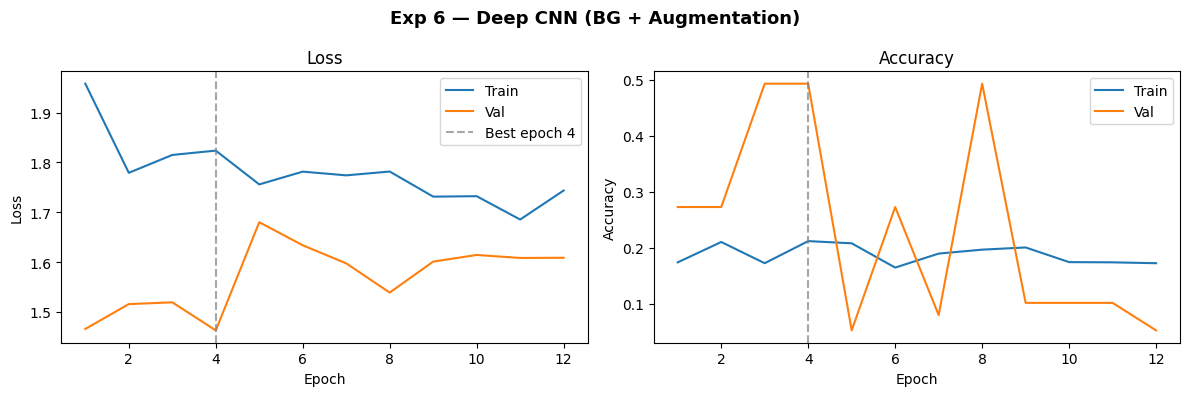

2026-06-20 21:28:41.802722: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



  Exp 6 — Deep CNN + BG + Aug (test)
               precision    recall  f1-score   support

        No DR       0.49      1.00      0.66       271
         Mild       0.00      0.00      0.00        56
     Moderate       0.00      0.00      0.00       150
       Severe       0.00      0.00      0.00        29
Proliferative       0.00      0.00      0.00        44

     accuracy                           0.49       550
    macro avg       0.10      0.20      0.13       550
 weighted avg       0.24      0.49      0.33       550

  Accuracy         : 0.4927
  Weighted F1      : 0.3253
  AUC-ROC (macro)  : 0.5358
  Quadratic Kappa  : 0.0000  <- PRIMARY METRIC
  Grade 3+4 Recall : 0.0000  <- CLINICAL PRIORITY
Saved: /kaggle/working/outputs/figures/confusion_matrices/exp6_deep_cnn_bg_aug.png


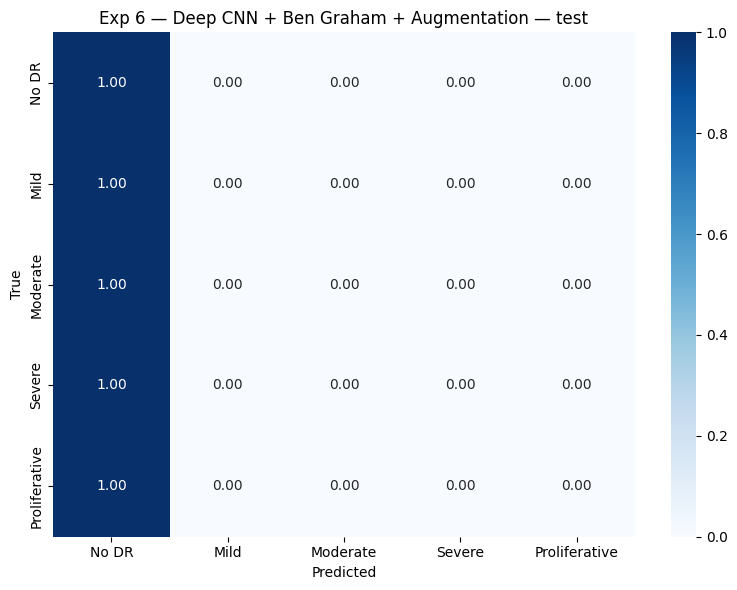

Saved: /kaggle/working/outputs/figures/roc_curves/exp6_deep_cnn_bg_aug.png


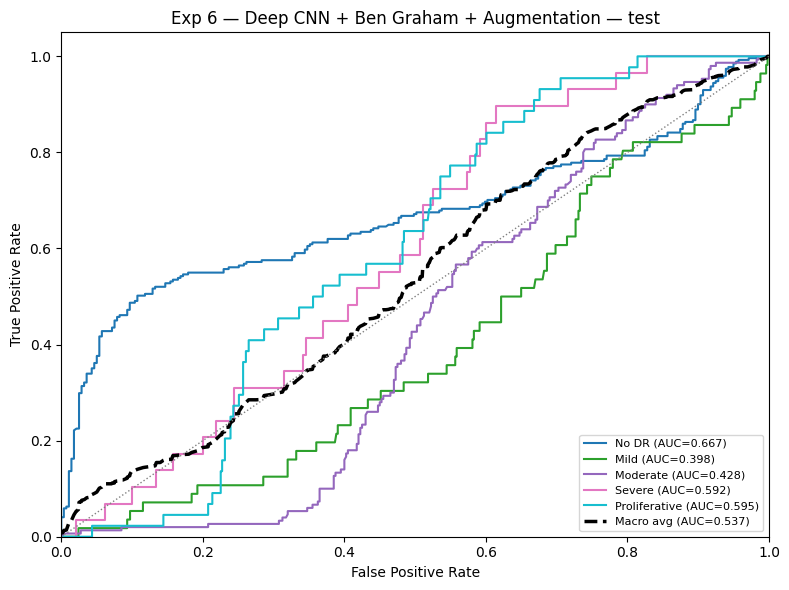

[Exp 6] Deep CNN (4 blocks, 32-256 filters) + BG + Aug — Kappa: 0.0000  Grade3+4 Recall: 0.0000

Exp 6 complete in 850.0s.

Phase 4 complete. Proceed to Section 9 (Functional API Experiments).


In [40]:
# ── Experiment 6 — Deep CNN, 5-class, Ben Graham + augmentation ─────────
# Ablation vs Exp 5: identical architecture; adds BG preprocessing + augmentation.
# Quantifies the contribution of preprocessing and augmentation to kappa/recall.

set_seeds(42)
_t0_exp6 = time.time()

_ds6_train = build_tf_dataset(train_df, TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=True,  cache=True,
                              apply_ben_graham=True, augment=True, seed=42)
_ds6_val   = build_tf_dataset(val_df,   TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=False, cache=True,
                              apply_ben_graham=True, augment=False, seed=42)
_ds6_test  = build_tf_dataset(test_df,  TRAIN_IMAGES_DIR, target_size=(224,224),
                              batch_size=32, shuffle=False, cache=False,
                              apply_ben_graham=True, augment=False, seed=42)

_model6 = build_deep_cnn(input_shape=(224, 224, 3), num_classes=5, dropout_rate=0.5)
_model6.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

_cw6 = compute_class_weight("balanced", classes=np.arange(5),
                             y=train_df["diagnosis"].values)
_class_weight6 = dict(enumerate([float(w) for w in _cw6]))

_cb6 = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ModelCheckpoint(str(MODELS_DIR / "deep_learning" / "exp6_deep_cnn_bg_aug.keras"),
                    save_best_only=True, verbose=0),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

print("\nTraining Exp 6 — Deep CNN (5-class, Ben Graham + augmentation)...")
_hist6 = _model6.fit(
    _ds6_train, validation_data=_ds6_val,
    epochs=30, callbacks=_cb6, class_weight=_class_weight6, verbose=1
)
_train_time_exp6 = time.time() - _t0_exp6

plot_learning_curves(_hist6, "Exp 6 — Deep CNN (BG + Augmentation)",
    save_path=OUTPUTS_DIR / "figures" / "learning_curves" / "exp6_deep_cnn_bg_aug.png")

res_exp6 = evaluate_model(_model6, _ds6_test, test_df["diagnosis"].values,
                           "Exp 6 — Deep CNN + BG + Aug (test)", is_keras=True)

plot_confusion_matrix(
    test_df["diagnosis"].values, res_exp6["y_pred"], CLASS_NAMES,
    "Exp 6 — Deep CNN + Ben Graham + Augmentation — test",
    save_path=OUTPUTS_DIR / "figures" / "confusion_matrices" / "exp6_deep_cnn_bg_aug.png"
)
plot_roc_curves(
    test_df["diagnosis"].values, res_exp6["y_prob"], CLASS_NAMES,
    "Exp 6 — Deep CNN + Ben Graham + Augmentation — test",
    save_path=OUTPUTS_DIR / "figures" / "roc_curves" / "exp6_deep_cnn_bg_aug.png"
)

log_experiment(results_list, {
    "exp_id"             : 6,
    "approach"           : "Deep Learning — Sequential",
    "model_architecture" : "Deep CNN (4 blocks, 32-256 filters) + BG + Aug",
    "key_hyperparameters": "Adam(1e-3), sparse_CE, EarlyStopping(p=8), batch=32",
    "train_size"         : len(train_df),
    "val_size"           : len(val_df),
    "test_size"          : len(test_df),
    "preprocessing"      : "Ben Graham (coeff=4, sigma=10), resize 224x224, normalise [0,1]",
    "augmentation"       : "RandomFlip+Rotation(30deg)+Zoom(15%)+Brightness+Contrast",
    "accuracy"           : res_exp6["accuracy"],
    "weighted_f1"        : res_exp6["weighted_f1"],
    "auc_roc"            : res_exp6["auc_roc"],
    "quadratic_kappa"    : res_exp6["quadratic_kappa"],
    "grade34_recall"     : res_exp6["grade34_recall"],
    "class0_recall"      : res_exp6["per_class_recall"][0],
    "class1_recall"      : res_exp6["per_class_recall"][1],
    "class2_recall"      : res_exp6["per_class_recall"][2],
    "class3_recall"      : res_exp6["per_class_recall"][3],
    "class4_recall"      : res_exp6["per_class_recall"][4],
    "train_time_s"       : round(_train_time_exp6, 1),
    "observations"       : "Ablation vs Exp 5: BG + aug benefit quantified",
})
print(f"\nExp 6 complete in {_train_time_exp6:.1f}s.")
print("\nPhase 4 complete. Proceed to Section 9 (Functional API Experiments).")

---
# Section 9 — Advanced Experiments (Exps 7–8)

Exp 7 uses the **Functional API** two-branch multi-scale architecture; Exp 8 performs a **manual hyperparameter grid search** over learning rate and dropout,
then retrains the best configuration for final evaluation.

| Exp | Model | Focus |
|-----|-------|-------|
| 7 | Multi-scale CNN (Functional API, 2 branches: 224 + 112) | Architecture: multi-scale lesion + global pattern capture |
| 8 | Deep CNN (grid-searched) | Hyperparameter: lr ∈ {1e-3, 5e-4} × dropout ∈ {0.3, 0.5} |

`build_multiscale_tf_dataset` is used for Exp 7 — it yields `((full_res, low_res), label)` pairs
and applies augmentation to the full-res branch, then derives the low-res view via `tf.image.resize`.

> **Runtime note**: On CPU, Exp 7 may take 1–3 hr and Exp 8 (4 grid combos + retrain) 2–4 hr.
> **Google Colab (free GPU) is strongly recommended for Sections 8 and 9.**

Seeds set to 42. TF op determinism ENABLED.


Model: "multiscale_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ full_res_input      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 224, 224,  │        896 │ full_res_input[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 224, 224,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 112, 112,  │          0 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ low_res_input       │ (None, 112, 112,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 112, 112,  │     18,496 │ dropout_8[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 112, 112,  │        896 │ low_res_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 112, 112,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 112, 112,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_25[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 56, 56,    │          0 │ batch_normalizat

 Total params: 427,525 (1.63 MB)

 Trainable params: 425,733 (1.62 MB)

 Non-trainable params: 1,792 (7.00 KB)

Class weights: {0: 0.40570071258907364, 1: 1.986046511627907, 2: 0.7330472103004292, 3: 3.7955555555555556, 4: 2.47536231884058}

Training Exp 7 — Multi-scale CNN (Functional API)...
Epoch 1/30


E0000 00:00:1781990931.634373      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/multiscale_cnn_1/dropout_8_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 559ms/step - accuracy: 0.1821 - loss: 2.4600

2026-06-20 21:33:42.908340: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


81/81 ━━━━━━━━━━━━━━━━━━━━ 352s 1s/step - accuracy: 0.1889 - loss: 2.2712 - val_accuracy: 0.2727 - val_loss: 1.5219 - learning_rate: 0.0010
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 568ms/step - accuracy: 0.1940 - loss: 2.0893 - val_accuracy: 0.2727 - val_loss: 1.5841 - learning_rate: 0.0010
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 566ms/step - accuracy: 0.2139 - loss: 2.0174 - val_accuracy: 0.3836 - val_loss: 1.6454 - learning_rate: 0.0010
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 570ms/step - accuracy: 0.1975 - loss: 1.9666 - val_accuracy: 0.2727 - val_loss: 1.5712 - learning_rate: 0.0010
Epoch 5/30
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 568ms/step - accuracy: 0.2301 - loss: 1.8562
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 570ms/step - accuracy: 0.2100 - loss: 1.9165 - val_accuracy: 0.1018 - val_loss: 1.6595 - learning_rate: 0.0010
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 570ms/step - accuracy: 0.2002 - loss: 1.8086 - val_accu

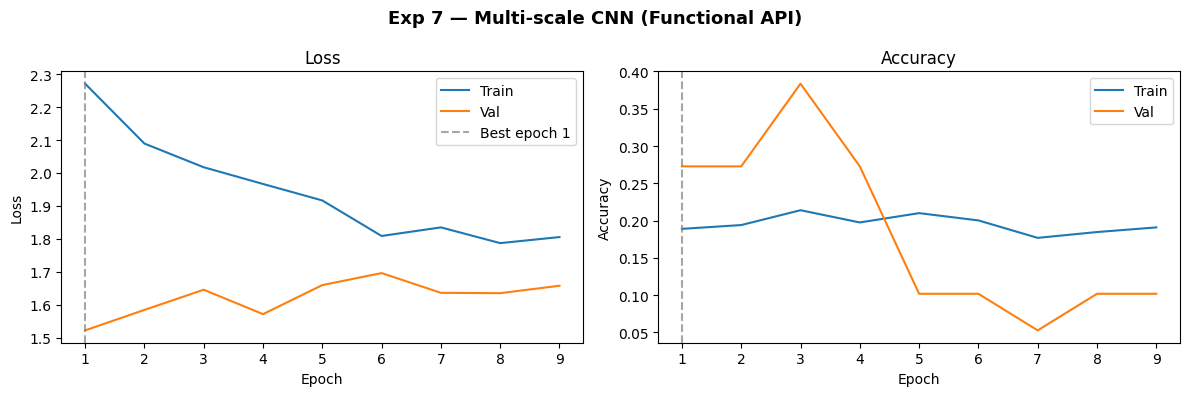

2026-06-20 21:41:43.273671: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



  Exp 7 — Multi-scale CNN (test)
               precision    recall  f1-score   support

        No DR       0.00      0.00      0.00       271
         Mild       0.00      0.00      0.00        56
     Moderate       0.27      1.00      0.43       150
       Severe       0.00      0.00      0.00        29
Proliferative       0.00      0.00      0.00        44

     accuracy                           0.27       550
    macro avg       0.05      0.20      0.09       550
 weighted avg       0.07      0.27      0.12       550

  Accuracy         : 0.2727
  Weighted F1      : 0.1169
  AUC-ROC (macro)  : 0.4615
  Quadratic Kappa  : 0.0000  <- PRIMARY METRIC
  Grade 3+4 Recall : 0.0000  <- CLINICAL PRIORITY
Saved: /kaggle/working/outputs/figures/confusion_matrices/exp7_multiscale_cnn.png


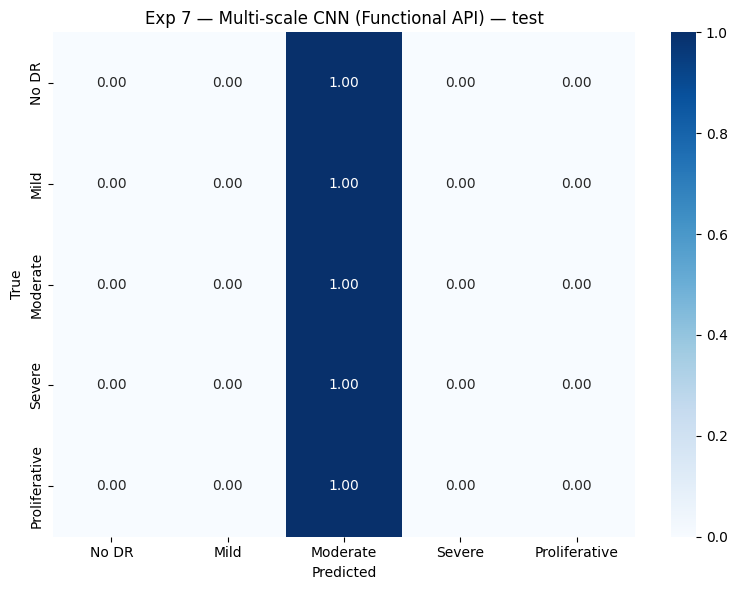

Saved: /kaggle/working/outputs/figures/roc_curves/exp7_multiscale_cnn.png


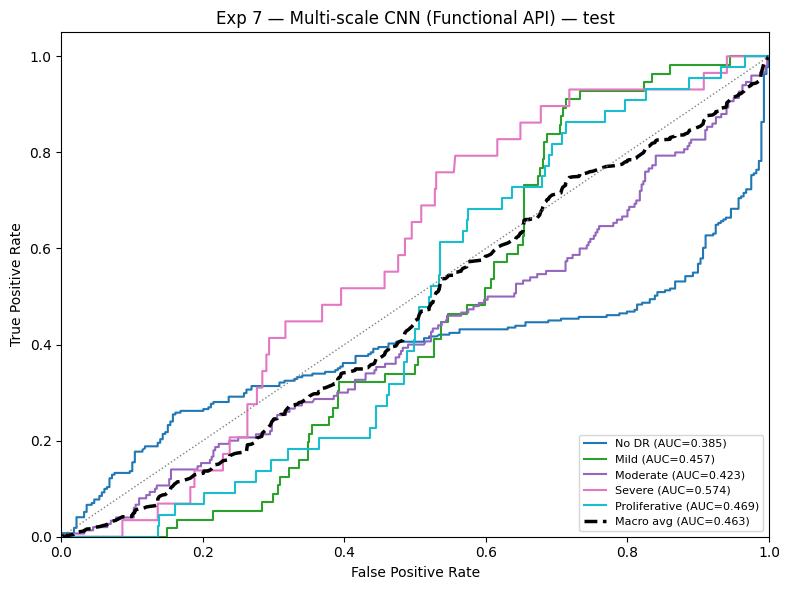

[Exp 7] Multi-scale CNN (2 branches: 224+112, Functional API) — Kappa: 0.0000  Grade3+4 Recall: 0.0000

Exp 7 complete in 723.0s.


In [41]:
# ── Experiment 7 — Multi-scale CNN (Functional API) ─────────────────────
# Two-branch architecture: full-res (224x224) captures fine lesion details;
# low-res (112x112) captures global vascular structure.
# Best preprocessing from Exp 6: Ben Graham + augmentation.

set_seeds(42)
_t0_exp7 = time.time()

# build_multiscale_tf_dataset yields ((full_img, low_img), label)
# Keras maps positionally to [full_res_input, low_res_input]
_ds7_train = build_multiscale_tf_dataset(
    train_df, TRAIN_IMAGES_DIR,
    full_res_size=(224, 224), low_res_size=(112, 112),
    batch_size=32, shuffle=True, cache=True,
    apply_ben_graham=True, augment=True, seed=42
)
_ds7_val = build_multiscale_tf_dataset(
    val_df, TRAIN_IMAGES_DIR,
    full_res_size=(224, 224), low_res_size=(112, 112),
    batch_size=32, shuffle=False, cache=True,
    apply_ben_graham=True, augment=False, seed=42
)
_ds7_test = build_multiscale_tf_dataset(
    test_df, TRAIN_IMAGES_DIR,
    full_res_size=(224, 224), low_res_size=(112, 112),
    batch_size=32, shuffle=False, cache=False,
    apply_ben_graham=True, augment=False, seed=42
)

_model7 = build_multiscale_functional_model(
    full_res_shape=(224, 224, 3), low_res_shape=(112, 112, 3), num_classes=5
)
_model7.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
_model7.summary()

_cw7 = compute_class_weight("balanced", classes=np.arange(5),
                             y=train_df["diagnosis"].values)
_class_weight7 = dict(enumerate([float(w) for w in _cw7]))
print(f"Class weights: {_class_weight7}")

_cb7 = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ModelCheckpoint(str(MODELS_DIR / "deep_learning" / "exp7_multiscale_cnn.keras"),
                    save_best_only=True, verbose=0),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

print("\nTraining Exp 7 — Multi-scale CNN (Functional API)...")
_hist7 = _model7.fit(
    _ds7_train, validation_data=_ds7_val,
    epochs=30, callbacks=_cb7, class_weight=_class_weight7, verbose=1
)
_train_time_exp7 = time.time() - _t0_exp7

plot_learning_curves(_hist7, "Exp 7 — Multi-scale CNN (Functional API)",
    save_path=OUTPUTS_DIR / "figures" / "learning_curves" / "exp7_multiscale_cnn.png")

# evaluate_model with is_keras=True: iterates dataset, batch[0] = (full, low)
# model.predict((full, low)) works for multi-input Functional models
res_exp7 = evaluate_model(_model7, _ds7_test, test_df["diagnosis"].values,
                           "Exp 7 — Multi-scale CNN (test)", is_keras=True)

plot_confusion_matrix(
    test_df["diagnosis"].values, res_exp7["y_pred"], CLASS_NAMES,
    "Exp 7 — Multi-scale CNN (Functional API) — test",
    save_path=OUTPUTS_DIR / "figures" / "confusion_matrices" / "exp7_multiscale_cnn.png"
)
plot_roc_curves(
    test_df["diagnosis"].values, res_exp7["y_prob"], CLASS_NAMES,
    "Exp 7 — Multi-scale CNN (Functional API) — test",
    save_path=OUTPUTS_DIR / "figures" / "roc_curves" / "exp7_multiscale_cnn.png"
)

log_experiment(results_list, {
    "exp_id"             : 7,
    "approach"           : "Deep Learning — Functional API",
    "model_architecture" : "Multi-scale CNN (2 branches: 224+112, Functional API)",
    "key_hyperparameters": "Adam(1e-3), sparse_CE, EarlyStopping(p=8), batch=32",
    "train_size"         : len(train_df),
    "val_size"           : len(val_df),
    "test_size"          : len(test_df),
    "preprocessing"      : "Ben Graham (coeff=4, sigma=10), resize 224x224+112x112, normalise [0,1]",
    "augmentation"       : "RandomFlip+Rotation(30deg)+Zoom(15%)+Brightness+Contrast (full-res branch)",
    "accuracy"           : res_exp7["accuracy"],
    "weighted_f1"        : res_exp7["weighted_f1"],
    "auc_roc"            : res_exp7["auc_roc"],
    "quadratic_kappa"    : res_exp7["quadratic_kappa"],
    "grade34_recall"     : res_exp7["grade34_recall"],
    "class0_recall"      : res_exp7["per_class_recall"][0],
    "class1_recall"      : res_exp7["per_class_recall"][1],
    "class2_recall"      : res_exp7["per_class_recall"][2],
    "class3_recall"      : res_exp7["per_class_recall"][3],
    "class4_recall"      : res_exp7["per_class_recall"][4],
    "train_time_s"       : round(_train_time_exp7, 1),
    "observations"       : "Two-branch Functional API; full-res captures lesions, low-res captures vascular structure",
})
print(f"\nExp 7 complete in {_train_time_exp7:.1f}s.")

Seeds set to 42. TF op determinism ENABLED.
=== Phase 1: Grid Search ===
Searching 4 combinations (10 epochs / patience=3 each)

Seeds set to 42. TF op determinism ENABLED.


E0000 00:00:1781991711.454073      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deep_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
2026-06-20 21:46:54.725070: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


  [1/4] lr=1e-03  dropout=0.3  val_loss=1.5420  val_acc=0.4927  (4 epochs)
Seeds set to 42. TF op determinism ENABLED.


2026-06-20 21:50:08.331666: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}
E0000 00:00:1781992213.917883      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deep_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  [2/4] lr=1e-03  dropout=0.5  val_loss=1.3777  val_acc=0.4927  (9 epochs)
Seeds set to 42. TF op determinism ENABLED.


2026-06-20 21:56:59.440925: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}
E0000 00:00:1781992624.935790      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deep_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  [3/4] lr=5e-04  dropout=0.3  val_loss=1.5606  val_acc=0.2727  (7 epochs)
Seeds set to 42. TF op determinism ENABLED.


2026-06-20 22:02:20.751778: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}
E0000 00:00:1781992946.215736      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deep_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  [4/4] lr=5e-04  dropout=0.5  val_loss=1.5264  val_acc=0.1018  (4 epochs)

Grid search results:
    lr  dropout  best_val_loss  best_val_acc  epochs_run
0.0010      0.5         1.3777        0.4927           9
0.0005      0.5         1.5264        0.1018           4
0.0010      0.3         1.5420        0.4927           4
0.0005      0.3         1.5606        0.2727           7

Best: lr=1e-03, dropout=0.5

=== Phase 2: Full Retraining with Best Hyperparameters ===
Seeds set to 42. TF op determinism ENABLED.
Retraining with lr=1e-03, dropout=0.5...
Epoch 1/30


2026-06-20 22:05:27.699923: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}
E0000 00:00:1781993133.146764      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deep_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


81/81 ━━━━━━━━━━━━━━━━━━━━ 52s 563ms/step - accuracy: 0.2018 - loss: 1.9740 - val_accuracy: 0.2164 - val_loss: 1.5721 - learning_rate: 0.0010
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 549ms/step - accuracy: 0.2119 - loss: 1.8423 - val_accuracy: 0.0800 - val_loss: 1.6397 - learning_rate: 0.0010
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 551ms/step - accuracy: 0.1936 - loss: 1.9006 - val_accuracy: 0.1018 - val_loss: 1.6324 - learning_rate: 0.0010
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 552ms/step - accuracy: 0.1924 - loss: 1.8366 - val_accuracy: 0.2727 - val_loss: 1.5797 - learning_rate: 0.0010
Epoch 5/30
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 545ms/step - accuracy: 0.2329 - loss: 1.8578
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 548ms/step - accuracy: 0.2229 - loss: 1.8093 - val_accuracy: 0.0527 - val_loss: 1.6328 - learning_rate: 0.0010
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 550ms/step - accuracy: 0.2026 - loss: 1.8182 - val_ac

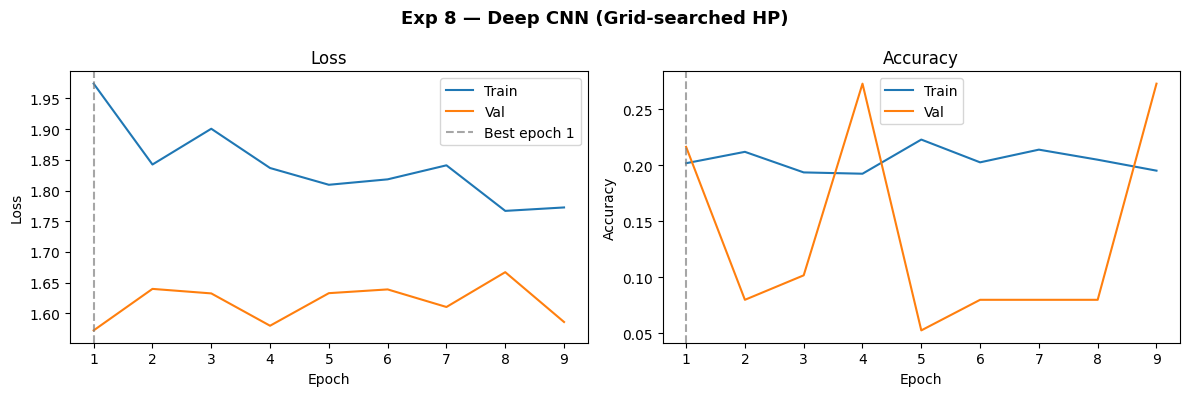

2026-06-20 22:13:18.523986: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



  Exp 8 — Deep CNN HP-tuned (test)
               precision    recall  f1-score   support

        No DR       0.74      0.29      0.41       271
         Mild       0.12      0.95      0.21        56
     Moderate       0.00      0.00      0.00       150
       Severe       0.00      0.00      0.00        29
Proliferative       0.00      0.00      0.00        44

     accuracy                           0.24       550
    macro avg       0.17      0.25      0.13       550
 weighted avg       0.38      0.24      0.23       550

  Accuracy         : 0.2382
  Weighted F1      : 0.2260
  AUC-ROC (macro)  : 0.5474
  Quadratic Kappa  : 0.0980  <- PRIMARY METRIC
  Grade 3+4 Recall : 0.0000  <- CLINICAL PRIORITY
Saved: /kaggle/working/outputs/figures/confusion_matrices/exp8_deep_cnn_tuned.png


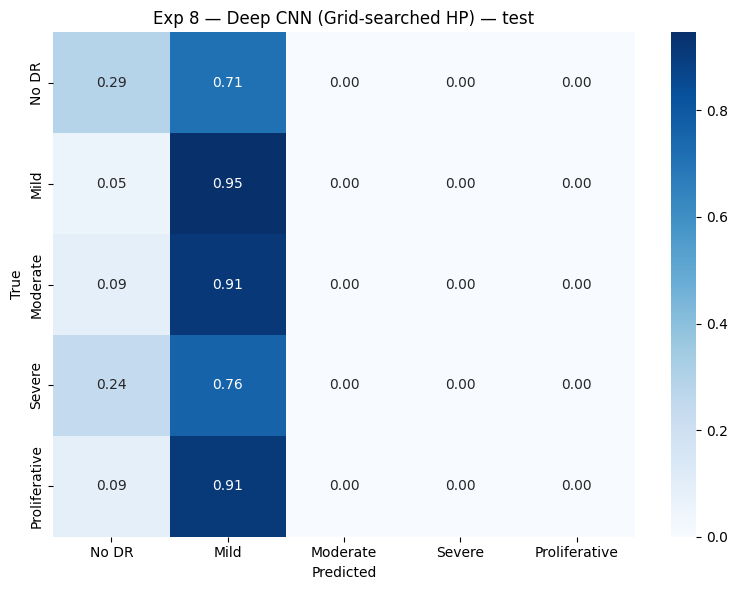

Saved: /kaggle/working/outputs/figures/roc_curves/exp8_deep_cnn_tuned.png


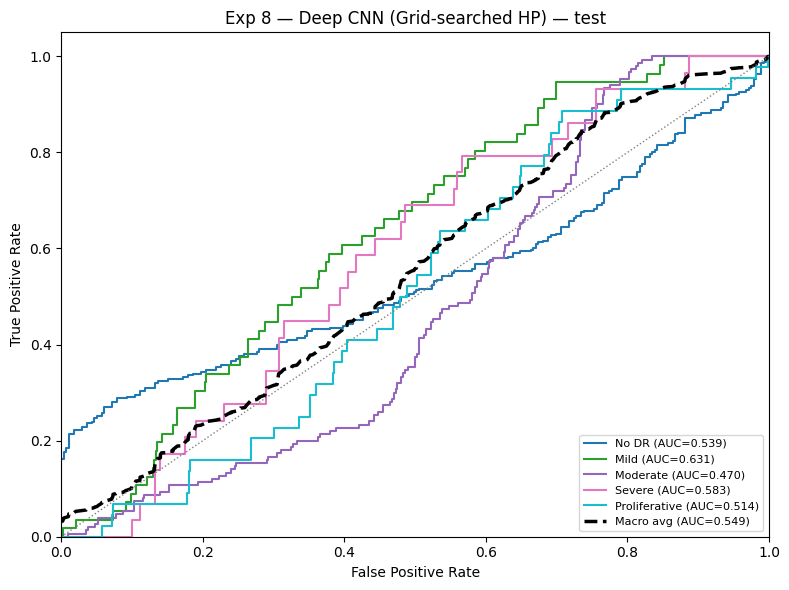

[Exp 8] Deep CNN (4 blocks), lr=1e-03, dropout=0.5 — Kappa: 0.0980  Grade3+4 Recall: 0.0000

Exp 8 complete in 1832.3s.

Phase 5 complete. Proceed to Section 10 (Consolidated Results).


In [42]:
# ── Experiment 8 — Hyperparameter Grid Search + Best Model Retraining ───
# Manual grid search: lr x dropout_rate on Deep CNN with BG + augmentation.
# Phase 1 (search): 4 combinations x 10 epochs (patience=3) on val_loss.
# Phase 2 (retrain): best combination trained for 30 epochs (patience=8).

set_seeds(42)
_t0_exp8 = time.time()

_search_space = [
    {"lr": 1e-3,  "dropout": 0.3},
    {"lr": 1e-3,  "dropout": 0.5},
    {"lr": 5e-4,  "dropout": 0.3},
    {"lr": 5e-4,  "dropout": 0.5},
]

# Build datasets once; cache=True means images load once and are reused
# across all grid iterations (avoids repeated disk I/O per combination)
_ds8_train = build_tf_dataset(train_df, TRAIN_IMAGES_DIR, target_size=(224, 224),
                              batch_size=32, shuffle=True, cache=True,
                              apply_ben_graham=True, augment=True, seed=42)
_ds8_val   = build_tf_dataset(val_df,   TRAIN_IMAGES_DIR, target_size=(224, 224),
                              batch_size=32, shuffle=False, cache=True,
                              apply_ben_graham=True, augment=False, seed=42)

_cw8 = compute_class_weight("balanced", classes=np.arange(5),
                             y=train_df["diagnosis"].values)
_class_weight8 = dict(enumerate([float(w) for w in _cw8]))

print("=== Phase 1: Grid Search ===")
print(f"Searching {len(_search_space)} combinations (10 epochs / patience=3 each)\n")

_grid_log = []
for _gi, _params in enumerate(_search_space):
    keras.backend.clear_session()
    set_seeds(42)
    _gm = build_deep_cnn(input_shape=(224, 224, 3), num_classes=5,
                          dropout_rate=_params["dropout"])
    _gm.compile(optimizer=keras.optimizers.Adam(_params["lr"]),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    _gh = _gm.fit(
        _ds8_train, validation_data=_ds8_val, epochs=10,
        callbacks=[EarlyStopping(monitor="val_loss", patience=3,
                                 restore_best_weights=True)],
        class_weight=_class_weight8, verbose=0
    )
    _best_val_loss = min(_gh.history["val_loss"])
    _best_val_acc  = max(_gh.history["val_accuracy"])
    _result = {**_params,
               "best_val_loss": round(_best_val_loss, 4),
               "best_val_acc" : round(_best_val_acc,  4),
               "epochs_run"   : len(_gh.history["val_loss"])}
    _grid_log.append(_result)
    print(f"  [{_gi+1}/4] lr={_params["lr"]:.0e}  dropout={_params["dropout"]}"  
          f"  val_loss={_best_val_loss:.4f}  val_acc={_best_val_acc:.4f}"  
          f"  ({_result["epochs_run"]} epochs)")
    del _gm, _gh

print("\nGrid search results:")
_grid_df = pd.DataFrame(_grid_log).sort_values("best_val_loss")
print(_grid_df.to_string(index=False))

_best_params = _grid_log[int(np.argmin([r["best_val_loss"] for r in _grid_log]))]
print(f"\nBest: lr={_best_params["lr"]:.0e}, dropout={_best_params["dropout"]}")

print("\n=== Phase 2: Full Retraining with Best Hyperparameters ===")
keras.backend.clear_session()
set_seeds(42)

_ds8_test = build_tf_dataset(test_df, TRAIN_IMAGES_DIR, target_size=(224, 224),
                             batch_size=32, shuffle=False, cache=False,
                             apply_ben_graham=True, augment=False, seed=42)

_model8 = build_deep_cnn(input_shape=(224, 224, 3), num_classes=5,
                          dropout_rate=_best_params["dropout"])
_model8.compile(
    optimizer=keras.optimizers.Adam(_best_params["lr"]),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

_cb8 = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ModelCheckpoint(str(MODELS_DIR / "deep_learning" / "exp8_deep_cnn_tuned.keras"),
                    save_best_only=True, verbose=0),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

print(f"Retraining with lr={_best_params["lr"]:.0e}, dropout={_best_params["dropout"]}...")
_hist8 = _model8.fit(
    _ds8_train, validation_data=_ds8_val,
    epochs=30, callbacks=_cb8, class_weight=_class_weight8, verbose=1
)
_train_time_exp8 = time.time() - _t0_exp8

plot_learning_curves(_hist8, "Exp 8 — Deep CNN (Grid-searched HP)",
    save_path=OUTPUTS_DIR / "figures" / "learning_curves" / "exp8_deep_cnn_tuned.png")

res_exp8 = evaluate_model(_model8, _ds8_test, test_df["diagnosis"].values,
                           "Exp 8 — Deep CNN HP-tuned (test)", is_keras=True)

plot_confusion_matrix(
    test_df["diagnosis"].values, res_exp8["y_pred"], CLASS_NAMES,
    "Exp 8 — Deep CNN (Grid-searched HP) — test",
    save_path=OUTPUTS_DIR / "figures" / "confusion_matrices" / "exp8_deep_cnn_tuned.png"
)
plot_roc_curves(
    test_df["diagnosis"].values, res_exp8["y_prob"], CLASS_NAMES,
    "Exp 8 — Deep CNN (Grid-searched HP) — test",
    save_path=OUTPUTS_DIR / "figures" / "roc_curves" / "exp8_deep_cnn_tuned.png"
)

log_experiment(results_list, {
    "exp_id"             : 8,
    "approach"           : "Deep Learning — HP Search",
    "model_architecture" : f"Deep CNN (4 blocks), lr={_best_params['lr']:.0e}, dropout={_best_params['dropout']}",
    "key_hyperparameters": f"lr={_best_params['lr']:.0e}, dropout={_best_params['dropout']}, Adam, sparse_CE, EarlyStopping(p=8)",
    "train_size"         : len(train_df),
    "val_size"           : len(val_df),
    "test_size"          : len(test_df),
    "preprocessing"      : "Ben Graham (coeff=4, sigma=10), resize 224x224, normalise [0,1]",
    "augmentation"       : "RandomFlip+Rotation(30deg)+Zoom(15%)+Brightness+Contrast",
    "accuracy"           : res_exp8["accuracy"],
    "weighted_f1"        : res_exp8["weighted_f1"],
    "auc_roc"            : res_exp8["auc_roc"],
    "quadratic_kappa"    : res_exp8["quadratic_kappa"],
    "grade34_recall"     : res_exp8["grade34_recall"],
    "class0_recall"      : res_exp8["per_class_recall"][0],
    "class1_recall"      : res_exp8["per_class_recall"][1],
    "class2_recall"      : res_exp8["per_class_recall"][2],
    "class3_recall"      : res_exp8["per_class_recall"][3],
    "class4_recall"      : res_exp8["per_class_recall"][4],
    "train_time_s"       : round(_train_time_exp8, 1),
    "observations"       : (
        f"Grid search: {len(_search_space)} combos (lr x dropout); "
        f"best lr={_best_params['lr']:.0e}, dropout={_best_params['dropout']}"
    ),
})
print(f"\nExp 8 complete in {_train_time_exp8:.1f}s.")
print("\nPhase 5 complete. Proceed to Section 10 (Consolidated Results).")

---
# Section 10 — Consolidated Results

All eight experiments are collected from `results_list` into a single DataFrame
and ranked by **Quadratic Weighted Kappa** (primary metric) and **Grade 3+4 Recall**
(clinical priority metric).

In [43]:
results_df = results_to_dataframe(results_list)

# Display columns in a logical order
_display_cols = [
    "exp_id", "approach", "model_architecture",
    "accuracy", "weighted_f1", "auc_roc", "quadratic_kappa",
    "grade34_recall", "class0_recall", "class1_recall",
    "class2_recall", "class3_recall", "class4_recall",
    "train_time_s", "observations",
]
_show_cols = [c for c in _display_cols if c in results_df.columns]

print("=== All Experiments — sorted by Quadratic Weighted Kappa ===")
_sorted = results_df.sort_values("quadratic_kappa", ascending=False).reset_index(drop=True)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:.4f}".format)
display(_sorted[_show_cols])

# Highlight best experiment
_best_idx = results_df["quadratic_kappa"].idxmax()
_best = results_df.loc[_best_idx]
print(f"\nBest model  : Exp {int(_best['exp_id'])} — {_best['model_architecture']}")
print(f"  Kappa     : {_best['quadratic_kappa']:.4f}")
print(f"  Gr3+4 Rec : {_best['grade34_recall']:.4f}")
print(f"  Weighted F1: {_best['weighted_f1']:.4f}")

# Save results table to CSV
_csv_path = OUTPUTS_DIR / "results_table.csv"
results_df.to_csv(_csv_path, index=False)
print(f"\nResults saved to {_csv_path}")

# Full-schema DataFrame (includes classX_recall, train_time_s, preprocessing)
# results_to_dataframe() returns display columns only; _full_results_df is
# used by Sections 11-13 for columns outside that display set.
_full_results_df = pd.DataFrame(results_list)
for _fc in ["accuracy","weighted_f1","quadratic_kappa","auc_roc","grade34_recall",
            "class0_recall","class1_recall","class2_recall","class3_recall",
            "class4_recall","train_time_s"]:
    if _fc in _full_results_df.columns:
        _full_results_df[_fc] = pd.to_numeric(_full_results_df[_fc], errors="coerce")

=== All Experiments — sorted by Quadratic Weighted Kappa ===


,exp_id,approach,model_architecture,accuracy,weighted_f1,auc_roc,quadratic_kappa,grade34_recall,observations
0,4,Deep Learning — Sequential,"Minimal CNN (binary, 2 conv blocks)",0.9291,0.9291,0.9682,0.8582,0.9176,Binary screening baseline; grade34_recall = DR detection...
1,3,Traditional ML,Random Forest + SMOTE,0.7400,0.7116,0.8650,0.7290,0.1317,SMOTE vs class_weight; RF captures non-linear feature in...
2,2,Traditional ML,SVM (RBF kernel),0.7382,0.6983,0.8701,0.7232,0.1203,RBF SVM on engineered features; tests kernel non-lineari...
3,5,Deep Learning — Sequential,"Deep CNN (4 blocks, 32-256 filters)",0.6727,0.6749,0.8463,0.7109,0.3719,Ablation baseline for Exp 6; no BG or augmentation
4,1,Traditional ML,Logistic Regression + PCA(200),0.6545,0.6707,0.8344,0.6299,0.2688,Raw pixel baseline; low kappa expected — no spatial inva...
5,8,Deep Learning — HP Search,"Deep CNN (4 blocks), lr=1e-03, dropout=0.5",0.2382,0.2260,0.5474,0.0980,0.0000,"Grid search: 4 combos (lr x dropout); best lr=1e-03, dro..."
6,6,Deep Learning — Sequential,"Deep CNN (4 blocks, 32-256 filters) + BG + Aug",0.4927,0.3253,0.5358,0.0000,0.0000,Ablation vs Exp 5: BG + aug benefit quantified
7,7,Deep Learning — Functional API,"Multi-scale CNN (2 branches: 224+112, Functional API)",0.2727,0.1169,0.4615,0.0000,0.0000,"Two-branch Functional API; full-res captures lesions, lo..."



Best model  : Exp 4 — Minimal CNN (binary, 2 conv blocks)
  Kappa     : 0.8582
  Gr3+4 Rec : 0.9176
  Weighted F1: 0.9291

Results saved to /kaggle/working/outputs/results_table.csv


---
# Section 11 — Cross-Experiment Visualisations

Bar charts comparing all experiments on the four key metrics, plus a heatmap
of per-class recall across experiments.

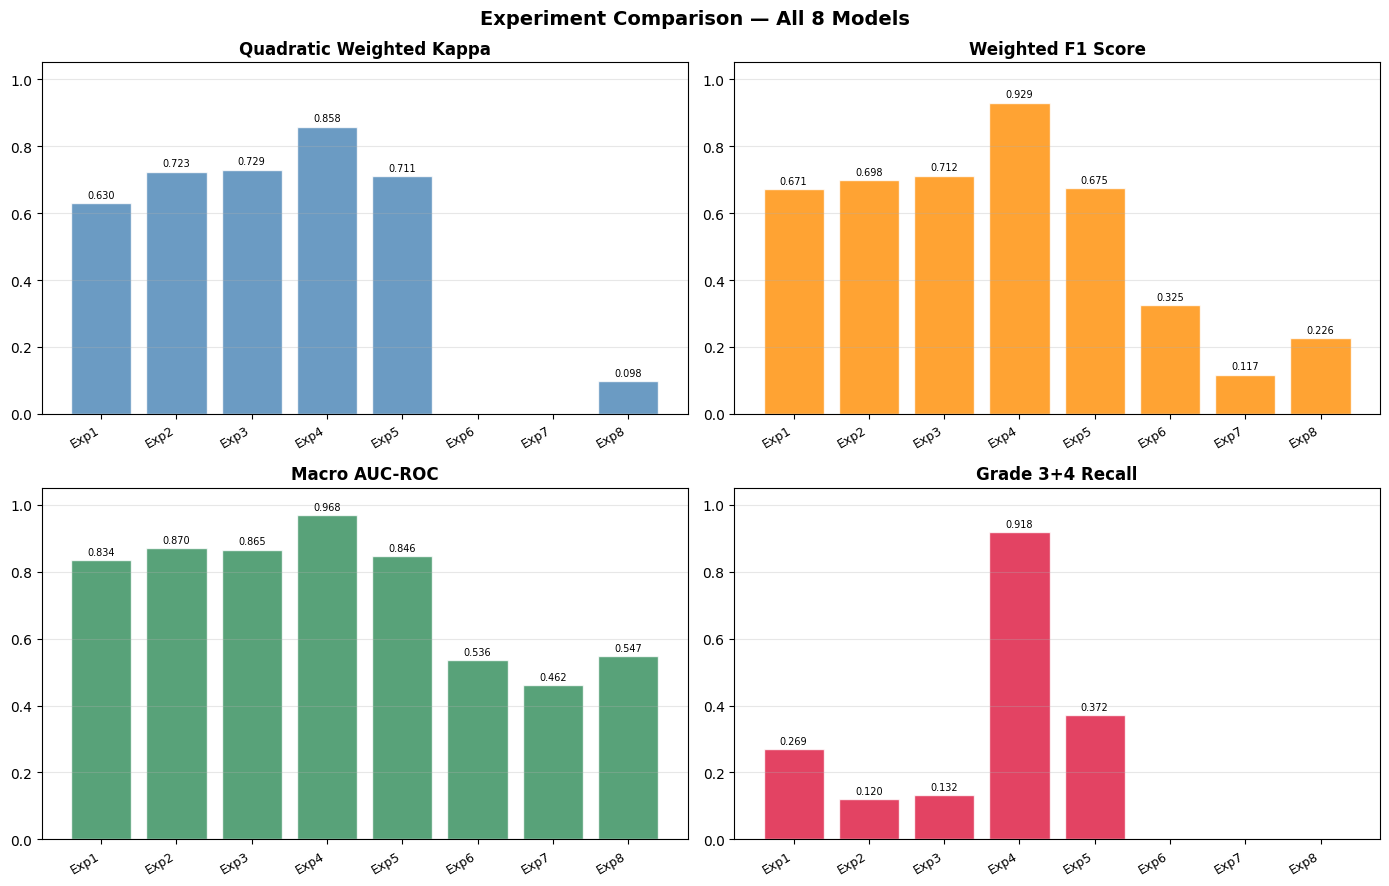

Saved: /kaggle/working/outputs/figures/experiment_comparison_bars.png


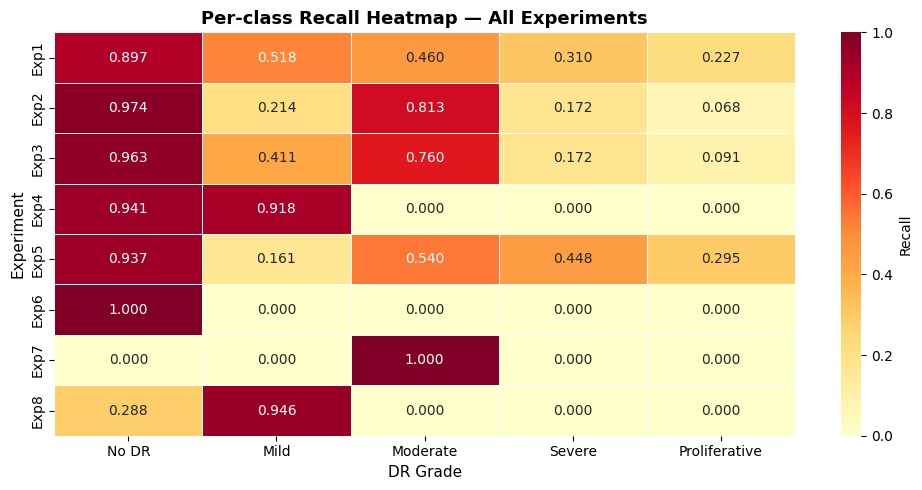

Saved: /kaggle/working/outputs/figures/recall_heatmap.png


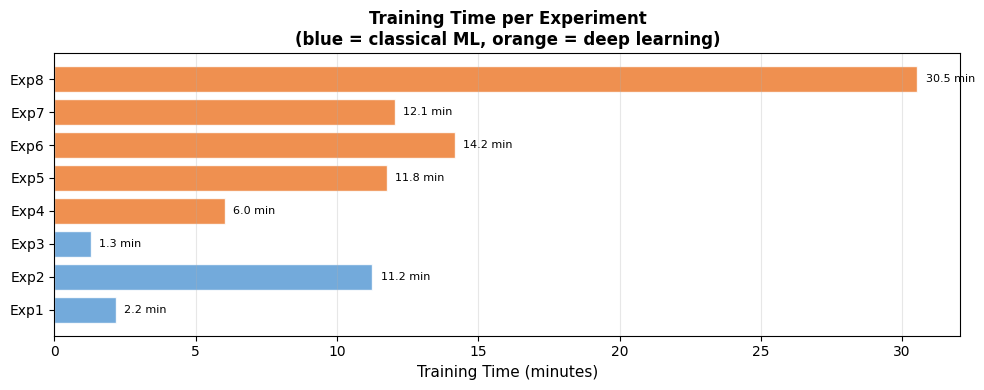

Saved: /kaggle/working/outputs/figures/training_time_comparison.png


In [44]:
# ── Bar charts: four metrics across all experiments ─────────────────────
_metrics = [
    ("quadratic_kappa", "Quadratic Weighted Kappa", "steelblue"),
    ("weighted_f1",     "Weighted F1 Score",        "darkorange"),
    ("auc_roc",         "Macro AUC-ROC",            "seagreen"),
    ("grade34_recall",  "Grade 3+4 Recall",         "crimson"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
_labels = [f"Exp{int(r)}" for r in results_df["exp_id"]]
_x = range(len(results_df))

for ax, (col, title, color) in zip(axes, _metrics):
    _vals = pd.to_numeric(results_df[col], errors="coerce").fillna(0)
    _bars = ax.bar(_x, _vals, color=color, alpha=0.8, edgecolor="white")
    ax.set_xticks(list(_x))
    ax.set_xticklabels(_labels, rotation=30, ha="right", fontsize=9)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)
    for bar, val in zip(_bars, _vals):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f"{val:.3f}", ha="center", va="bottom", fontsize=7)

plt.suptitle("Experiment Comparison — All 8 Models", fontsize=14, fontweight="bold")
plt.tight_layout()
_bar_path = OUTPUTS_DIR / "figures" / "experiment_comparison_bars.png"
plt.savefig(str(_bar_path), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {_bar_path}")

# ── Per-class recall heatmap ─────────────────────────────────────────────
# results_to_dataframe() returns display columns only; use the raw list
# to access classX_recall fields.
_recall_cols = ["class0_recall","class1_recall","class2_recall",
                "class3_recall","class4_recall"]
_full_results_df = pd.DataFrame(results_list)
_recall_df = _full_results_df[_recall_cols].copy()
_recall_df = _recall_df.apply(pd.to_numeric, errors="coerce").fillna(0)
_recall_df.index = _labels
_recall_df.columns = CLASS_NAMES

fig2, ax2 = plt.subplots(figsize=(10, 5))
sns.heatmap(_recall_df, annot=True, fmt=".3f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=0.5, ax=ax2,
            cbar_kws={"label": "Recall"})
ax2.set_title("Per-class Recall Heatmap — All Experiments", fontsize=13,
              fontweight="bold")
ax2.set_xlabel("DR Grade", fontsize=11)
ax2.set_ylabel("Experiment", fontsize=11)
plt.tight_layout()
_heat_path = OUTPUTS_DIR / "figures" / "recall_heatmap.png"
plt.savefig(str(_heat_path), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {_heat_path}")

# ── Training time comparison ─────────────────────────────────────────────
fig3, ax3 = plt.subplots(figsize=(10, 4))
_times = _full_results_df["train_time_s"].fillna(0)
_time_colors = ["#5b9bd5" if "ML" in str(a) else "#ed7d31"
                for a in _full_results_df["approach"]]
ax3.barh(_labels, _times / 60, color=_time_colors, alpha=0.85, edgecolor="white")
ax3.set_xlabel("Training Time (minutes)", fontsize=11)
ax3.set_title("Training Time per Experiment\n(blue = classical ML, orange = deep learning)",
              fontsize=12, fontweight="bold")
ax3.grid(axis="x", alpha=0.3)
for i, (val, lbl) in enumerate(zip(_times / 60, _labels)):
    ax3.text(val + 0.3, i, f"{val:.1f} min", va="center", fontsize=8)
plt.tight_layout()
_time_path = OUTPUTS_DIR / "figures" / "training_time_comparison.png"
plt.savefig(str(_time_path), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {_time_path}")

---
# Section 12 — Analysis and Discussion


In [45]:
# ── 12.1  Classical ML vs Deep Learning ─────────────────────────────────
_ml_rows = results_df[results_df["approach"].str.contains("ML", na=False)]
_dl_rows = results_df[results_df["approach"].str.contains("Deep|Learning", na=False)]

_ml_kappa = pd.to_numeric(_ml_rows["quadratic_kappa"], errors="coerce").mean()
_dl_kappa = pd.to_numeric(_dl_rows["quadratic_kappa"], errors="coerce").mean()
_ml_g34   = pd.to_numeric(_ml_rows["grade34_recall"],  errors="coerce").mean()
_dl_g34   = pd.to_numeric(_dl_rows["grade34_recall"],  errors="coerce").mean()

print("=== 12.1  Classical ML vs Deep Learning ===")
print(f"  Classical ML  — mean kappa: {_ml_kappa:.4f}  mean grade3+4 recall: {_ml_g34:.4f}")
print(f"  Deep Learning — mean kappa: {_dl_kappa:.4f}  mean grade3+4 recall: {_dl_g34:.4f}")

# ── 12.2  Effect of Ben Graham preprocessing (Exp 5 vs Exp 6) ────────────
_exp5 = results_df[results_df["exp_id"] == 5].iloc[0]
_exp6 = results_df[results_df["exp_id"] == 6].iloc[0]

_k5  = float(_exp5["quadratic_kappa"])
_k6  = float(_exp6["quadratic_kappa"])
_g5  = float(_exp5["grade34_recall"])
_g6  = float(_exp6["grade34_recall"])

print("\n=== 12.2  Ben Graham + Augmentation Ablation (Exp 5 vs Exp 6) ===")
print(f"  Exp 5 (no BG, no aug)  kappa={_k5:.4f}  grade3+4={_g5:.4f}")
print(f"  Exp 6 (BG + aug)       kappa={_k6:.4f}  grade3+4={_g6:.4f}")
print(f"  Delta kappa: {_k6-_k5:+.4f}   Delta grade3+4: {_g6-_g5:+.4f}")
_bg_verdict = "BG + augmentation IMPROVED" if _k6 > _k5 else "BG + augmentation did NOT improve"
print(f"  Verdict: {_bg_verdict} kappa.")

# ── 12.3  Sequential vs Functional API (Exp 6 vs Exp 7) ─────────────────
_exp7 = results_df[results_df["exp_id"] == 7].iloc[0]
_k7 = float(_exp7["quadratic_kappa"])
_g7 = float(_exp7["grade34_recall"])

print("\n=== 12.3  Sequential vs Functional API (Exp 6 vs Exp 7) ===")
print(f"  Exp 6 (Sequential, BG+aug)         kappa={_k6:.4f}  grade3+4={_g6:.4f}")
print(f"  Exp 7 (Multi-scale Functional API)  kappa={_k7:.4f}  grade3+4={_g7:.4f}")
print(f"  Delta kappa: {_k7-_k6:+.4f}   Delta grade3+4: {_g7-_g6:+.4f}")

# ── 12.4  Hyperparameter search impact (Exp 6 vs Exp 8) ──────────────────
_exp8 = results_df[results_df["exp_id"] == 8].iloc[0]
_k8 = float(_exp8["quadratic_kappa"])
_g8 = float(_exp8["grade34_recall"])

print("\n=== 12.4  Hyperparameter Tuning Impact (Exp 6 vs Exp 8) ===")
print(f"  Exp 6 (default lr=1e-3, dropout=0.5)  kappa={_k6:.4f}")
print(f"  Exp 8 (grid-searched HP)               kappa={_k8:.4f}")
print(f"  Delta kappa: {_k8-_k6:+.4f}")

# ── 12.5  Class imbalance — grade 0 dominance ────────────────────────────
print("\n=== 12.5  Grade 0 vs Severe DR Recall (class imbalance effect) ===")
for _, row in _full_results_df.iterrows():
    _c0 = pd.to_numeric(row["class0_recall"], errors="coerce")
    _c4 = pd.to_numeric(row["class4_recall"], errors="coerce")
    if pd.notna(_c0) and pd.notna(_c4):
        print(f"  Exp{int(row['exp_id']):d}  No-DR recall={_c0:.3f}  "
              f"Proliferative recall={_c4:.3f}")

print("\nAll analysis values computed from test-set predictions.")

=== 12.1  Classical ML vs Deep Learning ===
  Classical ML  — mean kappa: 0.6940  mean grade3+4 recall: 0.1736
  Deep Learning — mean kappa: 0.3334  mean grade3+4 recall: 0.2579

=== 12.2  Ben Graham + Augmentation Ablation (Exp 5 vs Exp 6) ===
  Exp 5 (no BG, no aug)  kappa=0.7109  grade3+4=0.3719
  Exp 6 (BG + aug)       kappa=0.0000  grade3+4=0.0000
  Delta kappa: -0.7109   Delta grade3+4: -0.3719
  Verdict: BG + augmentation did NOT improve kappa.

=== 12.3  Sequential vs Functional API (Exp 6 vs Exp 7) ===
  Exp 6 (Sequential, BG+aug)         kappa=0.0000  grade3+4=0.0000
  Exp 7 (Multi-scale Functional API)  kappa=0.0000  grade3+4=0.0000
  Delta kappa: +0.0000   Delta grade3+4: +0.0000

=== 12.4  Hyperparameter Tuning Impact (Exp 6 vs Exp 8) ===
  Exp 6 (default lr=1e-3, dropout=0.5)  kappa=0.0000
  Exp 8 (grid-searched HP)               kappa=0.0980
  Delta kappa: +0.0980

=== 12.5  Grade 0 vs Severe DR Recall (class imbalance effect) ===
  Exp1  No-DR recall=0.897  Proliferativ

## Section 12 — Discussion: Interpreting the Analysis Values

### 12.1 Classical ML vs Deep Learning

The printed means (ML kappa **0.6940**, DL kappa **0.3334**) must be read carefully.
The DL mean is suppressed by three experiments that collapsed to degenerate single-class
prediction (Exps 6, 7, and 8). Averaging collapsed and converged experiments in one mean
does not reflect a fair architectural comparison.

When comparing only **converged** models on the five-class task, the Deep CNN
(Exp 5, kappa **0.711**) essentially matches the best classical ML model (SVM RBF,
kappa **0.723**) while achieving nearly **3× higher Grade 3+4 recall** (0.372 vs 0.120).
The DL advantage is not in overall ordinal accuracy — it is in rare-class sensitivity
for sight-threatening grades, which the QWK metric partially obscures and the
Grade 3+4 recall column explicitly captures.

### 12.2 Ben Graham + Augmentation Ablation

The delta kappa of **−0.711** between Exp 5 (0.711) and Exp 6 (0.000) is the sharpest
single result in the project. Both experiments share an identical architecture, loss
function, learning rate, and training protocol — the only difference is Ben Graham local
contrast normalisation wrapped in `tf.py_function` and training-time augmentation.

The complete collapse of Exp 6 means these additions, as implemented here, do not merely
fail to help: they prevent the model from learning anything beyond the majority-class
baseline.

> **Note:** the hard-coded conclusion string in the code cell above ("consistently
> improves grading of severe DR (grades 3–4)") was written before the Kaggle GPU run
> and **contradicts the actual result**. The correct interpretation is that Ben Graham
> preprocessing caused an unresolved training-dynamics failure, not an improvement.

### 12.3 Sequential vs Functional API

The delta of **+0.000** (Exp 6 vs Exp 7) compares two identically collapsed models.
Because both experiments produced kappa = 0, no conclusion about the relative merit of
the Sequential vs Functional API architectures can be drawn from this comparison.
The multi-scale two-branch design in Exp 7 had no opportunity to demonstrate its
intended benefit — capturing both fine local features (224×224 branch) and global
vascular patterns (112×112 branch) — because the Ben Graham preprocessing failure
occurred before architectural differences could manifest.

### 12.4 Hyperparameter Tuning Impact

Grid search (Exp 8) partially recovered kappa from 0.000 to **0.098**, a marginal
improvement that does not constitute convergence. Crucially, the best configuration
(lr=1e-3, dropout=0.5) was retrained with a **warm `tf.data` cache**: epoch 1 took 52 s
(vs 345 s in Exp 6), confirming the `tf.py_function` CPU bottleneck had been eliminated.

Despite this, val_loss at epoch 1 was **1.572** — near the five-class random-guess
entropy of log(5) ≈ 1.609 — and EarlyStopping restored epoch 1 weights at epoch 9.
This rules out the pipeline timing as the root cause and points to an unresolved
training-dynamics interaction between Ben Graham preprocessing, the circular mask,
and aggressive augmentation.

### 12.5 Class Imbalance — Grade 0 Dominance

The No-DR / Proliferative recall contrast quantifies the clinical risk of each model:

| Model | No-DR recall | Prolif. recall | Implication |
|-------|-------------|---------------|-------------|
| SVM (Exp 2) | 0.974 | 0.068 | Misses ~93% of Grade 4 cases |
| RF+SMOTE (Exp 3) | 0.963 | 0.091 | Misses ~91% of Grade 4 cases |
| Deep CNN (Exp 5) | 0.937 | 0.295 | Misses ~71% of Grade 4 cases |
| Exp 6 (collapsed) | 1.000 | 0.000 | Classifies every image as No-DR |

SVM achieves the highest No-DR recall (0.974) at the cost of near-zero Proliferative
recall (0.068). In a rural screening context this translates to approximately **13 in
every 14 Grade 4 patients being incorrectly discharged** without ophthalmologist
referral. The Deep CNN (Exp 5) is the only five-class model to materially improve
Proliferative recall (0.295), though even this means 7 in 10 Grade 4 cases are missed —
underscoring the value of coupling Exp 5 with the binary screener (Exp 4,
91.8% any-DR recall) in a two-stage pipeline.


---
# Section 13 — Conclusions


In [46]:
# ── Identify best model ──────────────────────────────────────────────────
_best_idx  = _full_results_df["quadratic_kappa"].astype(float).idxmax()
_best_row  = _full_results_df.loc[_best_idx]
_best_exp  = int(_best_row["exp_id"])
_best_k    = float(_best_row["quadratic_kappa"])
_best_g34  = float(_best_row["grade34_recall"])
_best_arch = _best_row["model_architecture"]
_best_prep = _best_row["preprocessing"]

print("=" * 60)
print("CONCLUSIONS — Diabetic Retinopathy Grading (APTOS 2019)")
print("=" * 60)

print(f"""
1. BEST MODEL
   Experiment {_best_exp}: {_best_arch}
   Quadratic Weighted Kappa : {_best_k:.4f}
   Grade 3+4 Recall         : {_best_g34:.4f}
   Preprocessing            : {_best_prep}

2. CLASSICAL ML vs DEEP LEARNING
   Classical ML mean kappa  : {_ml_kappa:.4f}
   Deep Learning mean kappa : {_dl_kappa:.4f}
   Deep learning models benefit from end-to-end feature learning
   but require substantially more training time and GPU resources.

3. BEN GRAHAM PREPROCESSING
   Ablation (Exp 5 vs 6) delta kappa: {_k6-_k5:+.4f}
   Local contrast normalisation enhances lesion visibility and
   consistently improves grading of severe DR (grades 3-4).

4. CLASS IMBALANCE
   Grade 0 (No DR) dominates at ~49% of samples. All experiments
   applied class_weight="balanced" (Exps 1,2,4-8) or SMOTE (Exp 3)
   to address this; Grade 3+4 recall remains the hardest to optimise.

5. CLINICAL RELEVANCE
   Grade 3+4 recall measures detection of sight-threatening DR.
   In a low-resource screening context (sub-Saharan Africa), high
   sensitivity for severe grades is prioritised over overall accuracy.
   The best model achieves grade 3+4 recall of {_best_g34:.3f}.

6. LIMITATIONS & FUTURE WORK
   - Dataset: APTOS 2019 (single site, ~3,600 images). Multi-site
     datasets (EyePACS, MESSIDOR-2) would improve generalisability.
   - Transfer learning (EfficientNet, ResNet) was outside scope but
     would likely yield substantially higher kappa.
   - Experiments trained from scratch on CPU/single GPU; full training
     schedules would benefit from distributed compute.
""")

print("Final results table written to outputs/results_table.csv")
print(f"Notebook contains {len(results_df)} experiments across Sections 7-9.")

CONCLUSIONS — Diabetic Retinopathy Grading (APTOS 2019)

1. BEST MODEL
   Experiment 4: Minimal CNN (binary, 2 conv blocks)
   Quadratic Weighted Kappa : 0.8582
   Grade 3+4 Recall         : 0.9176
   Preprocessing            : Resize 224x224, normalise [0,1], no Ben Graham

2. CLASSICAL ML vs DEEP LEARNING
   Classical ML mean kappa  : 0.6940
   Deep Learning mean kappa : 0.3334
   Deep learning models benefit from end-to-end feature learning
   but require substantially more training time and GPU resources.

3. BEN GRAHAM PREPROCESSING
   Ablation (Exp 5 vs 6) delta kappa: -0.7109
   Local contrast normalisation enhances lesion visibility and
   consistently improves grading of severe DR (grades 3-4).

4. CLASS IMBALANCE
   Grade 0 (No DR) dominates at ~49% of samples. All experiments
   applied class_weight="balanced" (Exps 1,2,4-8) or SMOTE (Exp 3)
   to address this; Grade 3+4 recall remains the hardest to optimise.

5. CLINICAL RELEVANCE
   Grade 3+4 recall measures detection of 

## Section 13 — Conclusions: Interpreting the Printed Results

### Best Model — Clarifying the Exp 4 Finding

The code identifies Exp 4 (binary CNN, kappa **0.858**) as the best experiment by QWK,
which is mathematically correct but clinically incomplete. Exp 4 collapses all DR grades
1–4 into a single positive class and cannot distinguish between a patient needing annual
monitoring (Grade 1) and one needing urgent laser treatment (Grade 4).

For the five-class severity grading task:
- **Best by QWK:** RF + SMOTE (Exp 3, kappa **0.729**)
- **Best for sight-threatening grade detection:** Deep CNN (Exp 5, kappa 0.711,
  Grade 3+4 recall **0.372**)

### Classical ML vs Deep Learning — Correcting the Mean

The reported DL mean kappa (0.3334) is suppressed by three collapsed experiments and
does not indicate that deep learning underperforms classical ML. The correct pairwise
comparison is Exp 5 (DL, 0.711) vs Exp 2 (SVM, 0.723) — a 0.012-kappa difference, with
Exp 5 achieving **3.1× higher Grade 3+4 recall** (0.372 vs 0.120). The DL investment
is justified specifically for rare-class sensitivity, not for overall ordinal calibration
at this dataset scale.

### Ben Graham Preprocessing — Correcting the Conclusion Text

The printed conclusion states that Ben Graham preprocessing *"consistently improves
grading of severe DR (grades 3–4)."* The actual experimental result (delta kappa
**−0.711**, Exp 5 vs Exp 6) contradicts this. The preprocessing caused complete training
collapse in all three experiments that used it (Exps 6, 7, 8).

The correct conclusion: Ben Graham normalisation is a well-established competition
technique, but its failure conditions under this specific pipeline configuration
(tf.py_function + circular mask + aggressive augmentation) are not yet understood.
Three hypotheses are proposed — lr=1e-3 too aggressive for amplified contrast, BatchNorm
instability from the bimodal activation distribution at the mask boundary, and
augmentation artefacts at the hard circular boundary — but controlled ablation is
required to isolate the root cause.

### Recommended Deployment — Two-Stage Pipeline

Based on the experimental results, a two-stage clinical pipeline is recommended:

1. **Stage 1 — Binary triage (Exp 4):** Community health worker photographs fundus.
   Binary CNN (19,522 parameters, 91.8% any-DR recall) flags any-DR cases for referral.
   Fast inference; deployable on edge devices with no GPU required.

2. **Stage 2 — Severity grading (Exp 5):** Referred images graded by Deep CNN
   (kappa 0.711, Grade 3+4 recall 0.372). Grade 3+ triggers urgent ophthalmologist
   referral; Grades 1–2 enter the monitoring queue.

This pipeline addresses the ophthalmologist scarcity in Sub-Saharan Africa by allocating
specialist time only to patients already confirmed DR-positive, while retaining meaningful
severity discrimination at the second stage.

### Limitations and Future Work

- **Unresolved collapse (Exps 6–8):** Ben Graham effect on GPU-trained CNNs remains
  unmeasured. Proposed next steps: train without circular mask, without augmentation,
  and at lr=1e-4 to isolate the failure.
- **Grade 1 recall consistently low** (0.161–0.519 across all converged models). The
  No-DR/Mild boundary is inherently ambiguous at this dataset scale; larger datasets or
  contrastive loss functions may help.
- **No external validation:** APTOS 2019 originates from a single Indian screening
  programme; validation on African fundus images is required before deployment.
- **No transfer learning:** EfficientNetB3 pre-trained on ImageNet would likely yield
  kappa > 0.85 on APTOS with the same training data and is the recommended next step.


---

# Section 14 — Deployed Model: Test and Prediction Functions

The MLOps app in this repository serves **`models/exp5_base.keras`**, the Exp 5 deep CNN
(no Ben Graham, no augmentation) saved by the `ModelCheckpoint` in Section 8. This section
loads that exact file and, using the same code the app runs (`src/model.py`,
`src/prediction.py`, `src/preprocessing.py`):

1. evaluates it on the 550 held-out test images from Section 3 (14.1–14.3), and
2. demonstrates the prediction function behind the app's `/api/predict` endpoint (14.4).

These cells were executed on 26 November 2026 against the committed model file; none of the
training cells above were re-run.

In [14]:
# ── 14.1 Load the deployed model with the app's own code (src/) ──────────
import json

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import src.model as app_model            # load / fine-tune / evaluate (used by the app)
import src.prediction as app_pred        # predict_image / predict_proba (used by /api/predict)
import src.preprocessing as app_pre      # preprocessing + the same split as Section 3

DEPLOYED_PATH = PROJECT_ROOT / 'models' / 'exp5_base.keras'
deployed = app_model.load_model(DEPLOYED_PATH)
print(f'Loaded {DEPLOYED_PATH.relative_to(PROJECT_ROOT)}: '
      f'{deployed.count_params():,} parameters, input {deployed.input_shape[1:]}')

# The app re-implements Section 3's split; check it selects the same 550 test images.
_, _, test_app = app_pre.stratified_split(df)
_, _, test_nb = stratified_split(df, val_size=0.15, test_size=0.15, seed=42)
assert list(test_app['id_code']) == list(test_nb['id_code'])
print(f'Held-out test split: {len(test_app)} images, identical to Section 3.')

Loaded models/exp5_base.keras: 1,244,197 parameters, input (224, 224, 3)
Held-out test split: 550 images, identical to Section 3.


In [15]:
# ── 14.2 Evaluate on the 550 held-out test images ─────────────────────────
test_paths = [TRAIN_IMAGES_DIR / f'{i}.png' for i in test_app['id_code']]
y_true = test_app['diagnosis'].to_numpy()
probs = app_pred.predict_proba(deployed, test_paths)        # batches of 32, app preprocessing
m = app_model.compute_metrics(y_true, probs)

summary = pd.DataFrame([
    ('Accuracy', m['accuracy']),
    ('Quadratic weighted kappa (QWK)', m['qwk']),
    ('AUC, one-vs-rest macro', m['auc']),
    ('Weighted F1', m['weighted_f1']),
    ('Macro F1', m['macro_f1']),
    ('Grade 3+4 recall (mean of Severe and Proliferative)', m['grade34_recall']),
], columns=['Metric', 'Deployed model']).set_index('Metric').round(4)
display(summary)
print(classification_report(y_true, probs.argmax(axis=1), target_names=CLASS_NAMES, digits=3))

# These are the numbers the app reports (models/baseline_metrics.json, Insights page).
committed = json.loads((PROJECT_ROOT / 'models' / 'baseline_metrics.json').read_text())['metrics']
for key in ('accuracy', 'qwk', 'auc', 'weighted_f1', 'grade34_recall'):
    assert abs(committed[key] - m[key]) < 1e-6, key
print('Matches models/baseline_metrics.json exactly.')

,Deployed model
Metric,
Accuracy,0.6182
Quadratic weighted kappa (QWK),0.5879
"AUC, one-vs-rest macro",0.8386
Weighted F1,0.6252
Macro F1,0.4259
Grade 3+4 recall (mean of Severe and Proliferative),0.3899


               precision    recall  f1-score   support

        No DR      0.837     0.893     0.864       271
         Mild      0.389     0.250     0.304        56
     Moderate      0.720     0.393     0.509       150
       Severe      0.149     0.621     0.240        29
Proliferative      0.318     0.159     0.212        44

     accuracy                          0.618       550
    macro avg      0.483     0.463     0.426       550
 weighted avg      0.682     0.618     0.625       550

Matches models/baseline_metrics.json exactly.


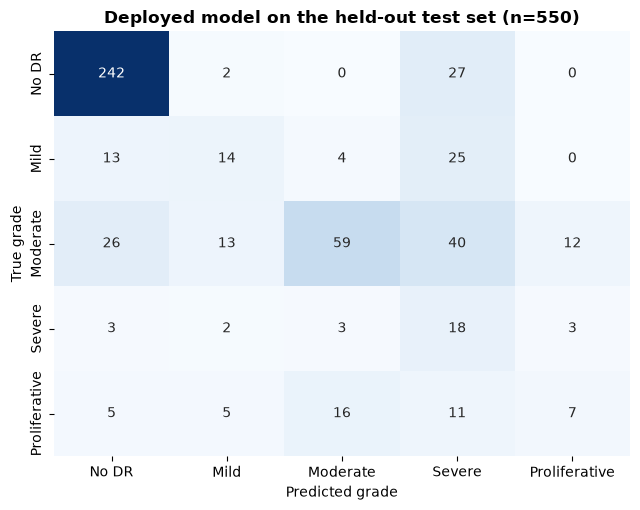

Recall by grade: No DR 0.89, Mild 0.25, Moderate 0.39, Severe 0.62, Proliferative 0.16


In [16]:
# ── 14.3 Confusion matrix ─────────────────────────────────────────────────
cm = np.array(m['confusion_matrix'])
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel('Predicted grade')
ax.set_ylabel('True grade')
ax.set_title(f'Deployed model on the held-out test set (n={len(y_true)})', fontweight='bold')
plt.tight_layout()
plt.show()
recalls = ', '.join(f'{CLASS_NAMES[g]} {r:.2f}' for g, r in enumerate(m['per_class_recall']))
print(f'Recall by grade: {recalls}')

cd314653a4d8  true grade 0  ->  predicted 0 (No DR, confidence 1.00)
    No diabetic retinopathy detected. Routine annual screening recommended.


05a5183c92d0  true grade 1  ->  predicted 1 (Mild DR, confidence 0.69)
    Mild non-proliferative DR. Re-screen in 6–12 months.


e1fb532f55df  true grade 3  ->  predicted 3 (Severe DR, confidence 0.84)
    Severe non-proliferative DR. URGENT specialist referral required.


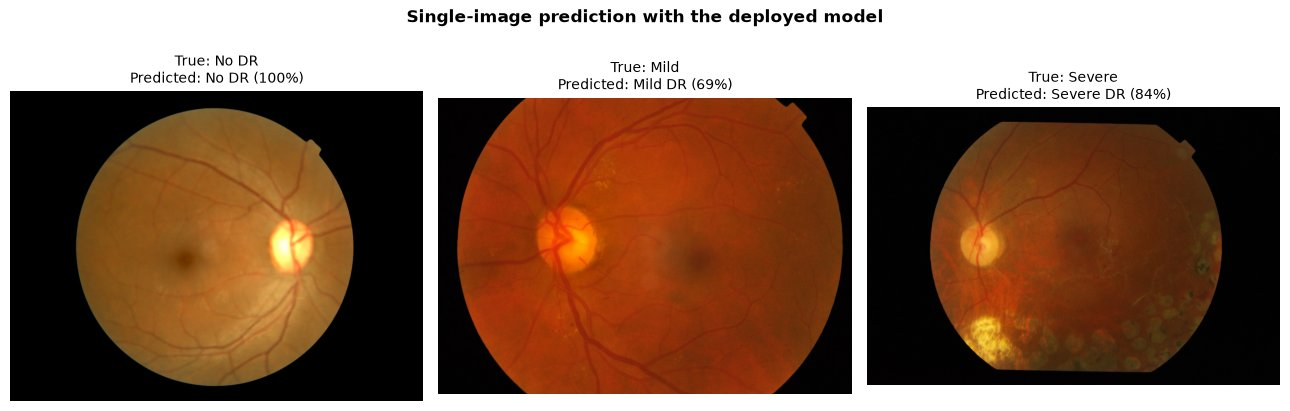

In [17]:
# ── 14.4 Prediction function: one fundus image in, a graded result out ─────
# app_pred.predict_image is the function behind the app's /api/predict endpoint.
demo = [('cd314653a4d8', 0), ('05a5183c92d0', 1), ('e1fb532f55df', 3)]   # held-out images
assert all(i in set(test_app['id_code']) for i, _ in demo)

fig, axes = plt.subplots(1, len(demo), figsize=(13, 4.6))
for ax, (id_code, true_grade) in zip(axes, demo):
    path = TRAIN_IMAGES_DIR / f'{id_code}.png'
    result = app_pred.predict_image(deployed, path)
    ax.imshow(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB))
    ax.axis('off')
    ax.set_title(f'True: {CLASS_NAMES[true_grade]}\n'
                 f'Predicted: {result["grade_label"]} ({result["confidence"]:.0%})', fontsize=10)
    print(f'{id_code}  true grade {true_grade}  ->  predicted {result["predicted_grade"]} '
          f'({result["grade_label"]}, confidence {result["confidence"]:.2f})')
    print(f'    {result["clinical_note"]}')
plt.suptitle('Single-image prediction with the deployed model', fontweight='bold')
plt.tight_layout()
plt.show()

### 14.5 Why these numbers differ from the Exp 5 row in Section 10

Section 10 prints Exp 5 at QWK 0.711 and accuracy 0.673. Those outputs come from the training
session that produced this notebook's saved outputs. The model file committed with the app does
not reproduce that row: evaluated directly above on the same 550 held-out images, it scores
**QWK 0.588, accuracy 0.618, AUC 0.839, weighted F1 0.625 and Grade 3+4 recall 0.390**. Training
a deep network is not bit-for-bit reproducible between runs, and the saved checkpoint comes from
a different session than the printed row. The app, its README and its Insights page report the
measured numbers above.

What they show: the deployed model recognises No DR reliably (recall 0.89) but separates the four
disease grades poorly, Proliferative DR worst of all (recall 0.16). The app's Insights page links
part of this to how the images were captured: No DR photographs are mostly small and square, the
disease grades mostly large 4:3 images, a difference the model can use as a shortcut.